In [3]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from helper_functions import imputer

from helper_functions.visualizations import *

data = pd.read_csv("../../preliminar_phase_submision/training_data/SyntheticData_Training.csv")
dictionary = pd.read_csv("tmp_datasets/DataDictionary.csv")
target = "inhospital_mortality"

NUMERICAL_COLUMNS = dictionary[dictionary.Category.str.contains('Continuous')]['Feature']
data[NUMERICAL_COLUMNS] = data[NUMERICAL_COLUMNS].apply(pd.to_numeric)

ORDINAL_MAPPING = {
    'oxygenavail_adm': {
        "Oxygen not available": 0,
        "Oxygen available but not enough": 1,
        "Oxygen available and not being used": 2,
        "Oxygen available and being used": 3
    },
    'bcsmotor_adm': {
        "No response or inappropriate response": 2,
        "Withdraws limb from painful stimulus": 1,
        "Localizes painful stimulus": 0
    },
    'bcsverbal_adm': {
        "No vocal response to pain": 2,
        "Moan or abnormal cry with pain": 1,
        "Cries appropriately with pain, or, if verbal, speaks": 0
    },
    'vaccpneumoc_adm': {
        "0 doses": 3,
        "1 dose": 2,
        "2 doses": 1,
        "3 doses": 0,
        "Unknown": -1
    },
    'vaccdpt_adm': {
        "0 doses": 3,
        "1 dose": 2,
        "2 doses": 1,
        "3 doses": 0,
        "Unknown": -1
    },
    'priorhosp_adm': {
        "> 1 year": 4,
        "1 month - 1 year": 3,
        "7 days - 1 month": 2,
        "< 7 days": 1,
        "Never": 0,
        "Dont know": -1
    },
    'prioryearwheeze_adm': {
        "Not applicable (< 6m old)": -2,
        "No": 0,
        "Yes": 1,
        "Dont know": -1
    },
    'prioryearcough_adm': {
        "Not applicable (child < 6m old)": -2,
        "No": 0,
        "Yes": 1,
        "Dont know": -1
    },
    'exclbreastfed_adm': {
        "never exclusively breastfed": 7,
        "1 month": 6,
        "2 months": 5,
        "3 months": 4,
        "4 months": 3,
        "5 months": 2,
        "6 months": 1,
        "More than 6 months": 0,
        "Unknown": -1
    },
    'totalbreastfed_adm': {
        "0-3 months": 3,
        "4-6 months": 2,
        "7-12 months": 1,
        ">12 months": 0,
        "Unknown": -1
    },
    'traveldist_adm': {
        "< 30 minutes": 0,
        "30 minutes - 1 hour": 1,
        "1 - 2 hours": 2,
        "2 - 3 hours": 3,
        "3 - 4 hours": 4,
        "4 - 8 hours": 5,
        "> 8 hours": 6
    },
    'caregiverage_adm': {
        "N/A (in care)": -2,
        "< = 18 years old": 0,
        "> 18 years old": 1,
        "> 50 years old": 2
    },
    'momedu_adm': {
        "No school": 4,
        "< = P3": 3,
        "P4-P7": 2,
        "S1-S6": 1,
        "Post secondary (including post S4 technical school)": 0,
        "Dont know": -1
    },
    'tobacco_adm': {
        "Never": 0,
        "Less than monthly": 1,
        "Monthly": 2,
        "Weekly": 3,
        "Daily": 4
    },
    'bednet_adm': {
        "Never": 2,
        "Sometimes": 1,
        "Always": 0
    },
    'feedingstatus_adm': {
        "Not feeding at all": 2,
        "Feeding poorly": 1,
        "Feeding well": 0
    },
    'birthattend_adm': {
        "Other": 4,
        "Relative": 3,
        "Traditional birth attendant": 2,
        "Nurse / midwife": 1,
        "Doctor / Clinical officer": 0
    },
    'travelmethod_adm': {
        "Other": 0,
        "Walking": 1,
        "Motorcycle": 2,
        "Taxi/special hire": 3,
        "Private vehicle": 4,
        "Ambulance": 5
    },
    'watersource_adm': {
        "Open source (unprotected, stagnant water, dam)": 0,
        "Slow running water": 1,
        "Fast running water": 2,
        "Bore hole": 3,
        "Protected spring": 4,
        "Municipal water": 5
    },
    'caregiver_adm_new': {
        "Other": 3,
        "Grandparent": 2,
        "Father": 1,
        "Mother": 0
    }
}

THREE_VALUE_ORDINAL_MAPPING = {
    'vaccmeasles_adm': {"Yes": 1, "No": 0, "Unknown": -1},
    'priorweekabx_adm': {"No": 0, "Dont know": -1, "Yes": 1},
    'priorweekantimal_adm': {"No": 0, "Yes": 1, "Dont know": -1},
    'diarrheaoften_adm': {"No": 0, "Yes": 1, "Dont know": -1},
    'tbcontact_adm': {"No": 0, "Yes": 1, "Dont know": -1},
    'nonexclbreastfed_adm': {"Formula+": 0, "Other+": 1, "N/A - exclusive breastfeeding": -1},
    'momhiv_adm': {"Negative": 0, "Unknown": -1, "Positive": 1}
}

NOMINAL_FEATURES = ['deliveryloc_adm', 'caregivermarried_adm', 'cookloc_adm',
                    'lightfuel_adm', 'badhealthduration_adm']

BINARY_FEATURES = ['admitabx_adm___1',  'admitabx_adm___10',  'admitabx_adm___11',  'admitabx_adm___12',
                   'admitabx_adm___13',  'admitabx_adm___14',  'admitabx_adm___15',  'admitabx_adm___16',
                   'admitabx_adm___17',  'admitabx_adm___18',  'admitabx_adm___19',  'admitabx_adm___2',
                   'admitabx_adm___20',  'admitabx_adm___21',  'admitabx_adm___3',  'admitabx_adm___4',
                   'admitabx_adm___5',  'admitabx_adm___6',  'admitabx_adm___7',  'admitabx_adm___8',
                   'admitabx_adm___9',  'bcgscar_adm',  'bcseye_adm',  'birthdetail_adm___1',
                   'birthdetail_adm___2',  'birthdetail_adm___3',  'birthdetail_adm___4',  'birthdetail_adm___5',
                   'birthdetail_adm___6',  'caprefill_adm',  'comorbidity_adm___1',  'comorbidity_adm___10',
                   'comorbidity_adm___11',  'comorbidity_adm___12',  'comorbidity_adm___2',  'comorbidity_adm___3',
                   'comorbidity_adm___4',  'comorbidity_adm___5',  'comorbidity_adm___6',  'comorbidity_adm___7',
                   'comorbidity_adm___8',  'comorbidity_adm___9',  'cookfuel_adm___1',  'cookfuel_adm___2',
                   'cookfuel_adm___3',  'cookfuel_adm___4',  'cookfuel_adm___5',  'cookfuel_adm___6',
                   'cookfuel_adm___7',  'cookfuel_adm___8',  'duedateknown_adm',  'hctpretransfusion_adm',
                   'hivstatus_adm',  'malariastatuspos_adm',  'momagefirstpregknown_adm',  'momageknown_adm',
                   'momalive_adm',  'respdistress_adm',  'sex_adm',  'spo2onoxy_adm',  'symptoms_adm___1',
                   'symptoms_adm___10',  'symptoms_adm___11',  'symptoms_adm___12',  'symptoms_adm___13',
                   'symptoms_adm___14',  'symptoms_adm___15',  'symptoms_adm___16',  'symptoms_adm___17',
                   'symptoms_adm___18',  'symptoms_adm___2',  'symptoms_adm___3',  'symptoms_adm___4',
                   'symptoms_adm___5',  'symptoms_adm___6',  'symptoms_adm___7',  'symptoms_adm___8',
                   'symptoms_adm___9',  'vaccdptsource_adm',  'vaccmeaslessource_adm',  'vaccpneumocsource_adm',
                   'waterpure_adm']

In [4]:
multi_imputer = imputer.CustomIterativeImputer()
X = data.drop(columns=['inhospital_mortality', 'studyid_adm', 'lengthadm'],
               errors='ignore')
y = data["inhospital_mortality"]
multi_imputer.fit(X)
df = multi_imputer.transform(X)
df[target] = data[target]




757 ms ± 21.4 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)

### Analyzing the columns to see how they correlate with the target
1. Preprocess the columns -> Scale the numerical columns and Numeralize the category columns.
2. Run the basic OLS (scikit) to see which columns are the most significant

In [30]:
non_binary_cats = [col for col in ORDINAL_MAPPING.keys()] \
+ NOMINAL_FEATURES \
+ [col for col in THREE_VALUE_ORDINAL_MAPPING.keys()] + ['age_group']

default_values = {'exclbreastfed_adm': 'Unknown',
            'totalbreastfed_adm': 'Unknown',
            'vaccmeaslessource_adm': 'Self report',
            'vaccpneumocsource_adm': 'Self report',
            'vaccdptsource_adm': 'Self report',
            'vaccpneumoc_adm': 'Unknown',
            'vaccmeasles_adm': 'Unknown',
            'vaccdpt_adm': 'Unknown',
            'priorweekantimal_adm': 'Dont know',
            'priorhosp_adm': 'Dont know',
            'prioryearwheeze_adm': 'Dont know',
            'travelmethod_adm': 'Other',
            'badhealthduration_adm': 'Unknown',
            'caregiver_adm_new': 'Other',
            'momhiv_adm': 'Unknown',
            'lightfuel_adm': 'Other',
            'momagefirstpregknown_adm': 'No',
            'waterpure_adm': 'No',
            'bednet_adm': 'Never'}

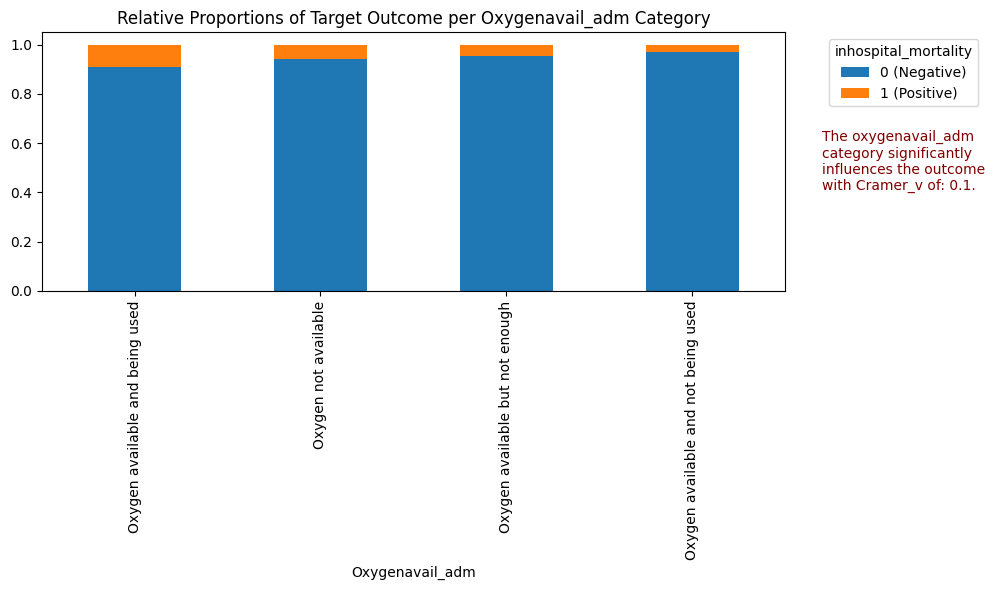

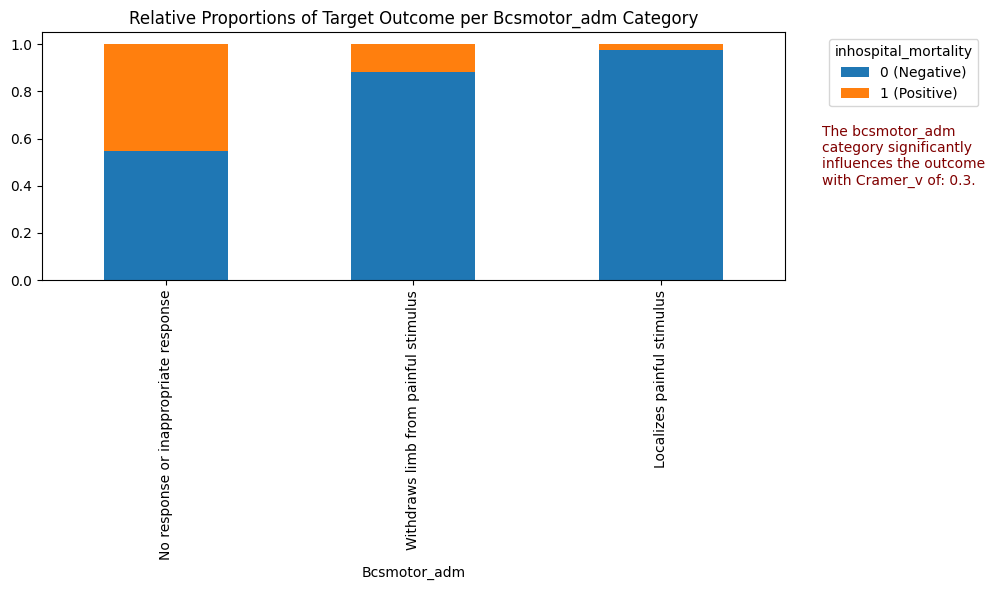

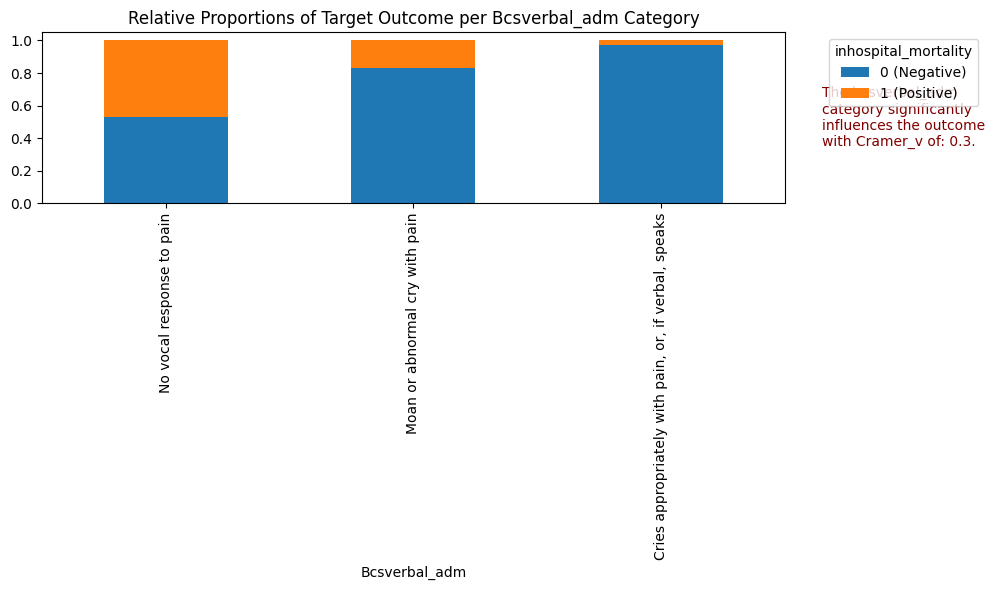

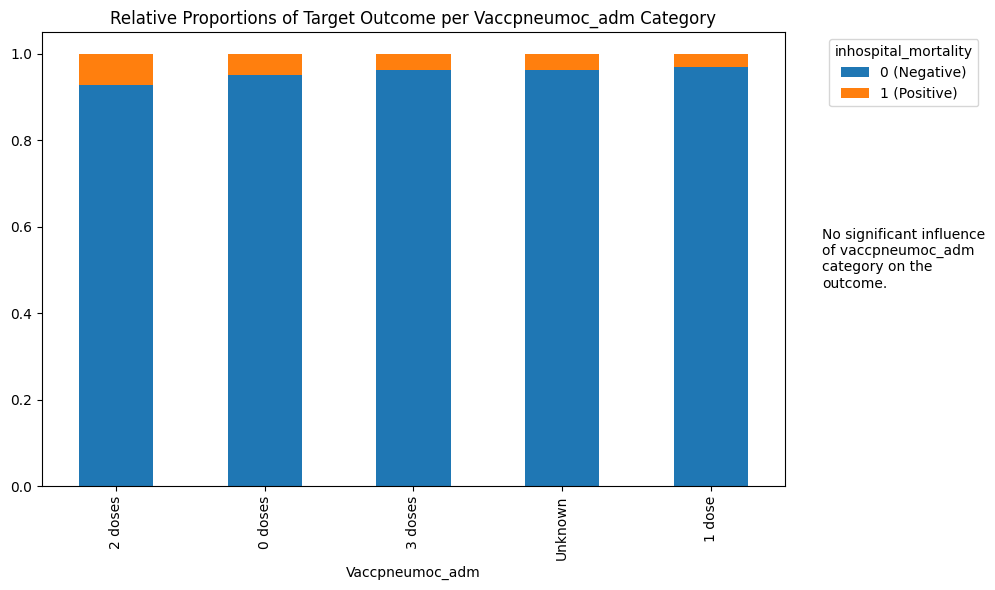

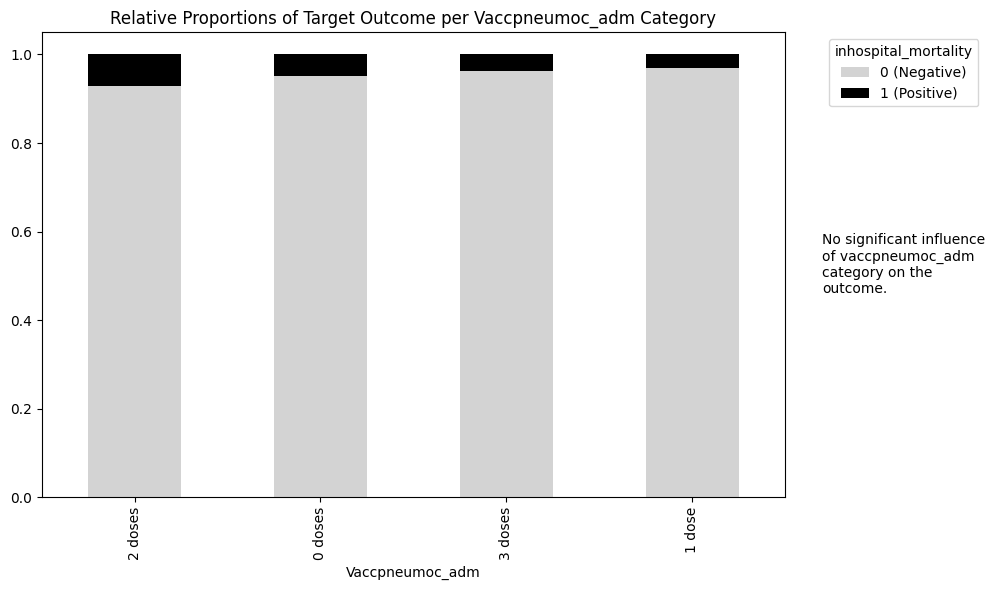

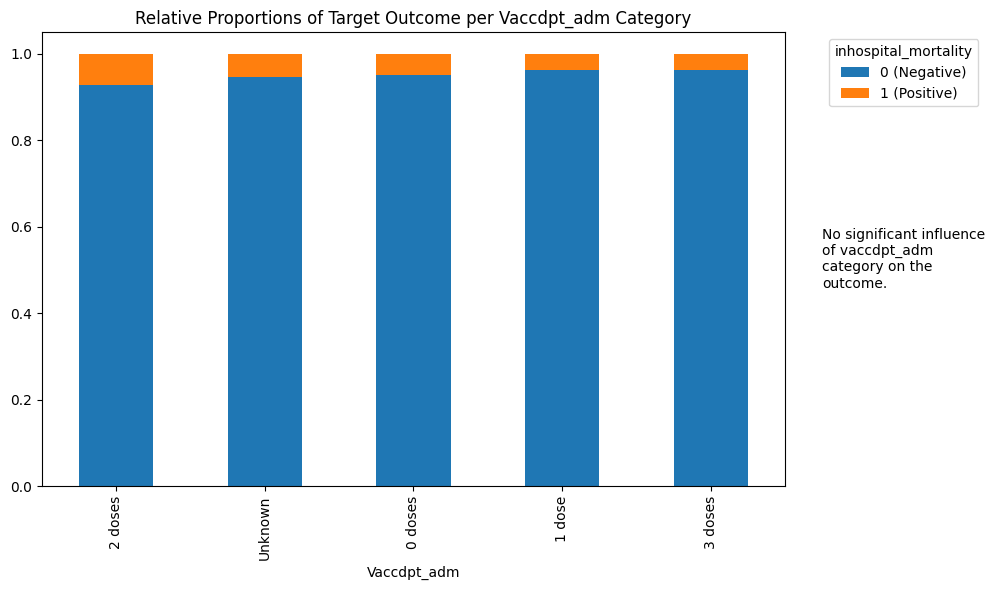

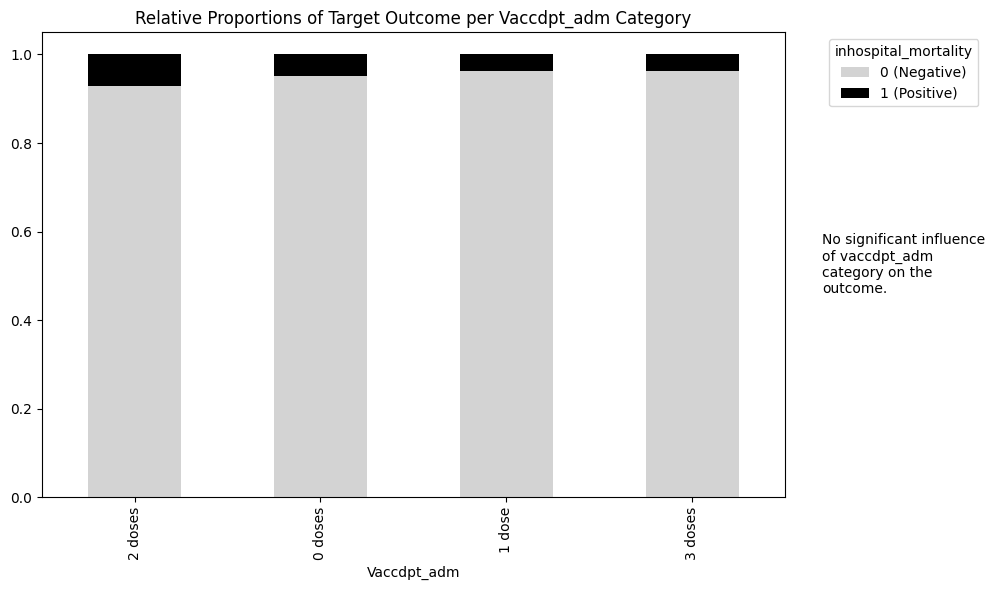

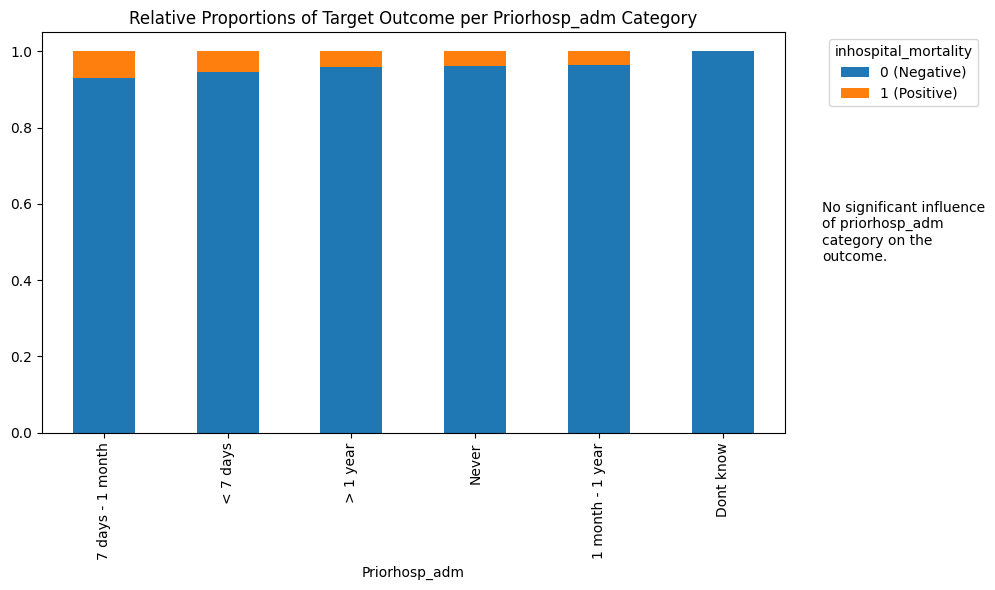

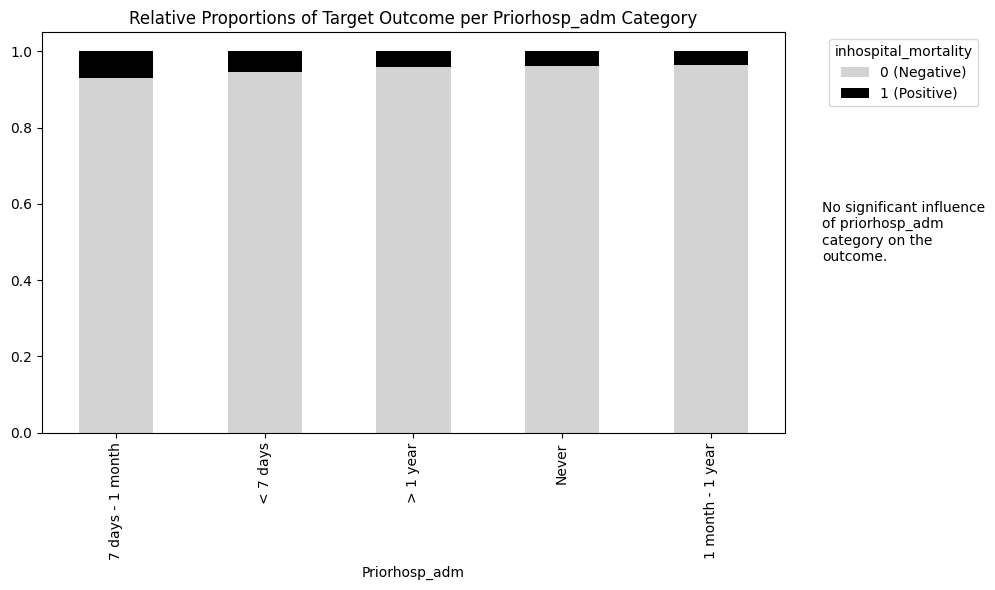

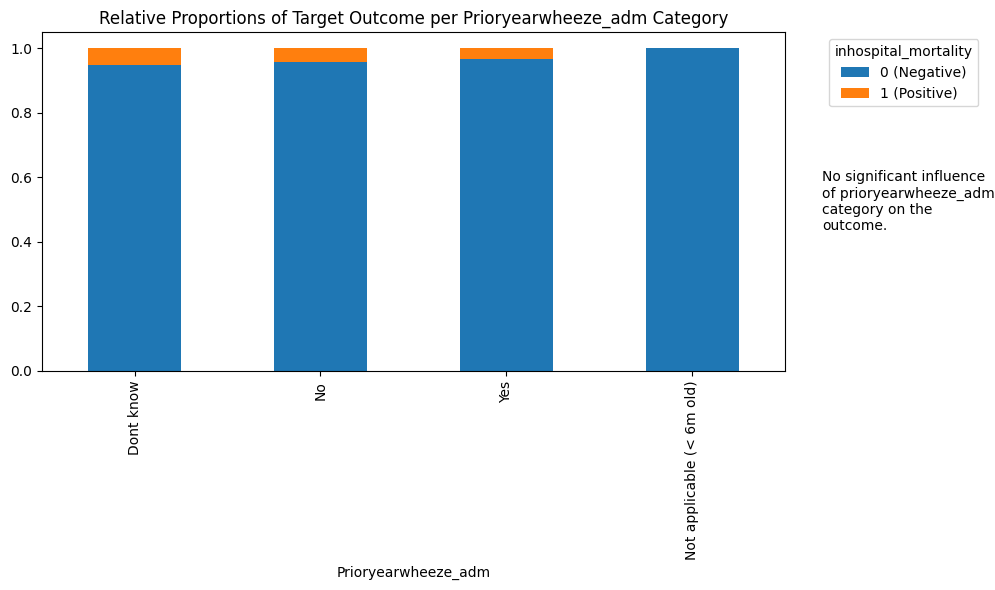

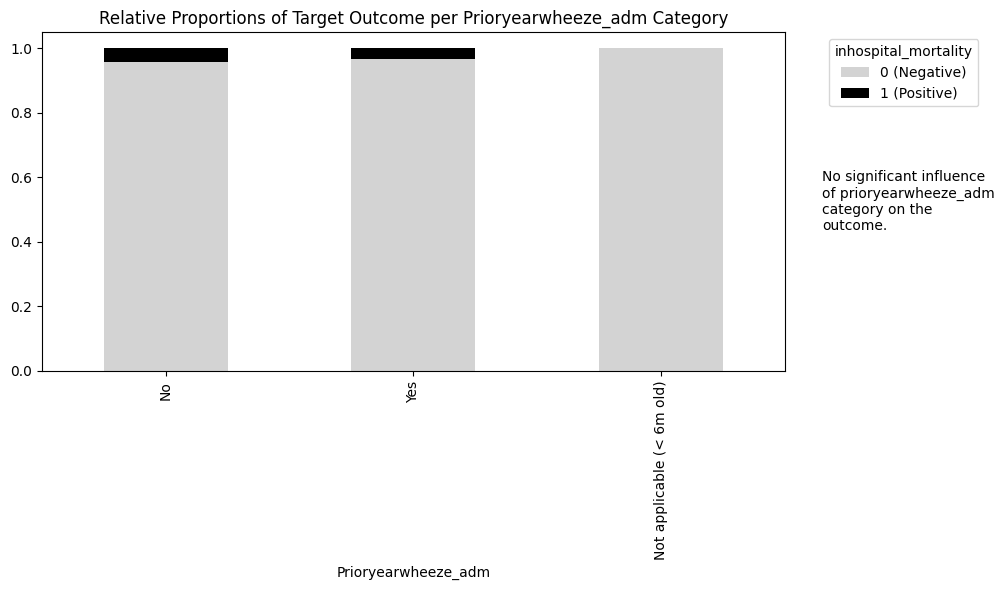

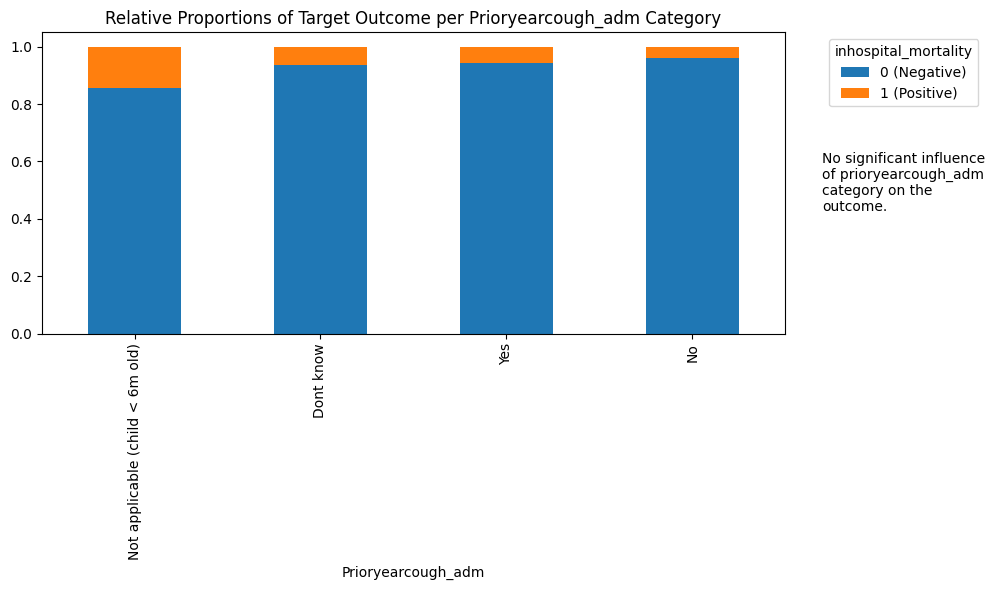

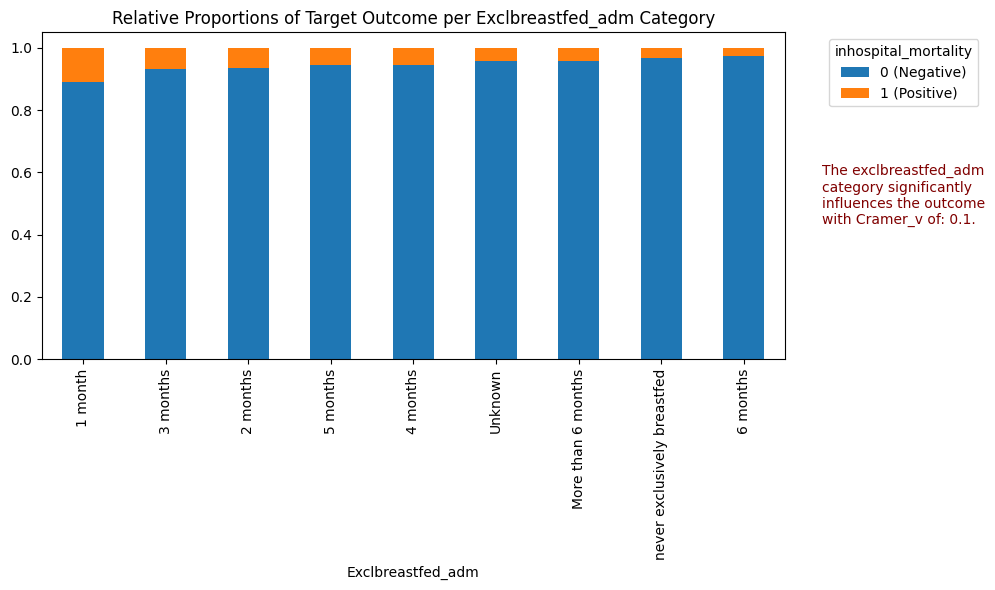

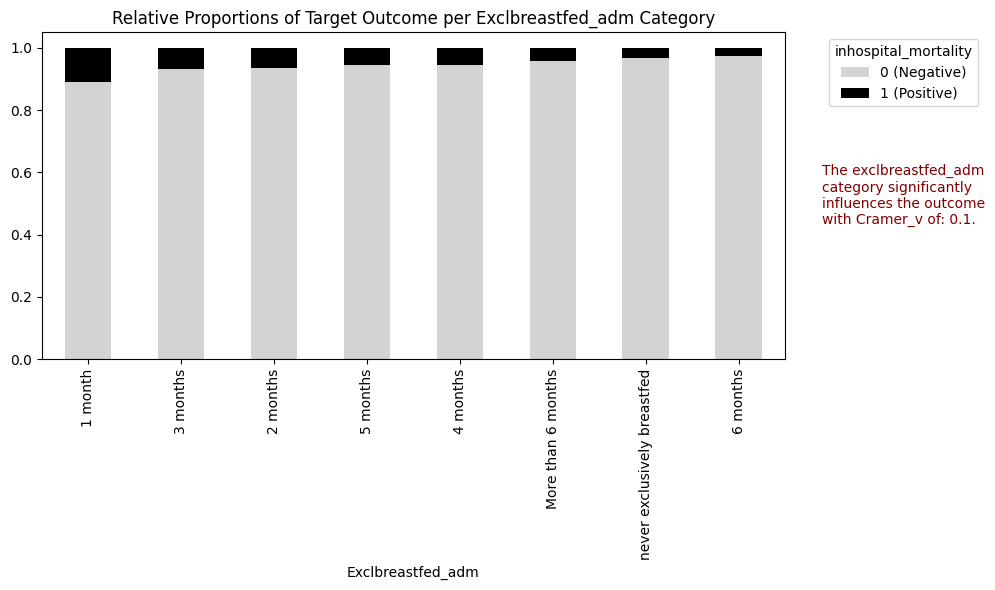

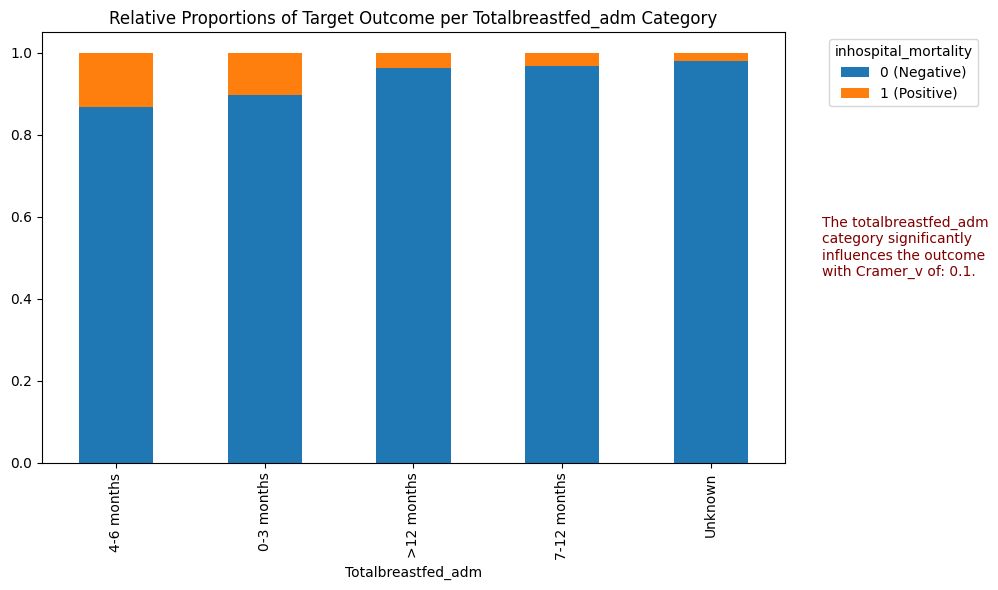

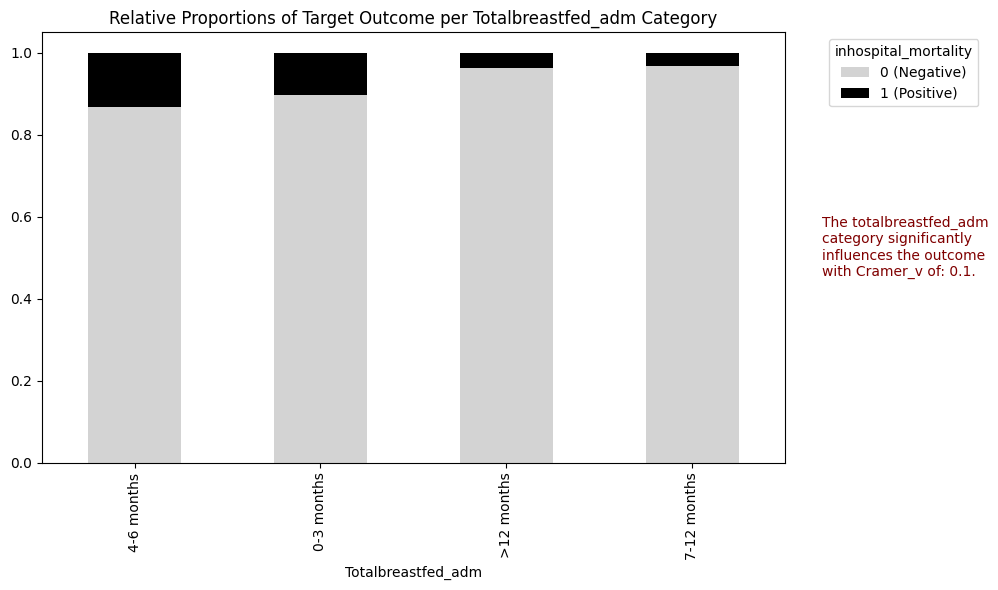

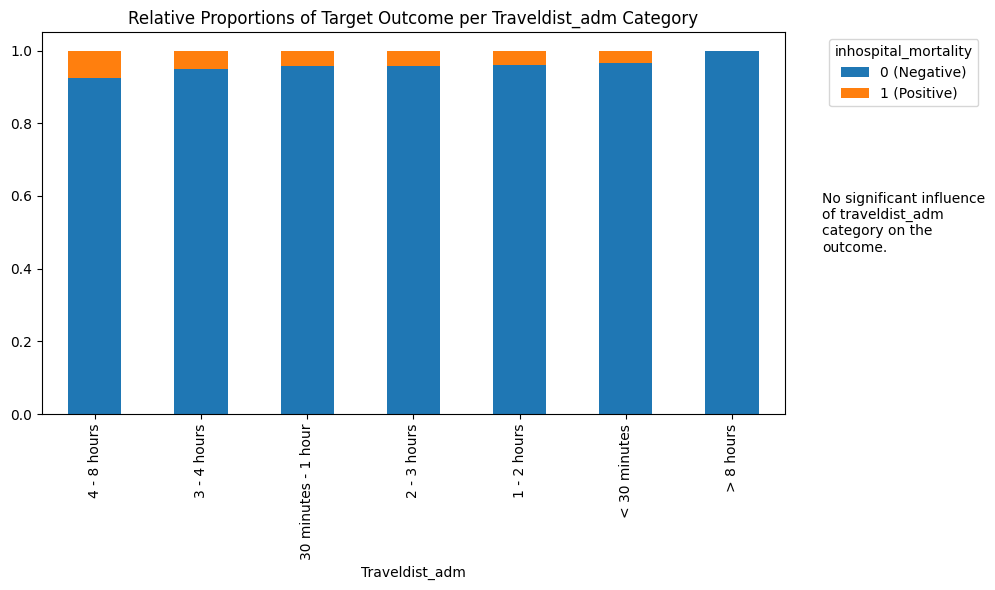

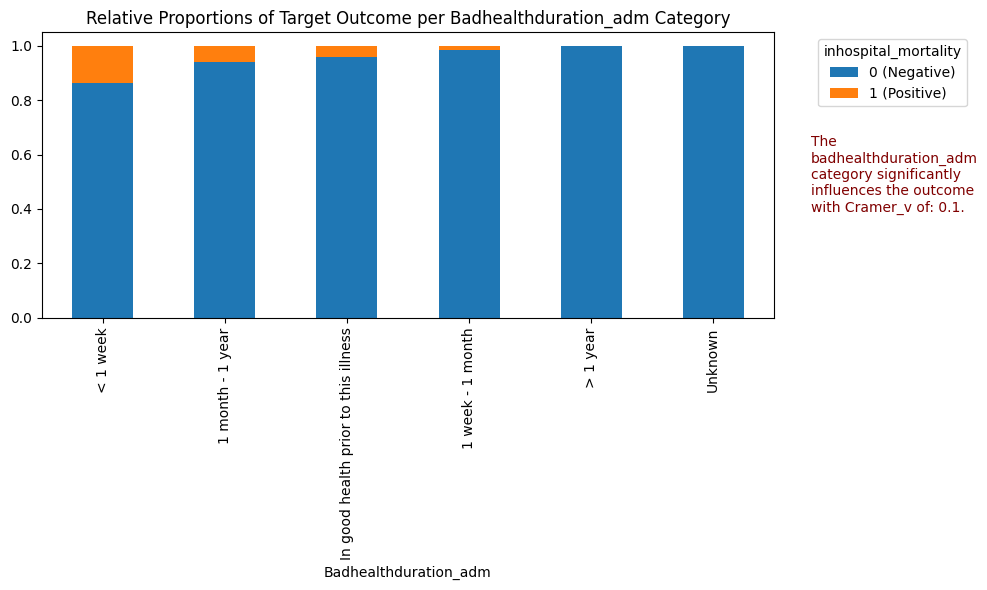

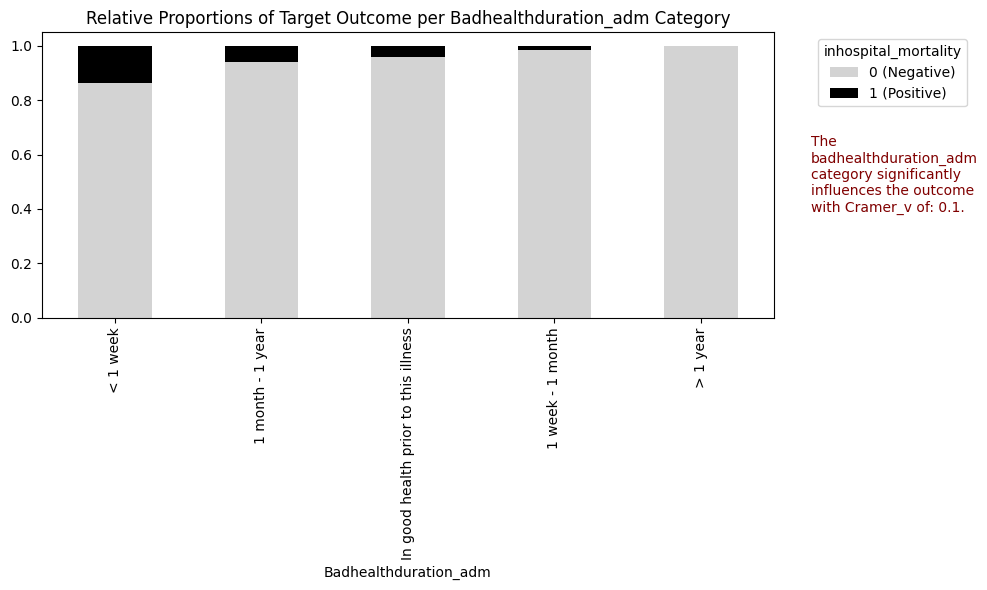

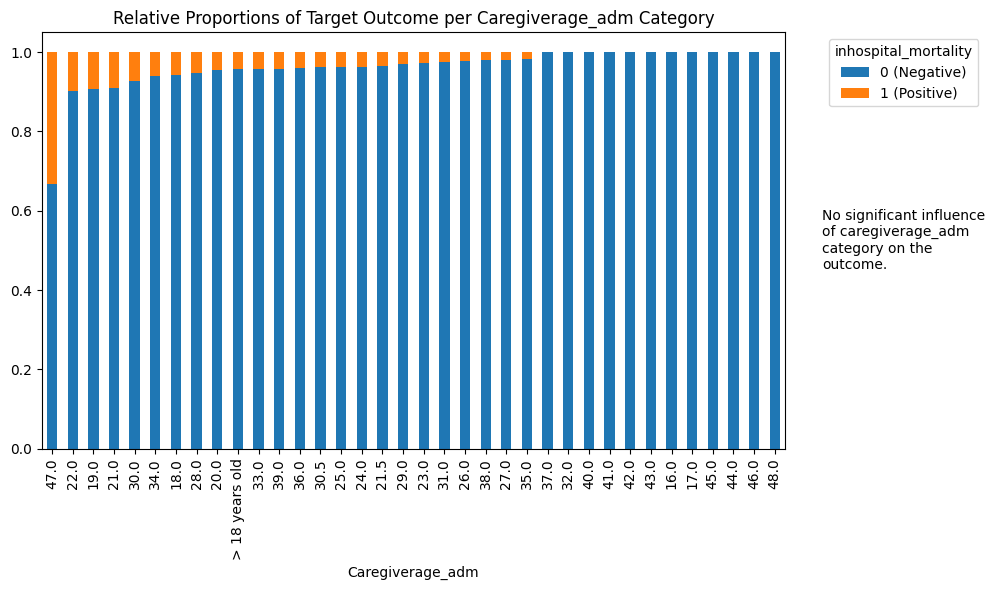

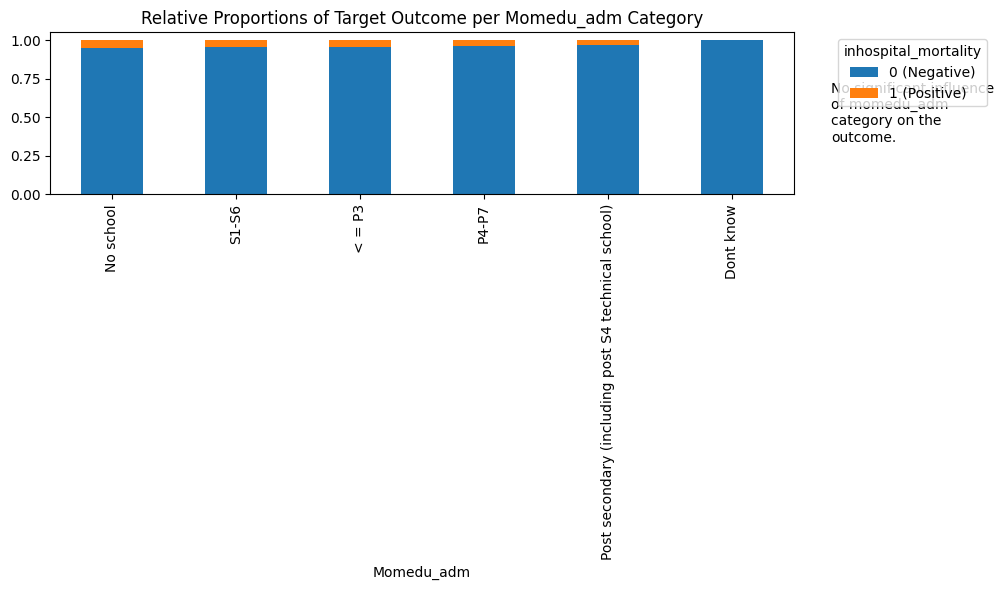

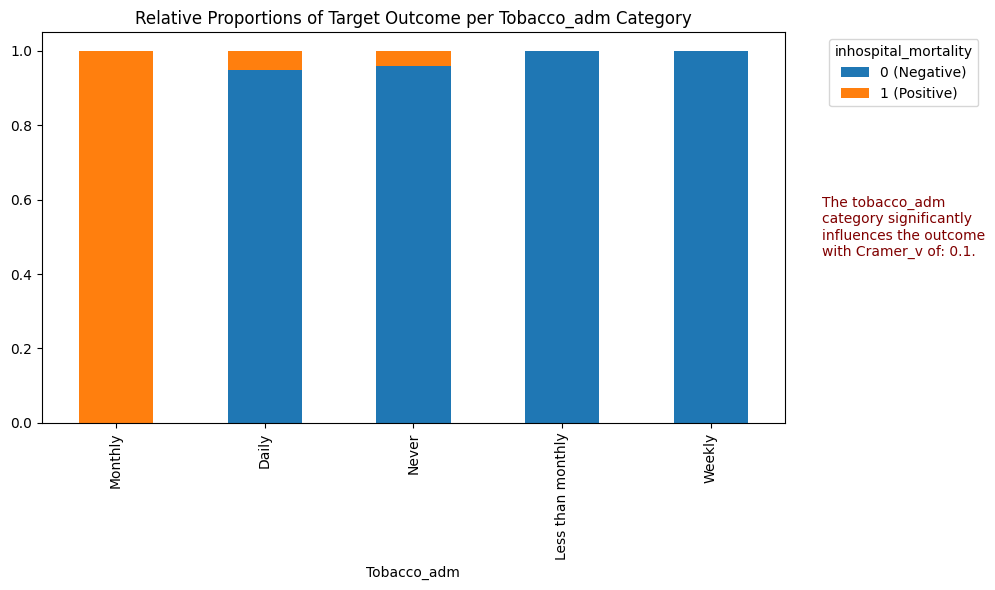

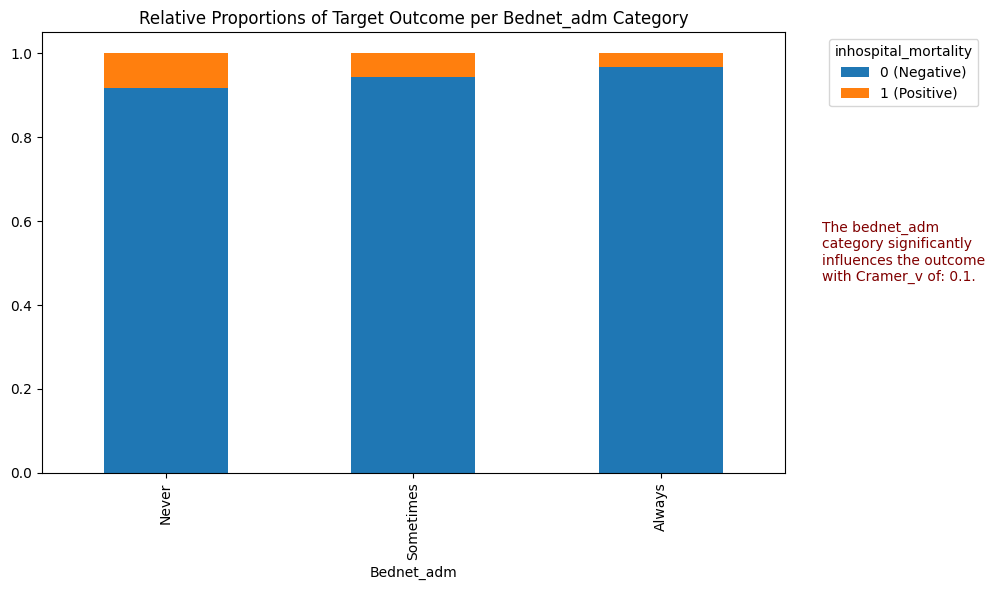

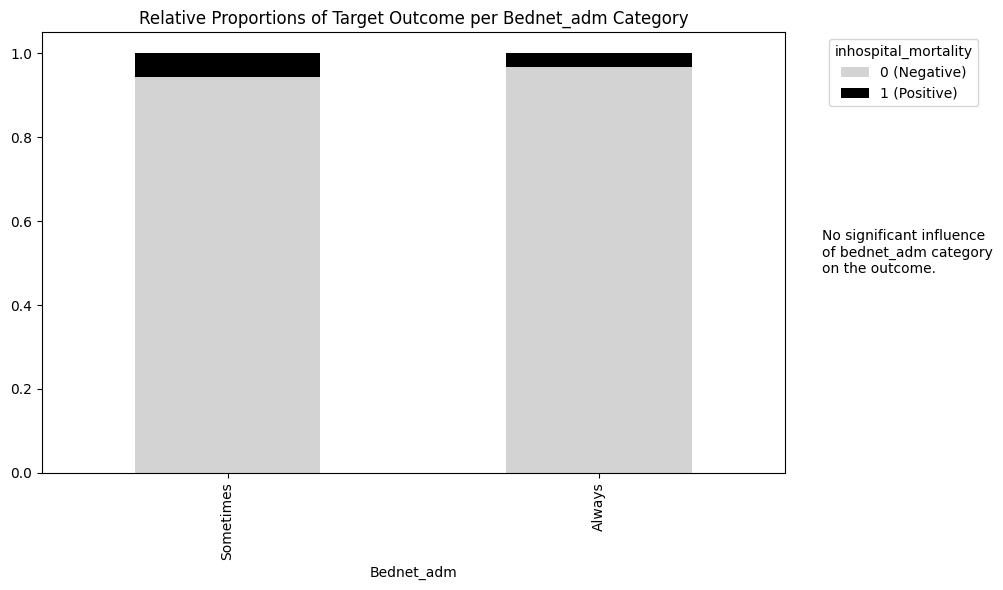

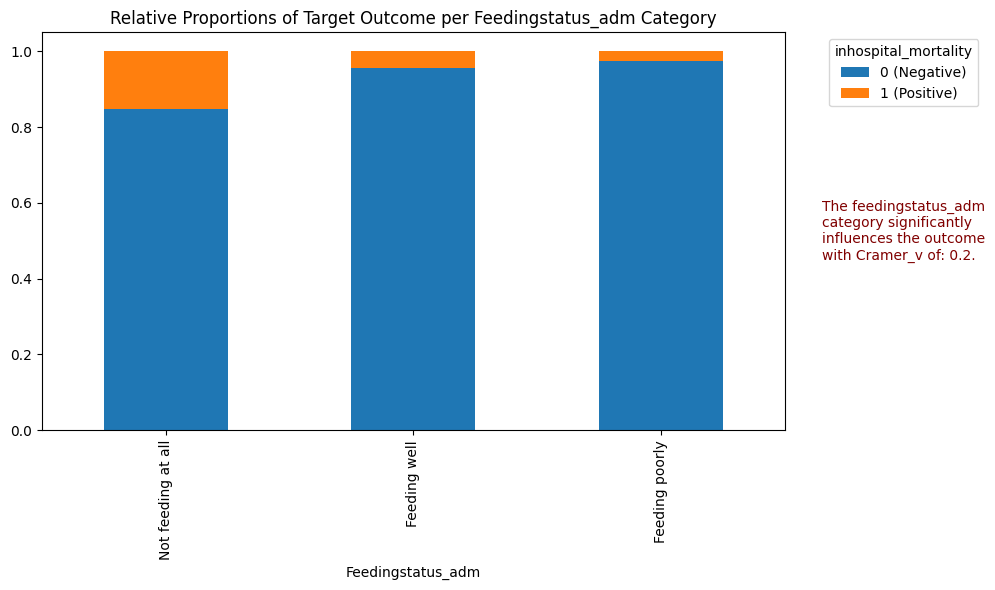

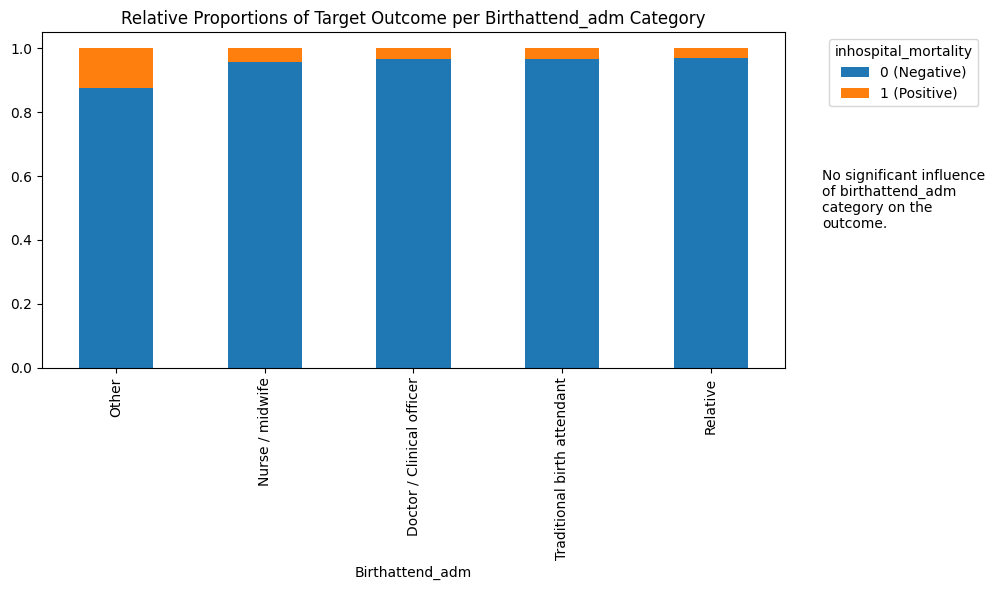

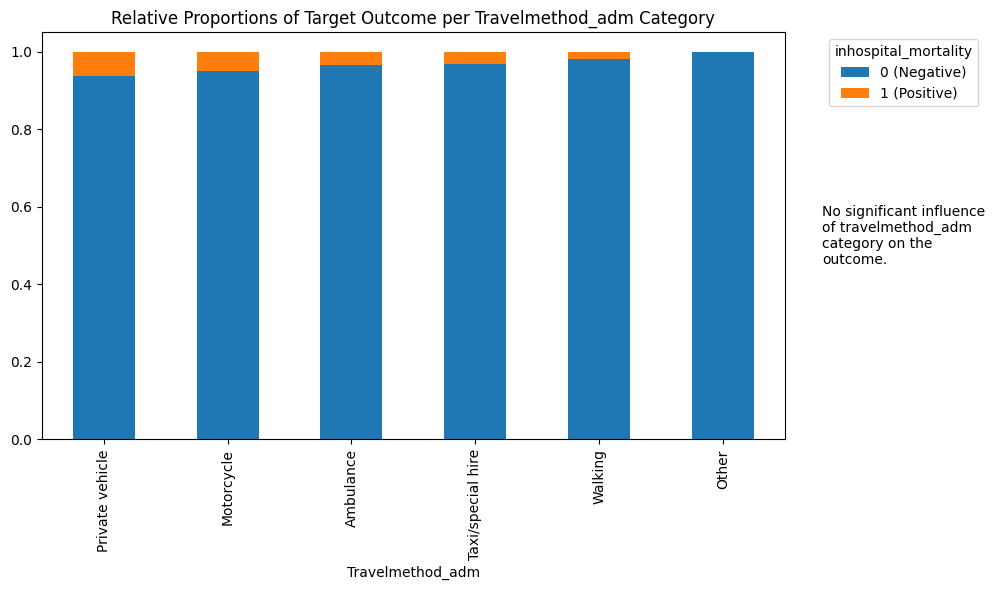

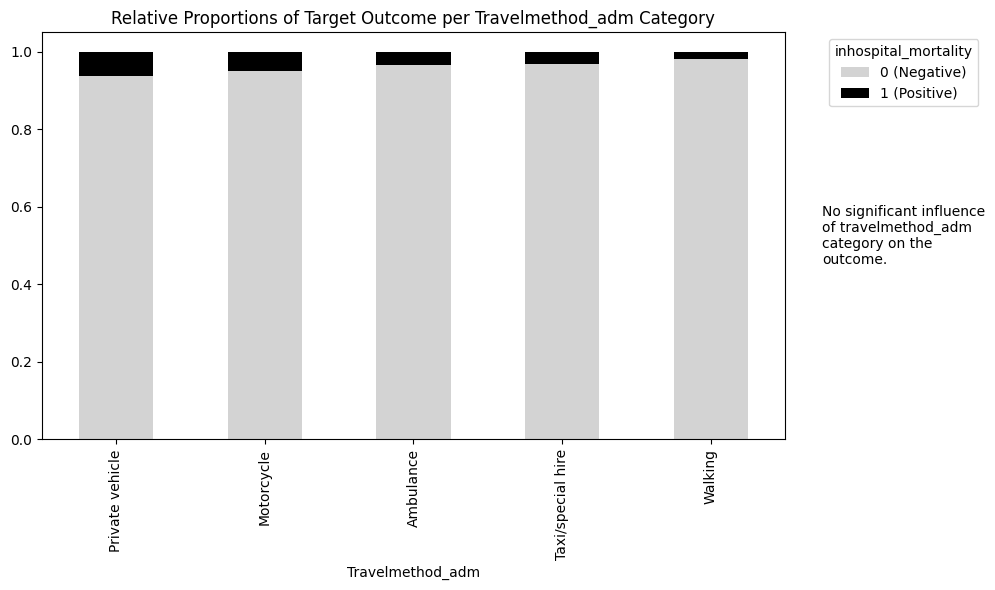

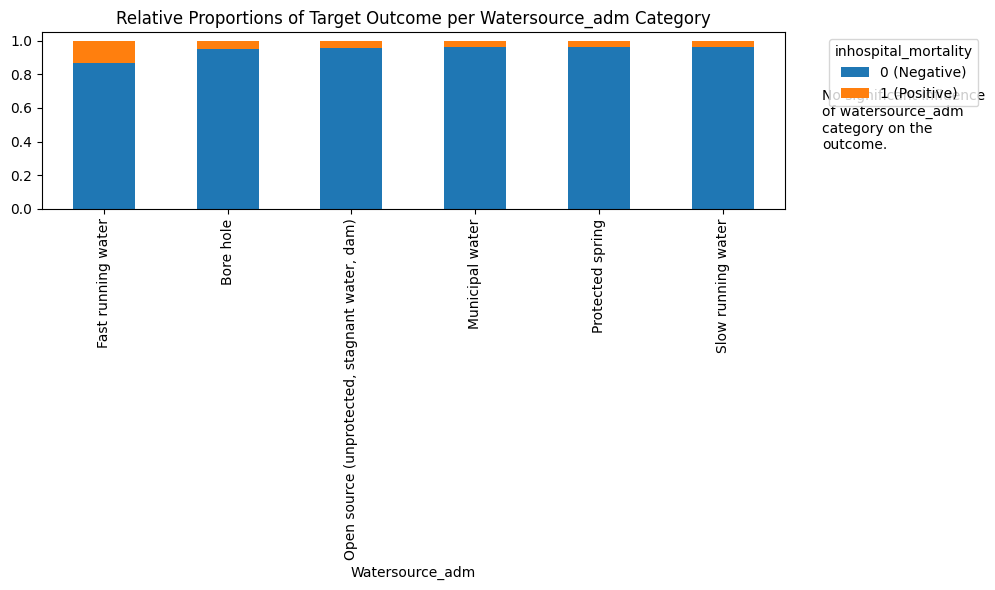

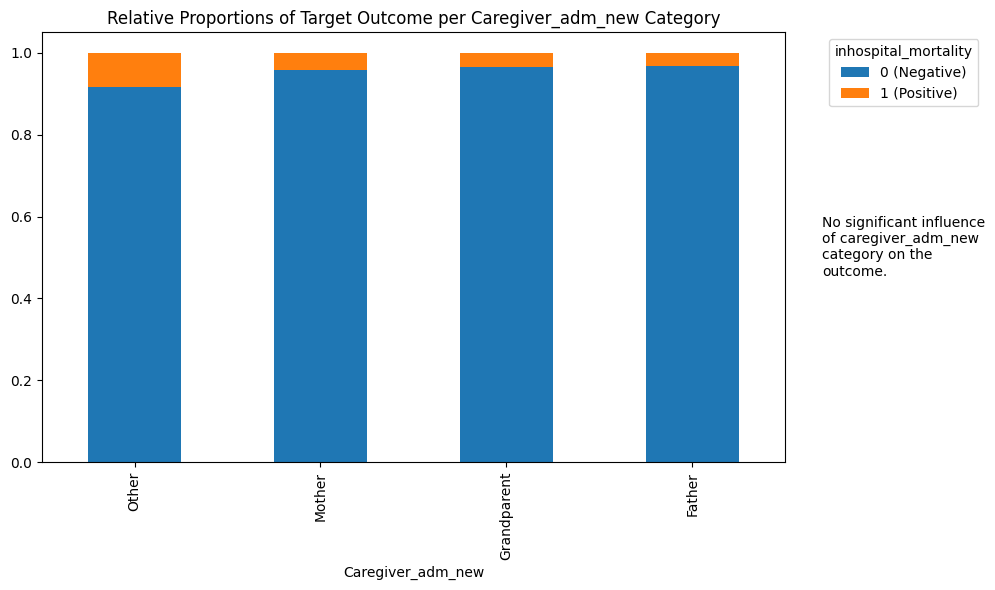

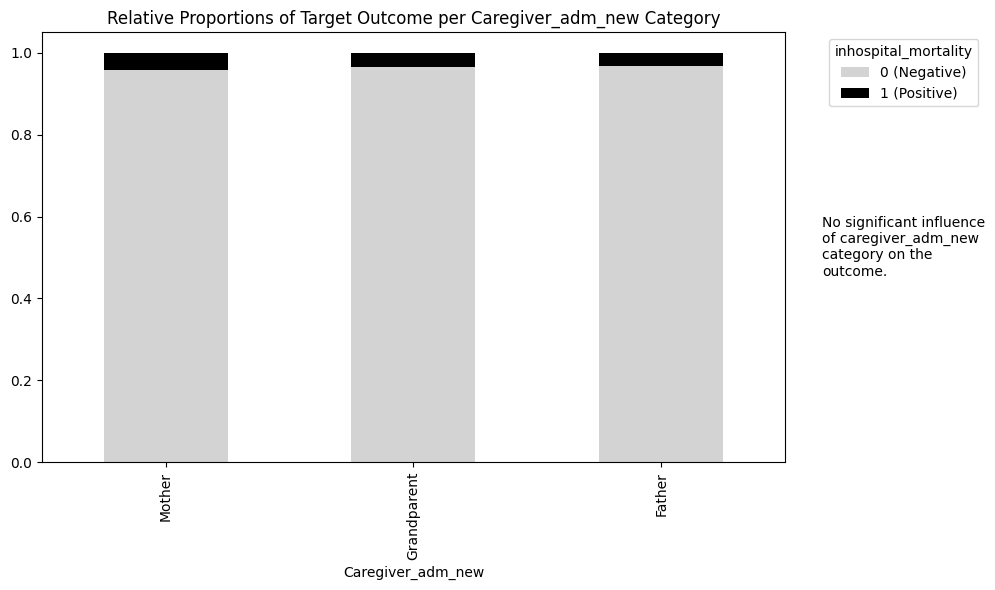

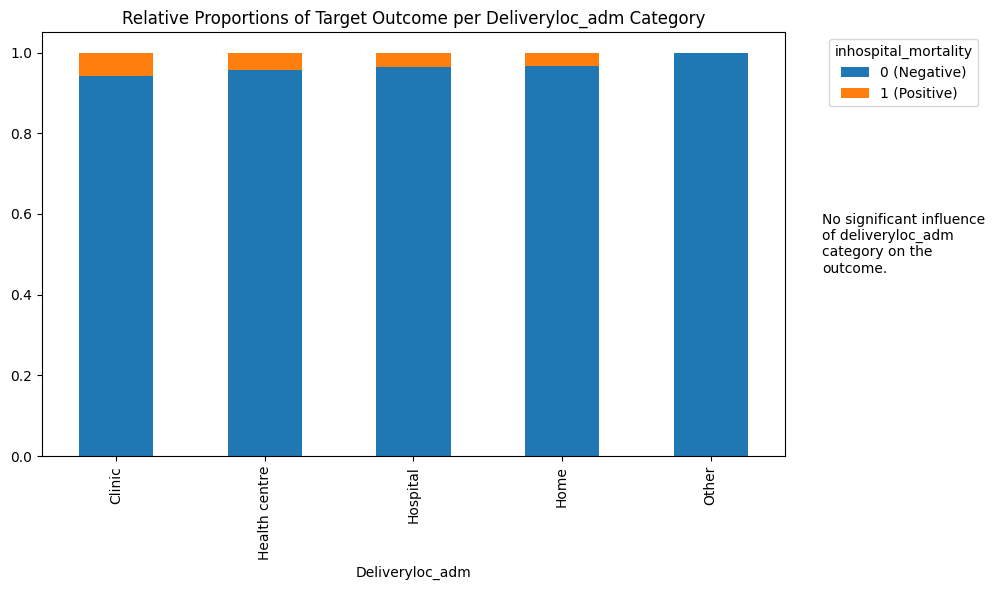

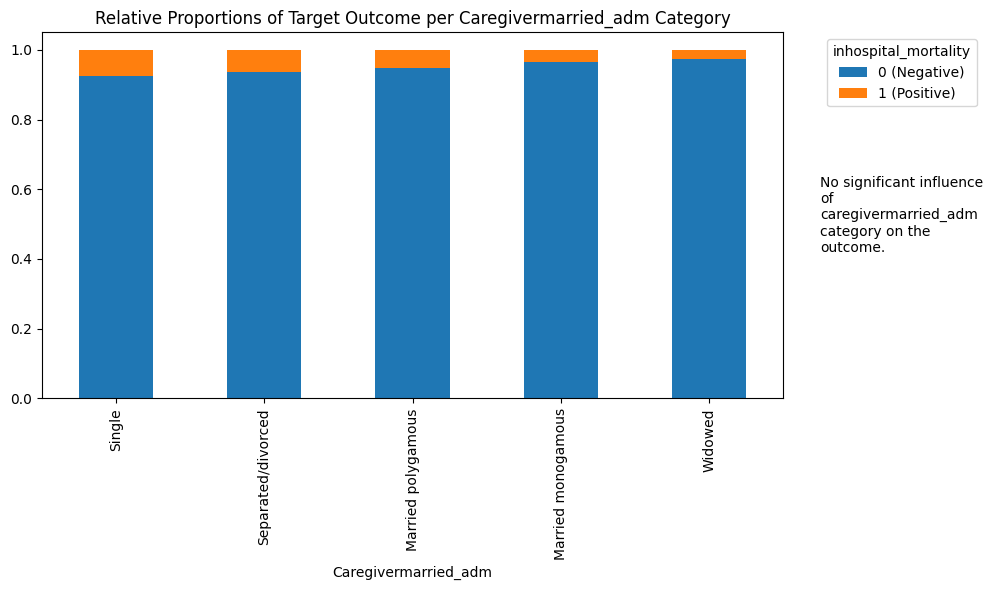

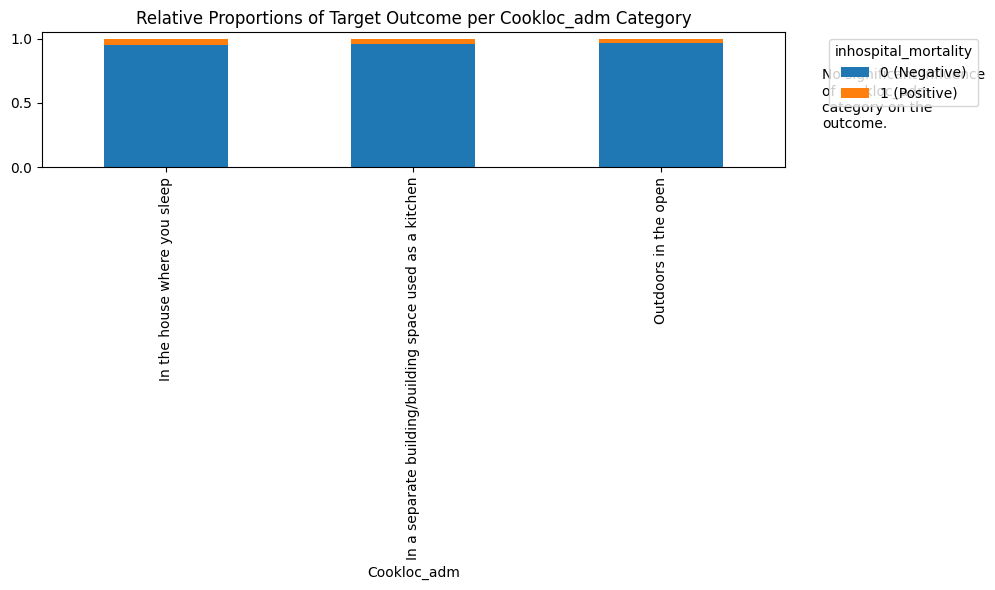

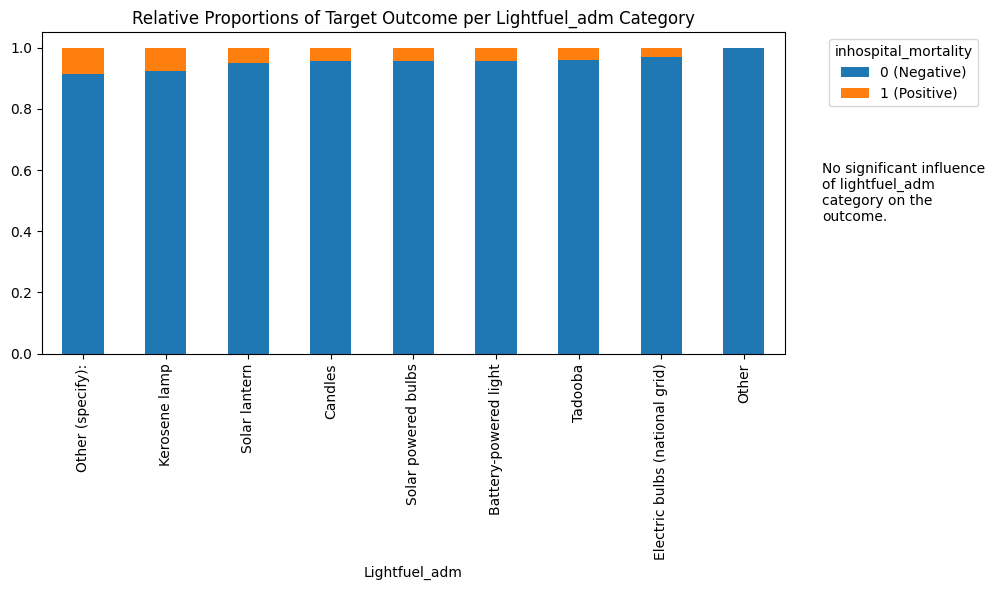

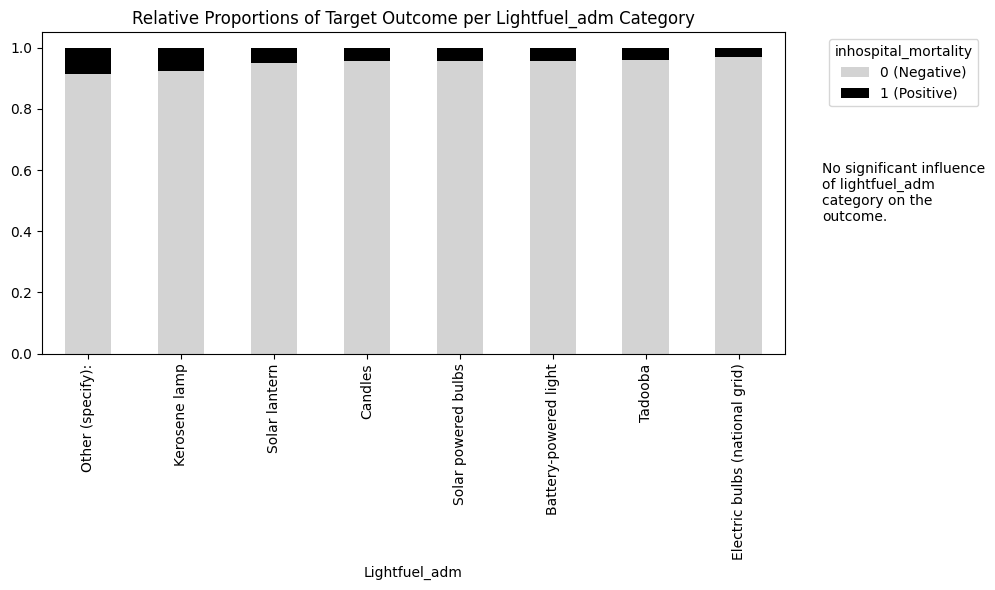

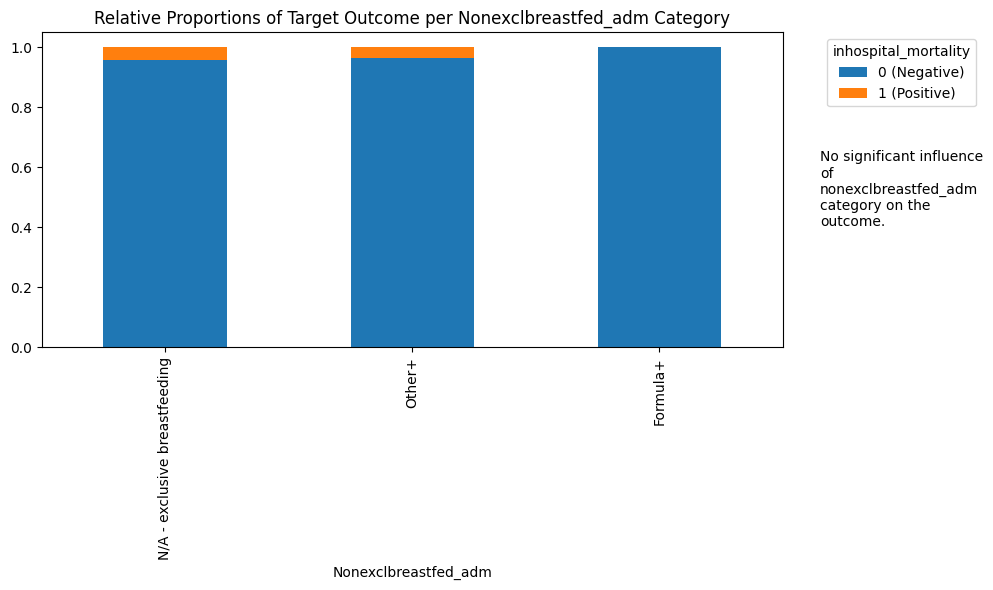

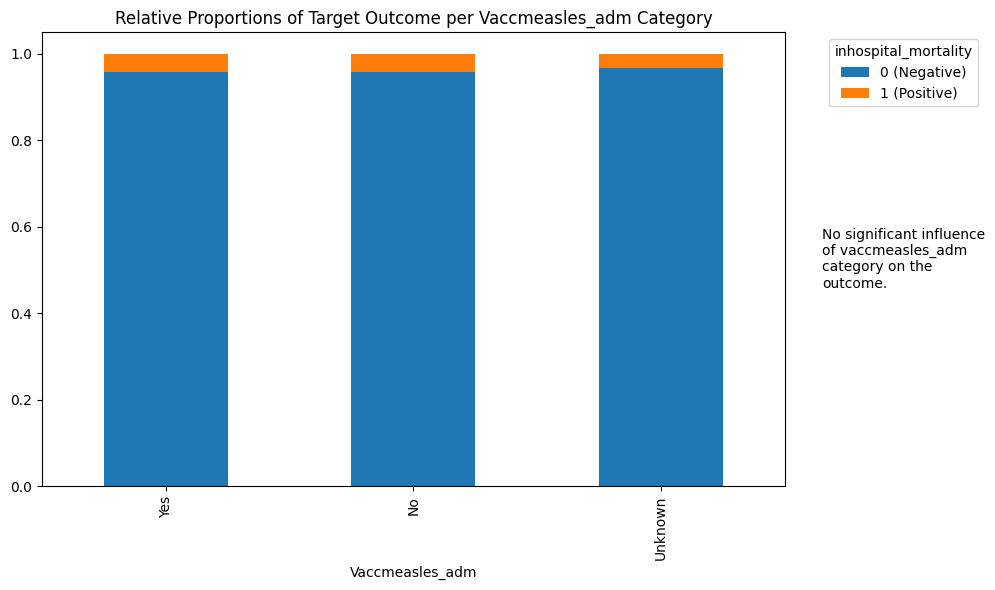

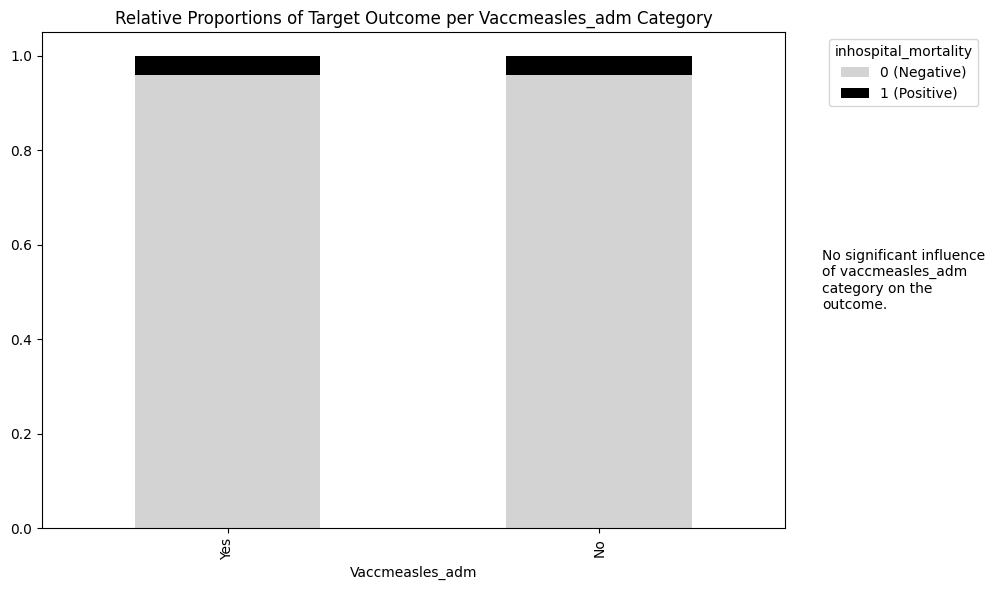

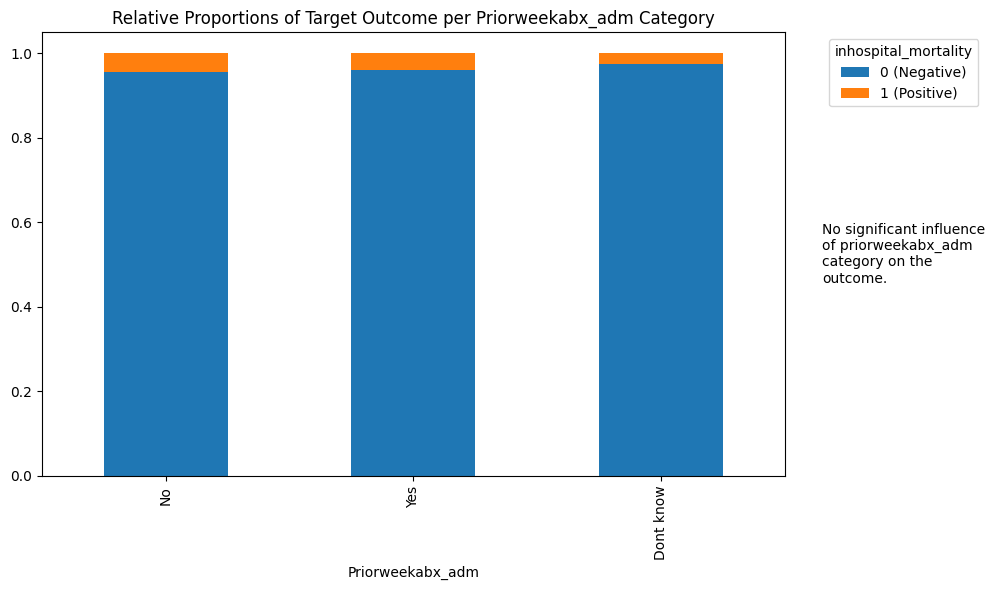

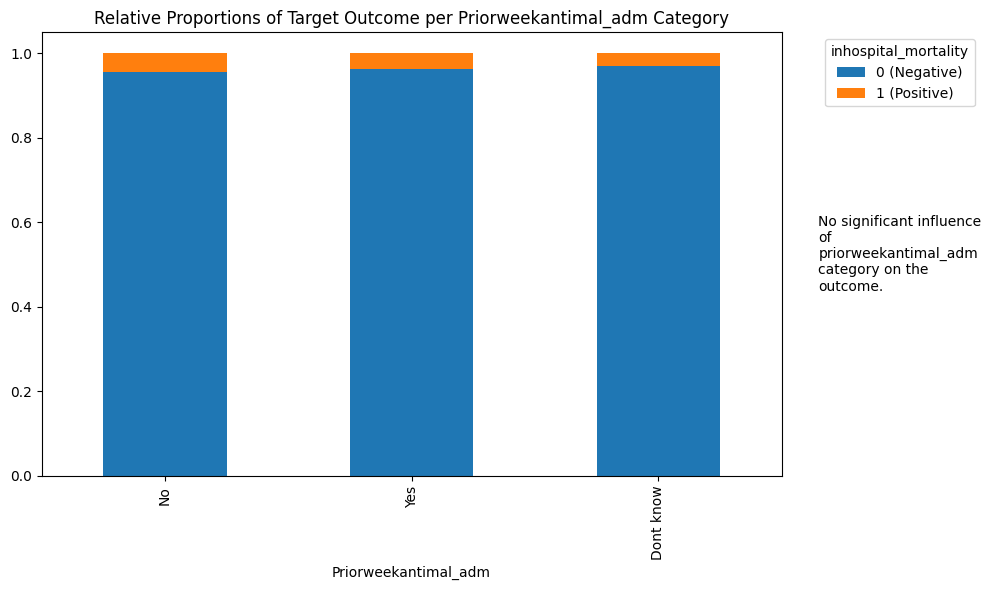

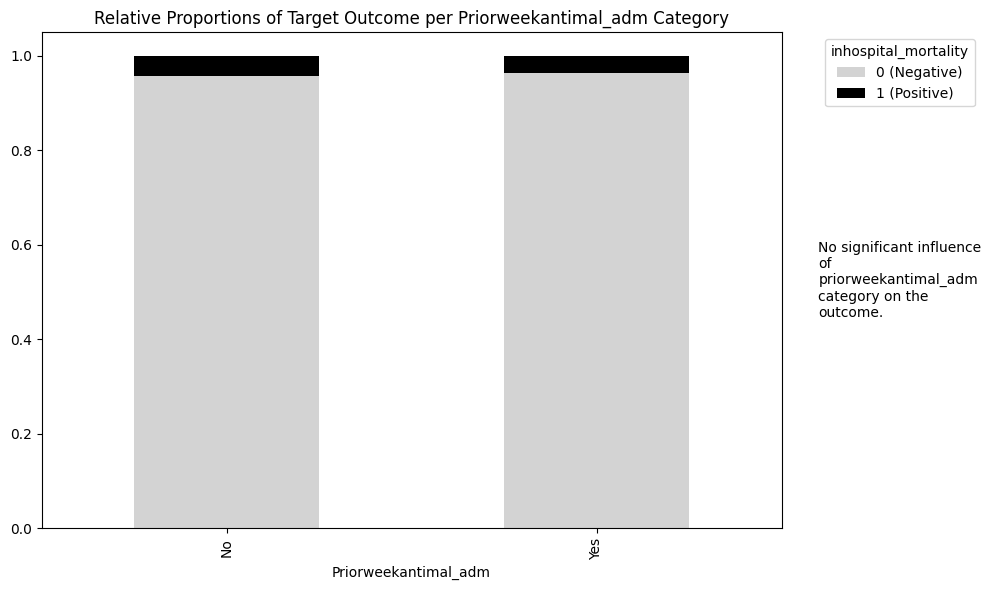

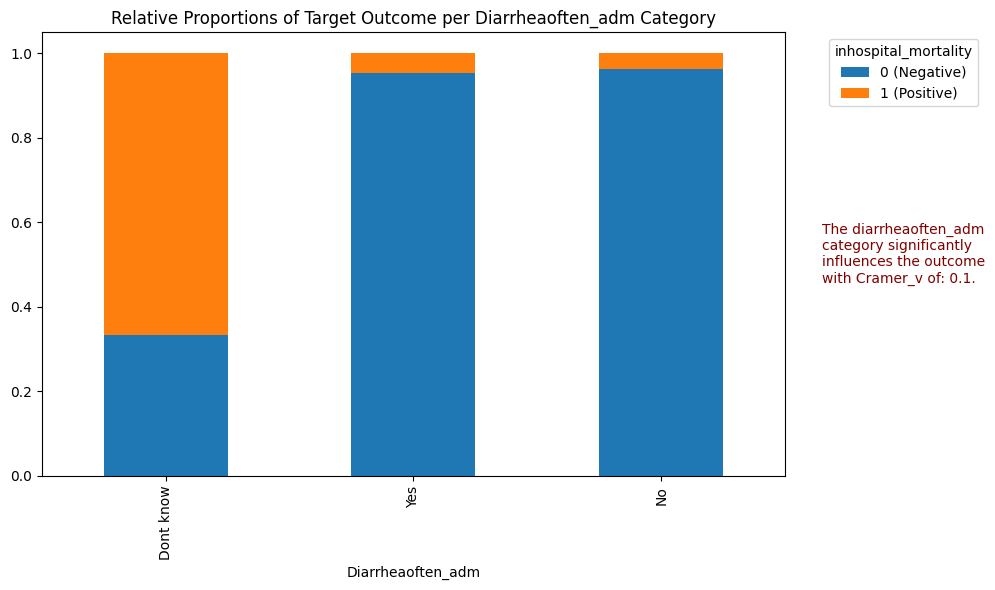

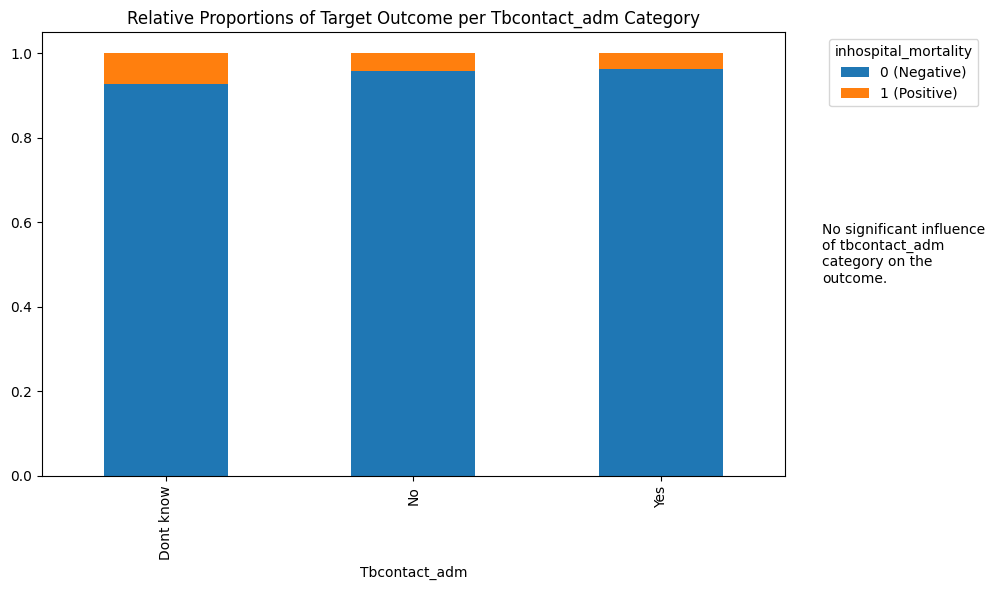

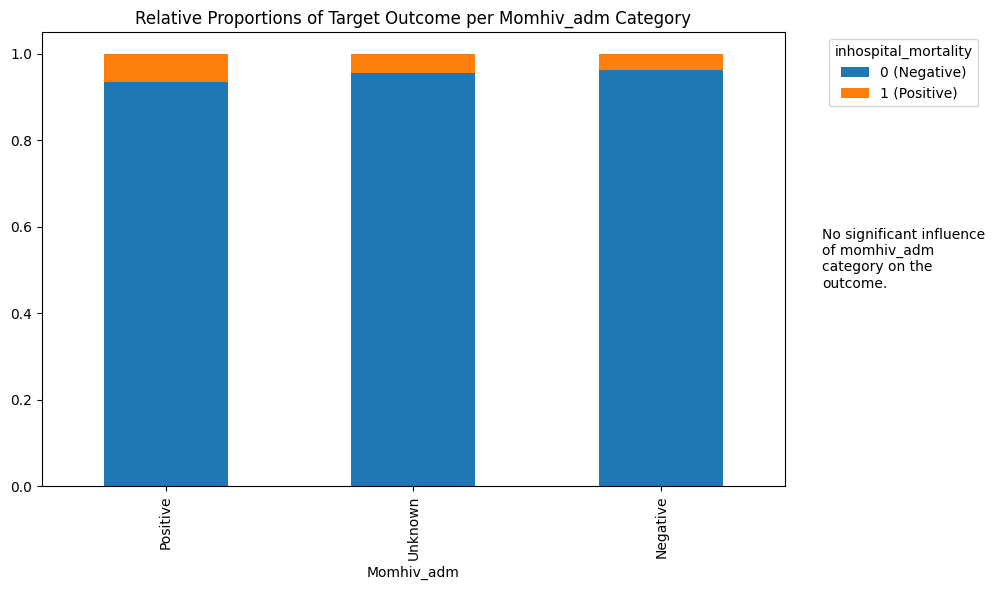

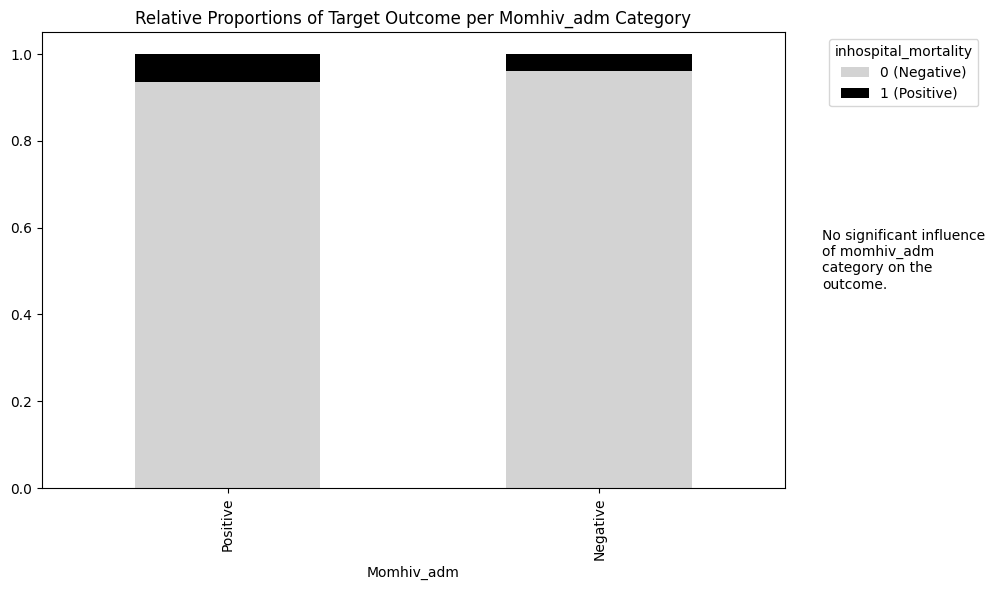

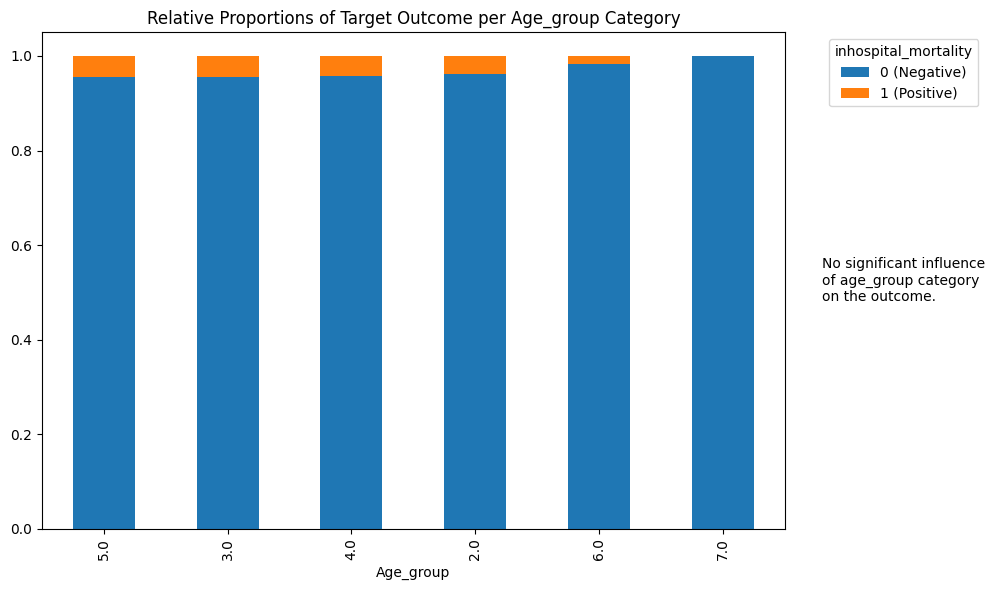

In [31]:
for col in non_binary_cats:
    categorical_analysis(col, df, target)
    if col in default_values.keys():
        tmp = df[df[col]!=default_values[col]]
        categorical_analysis(col, tmp, target, color=['#D3D3D3', '#000000'])


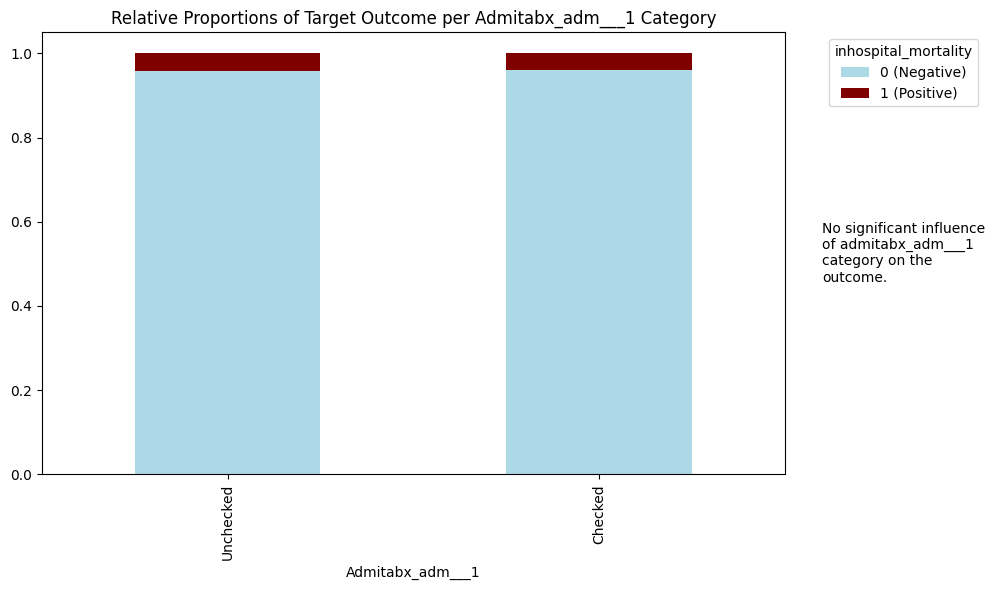

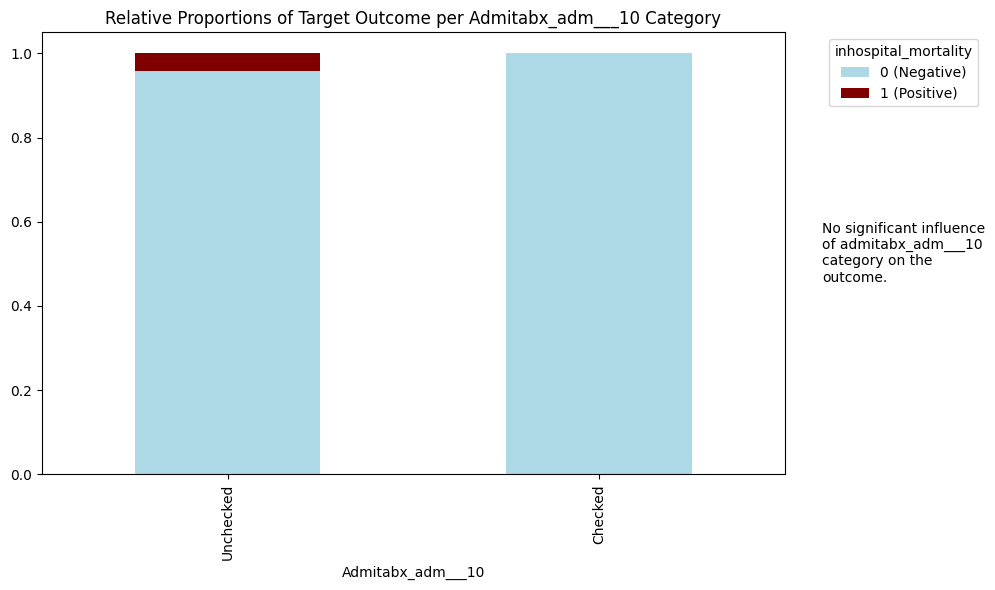

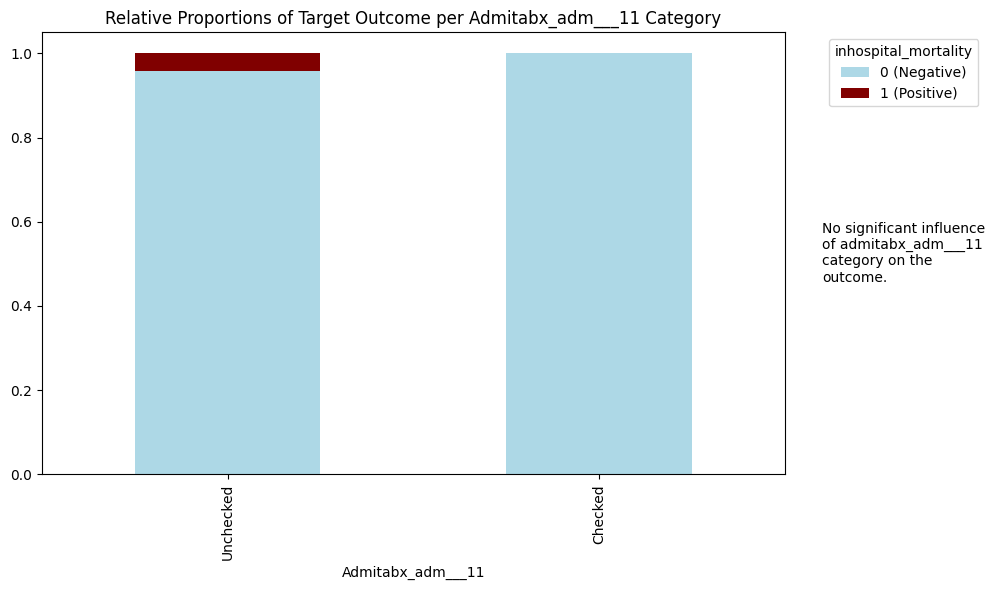

admitabx_adm___12 raised an error.
float division by zero


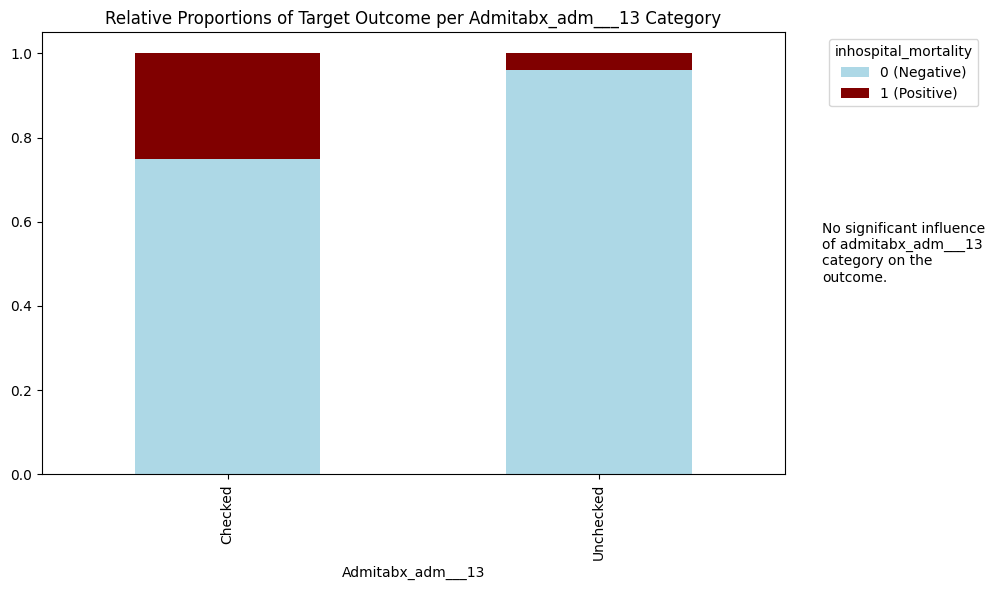

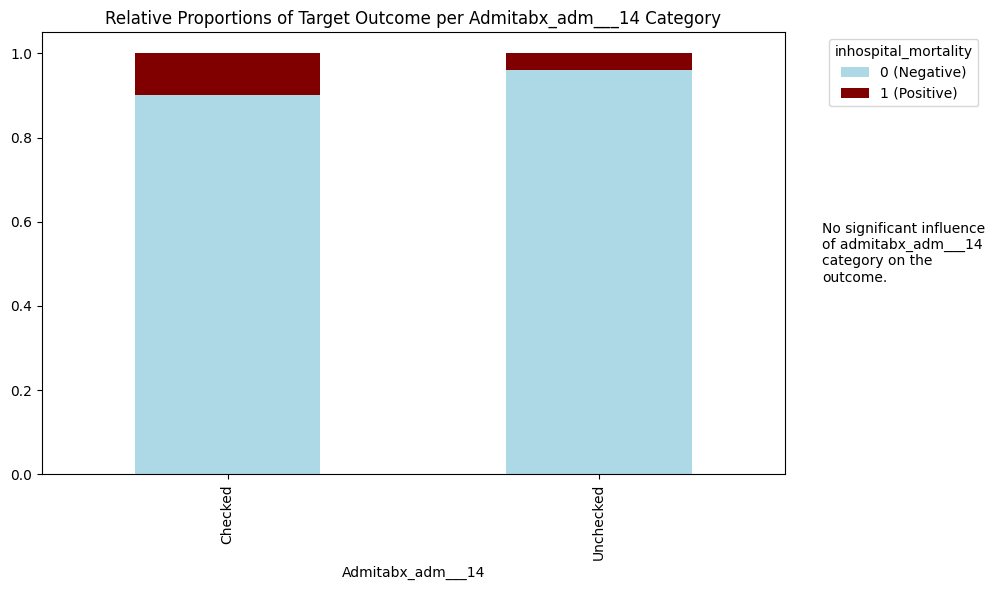

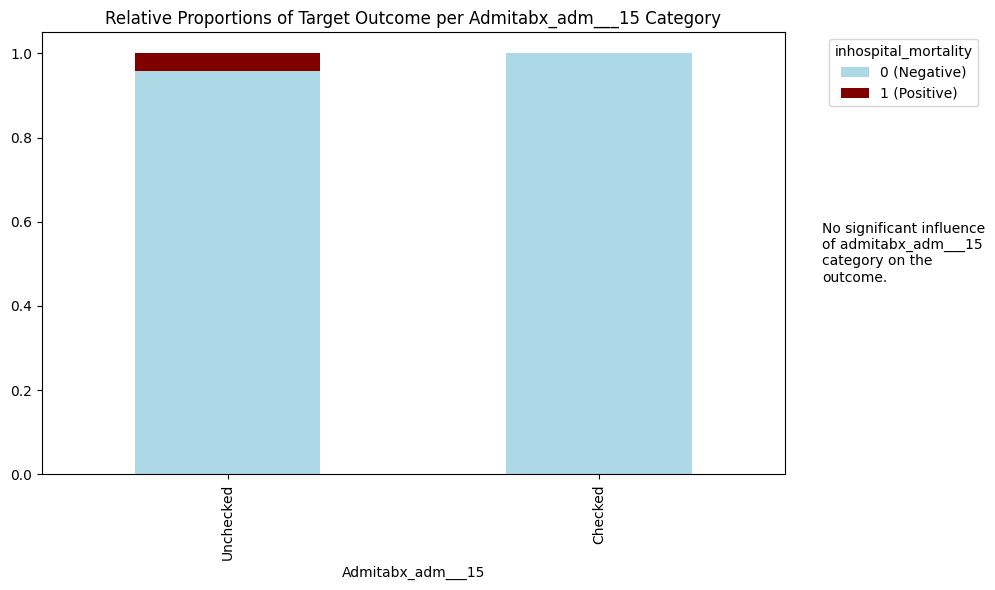

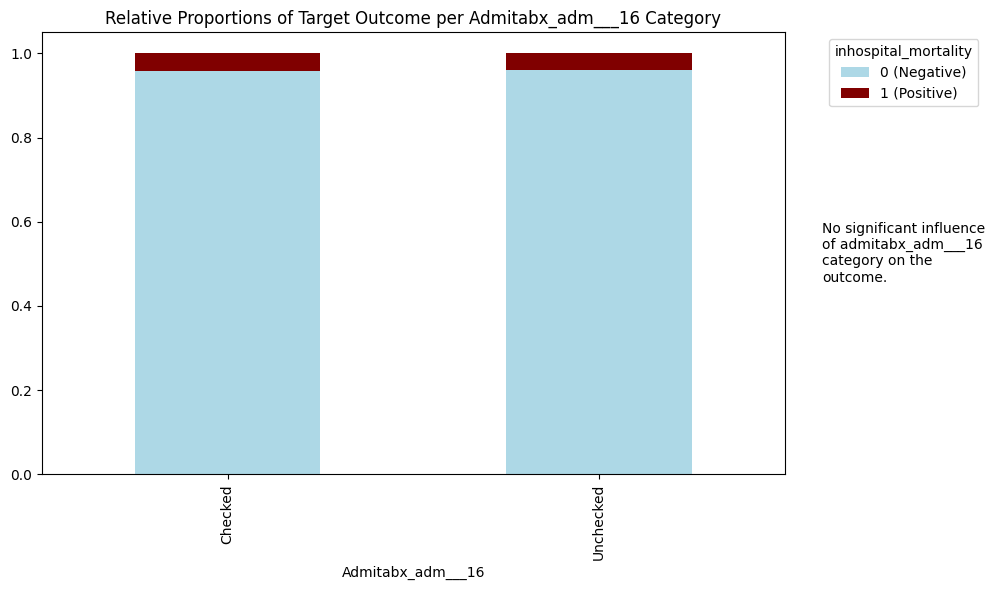

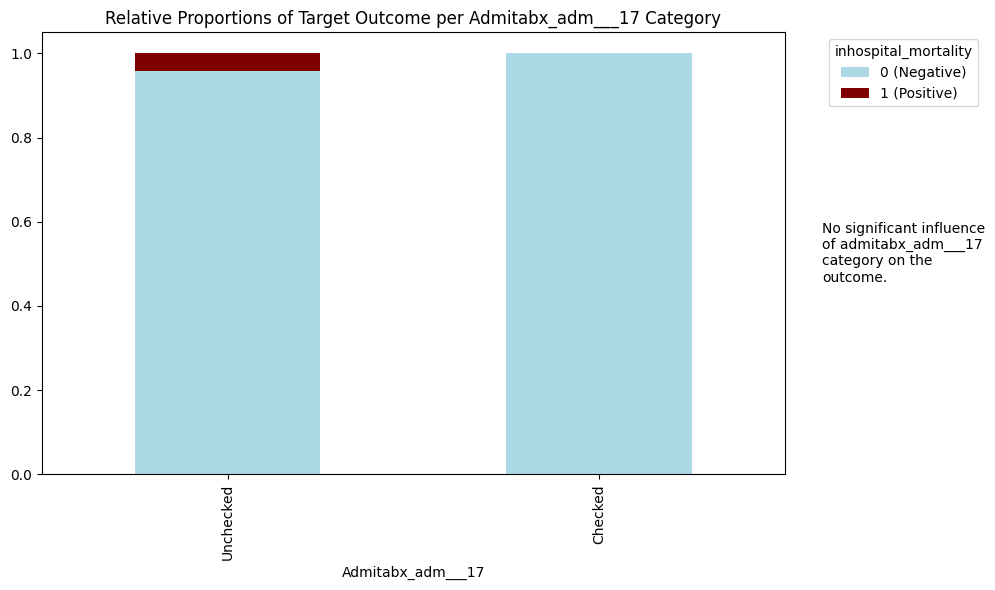

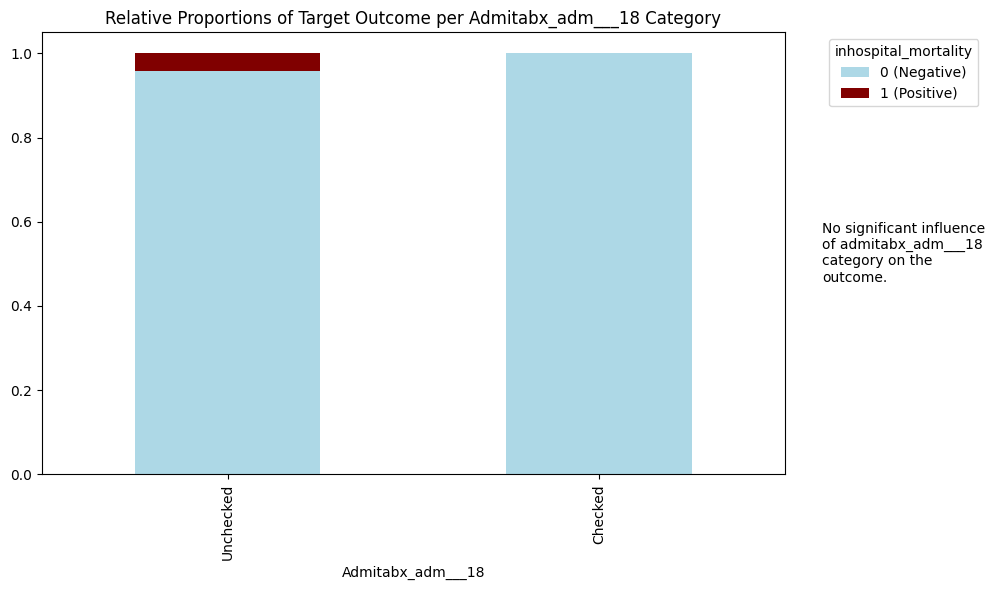

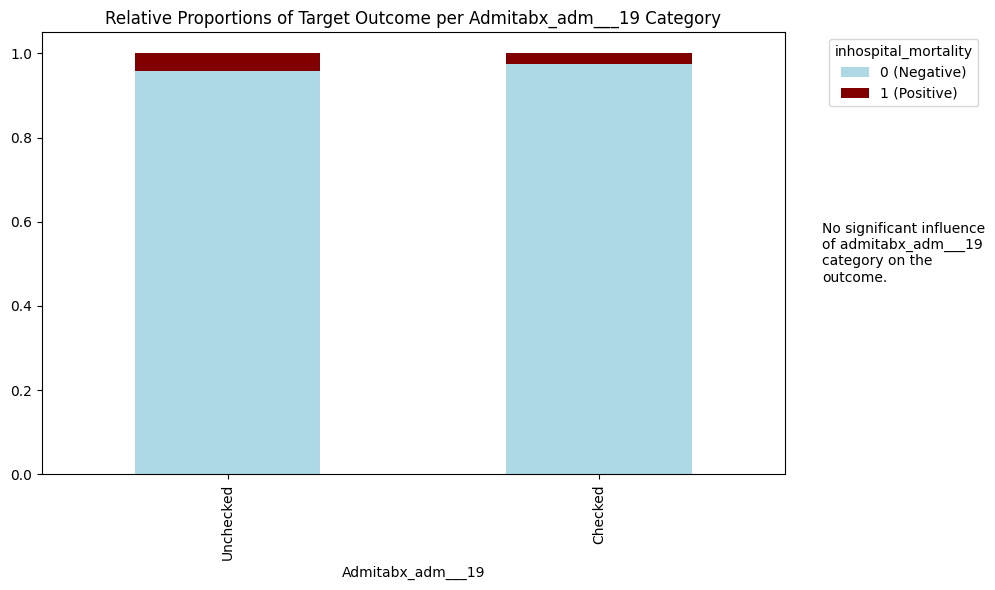

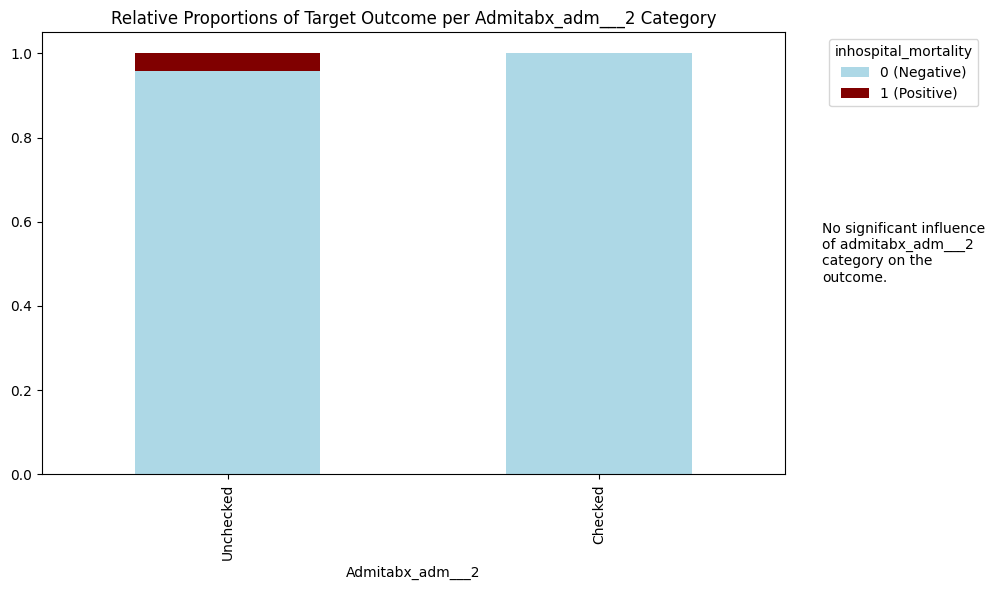

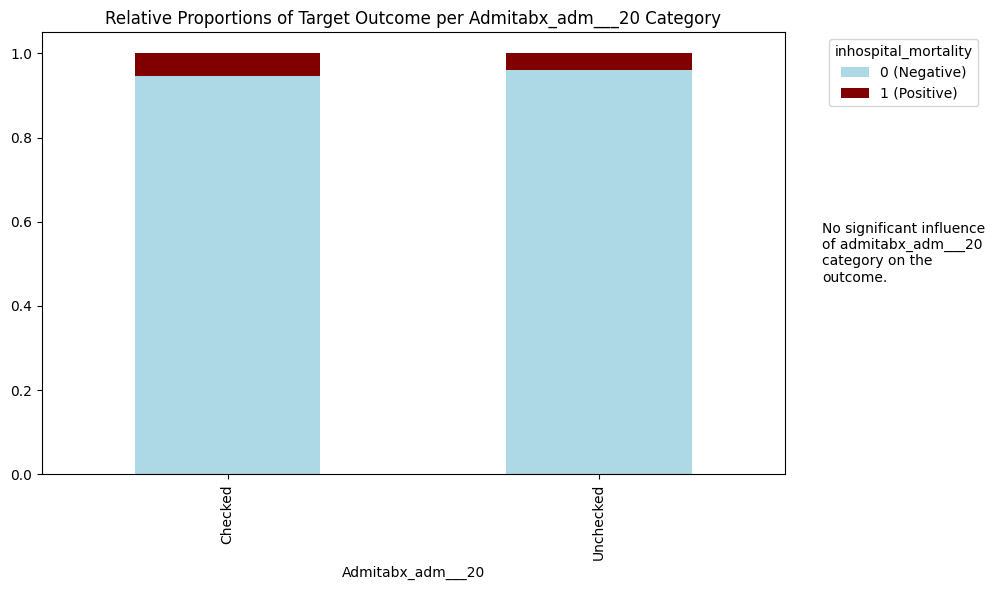

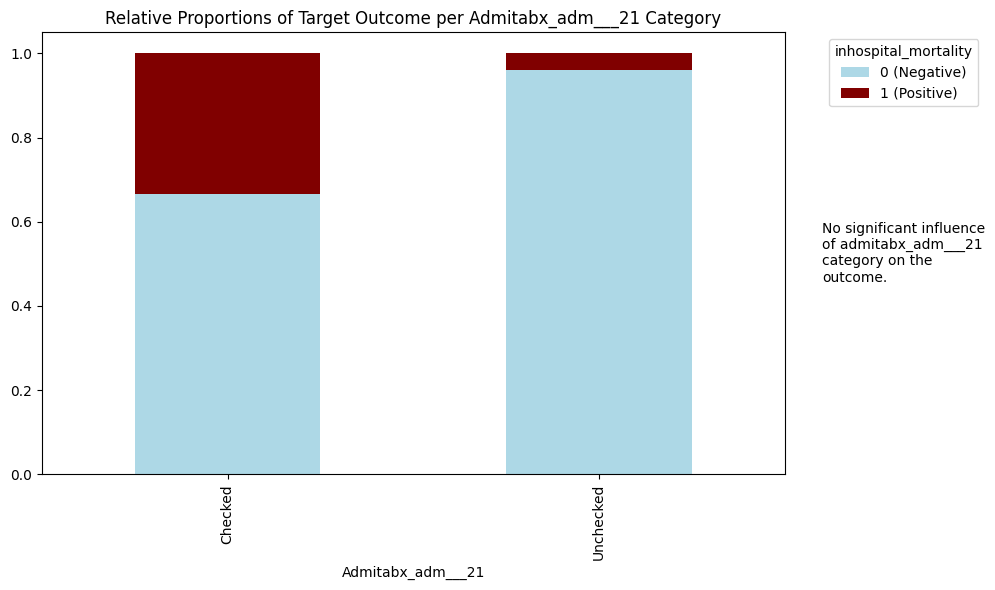

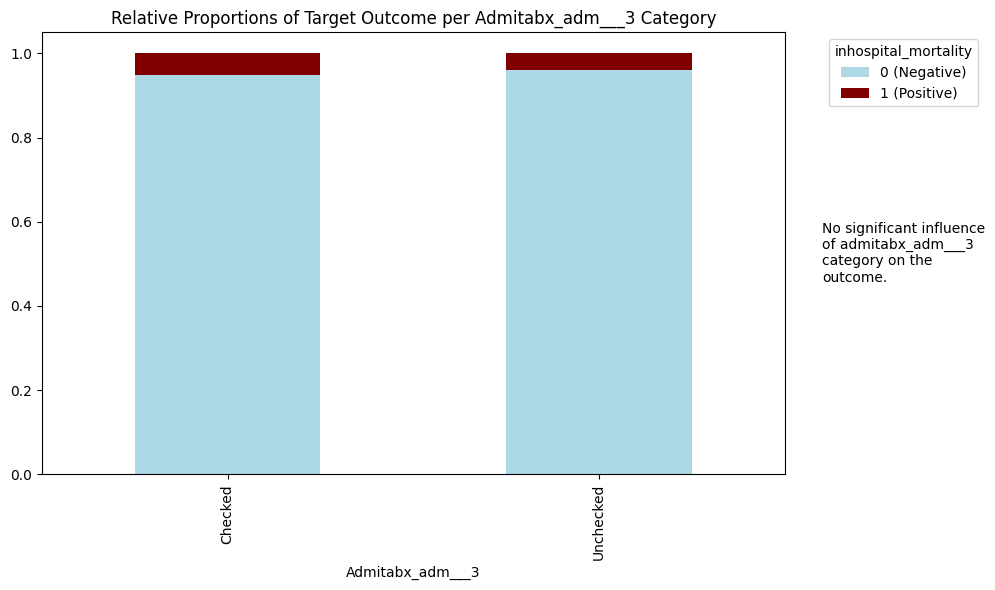

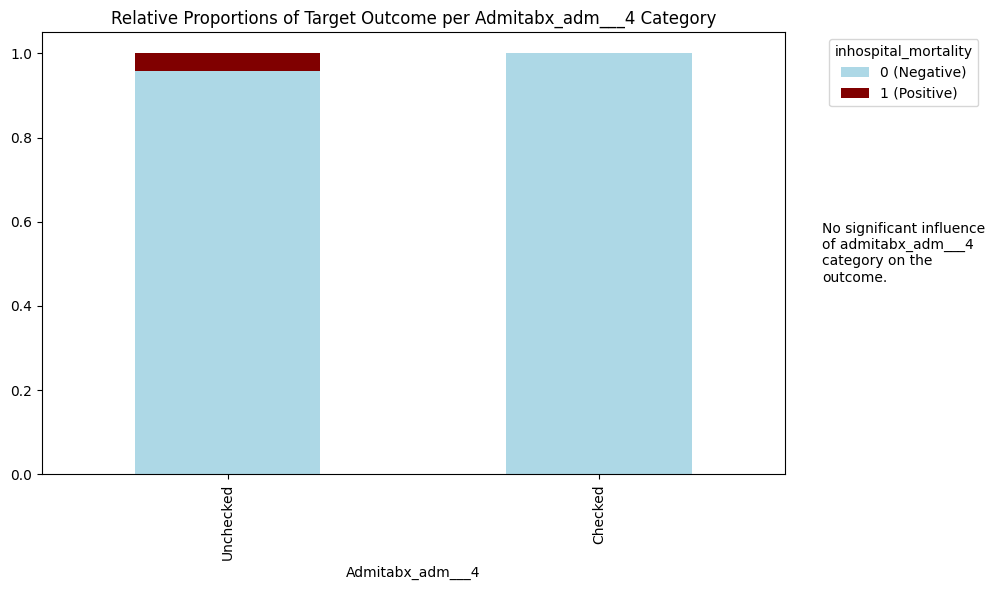

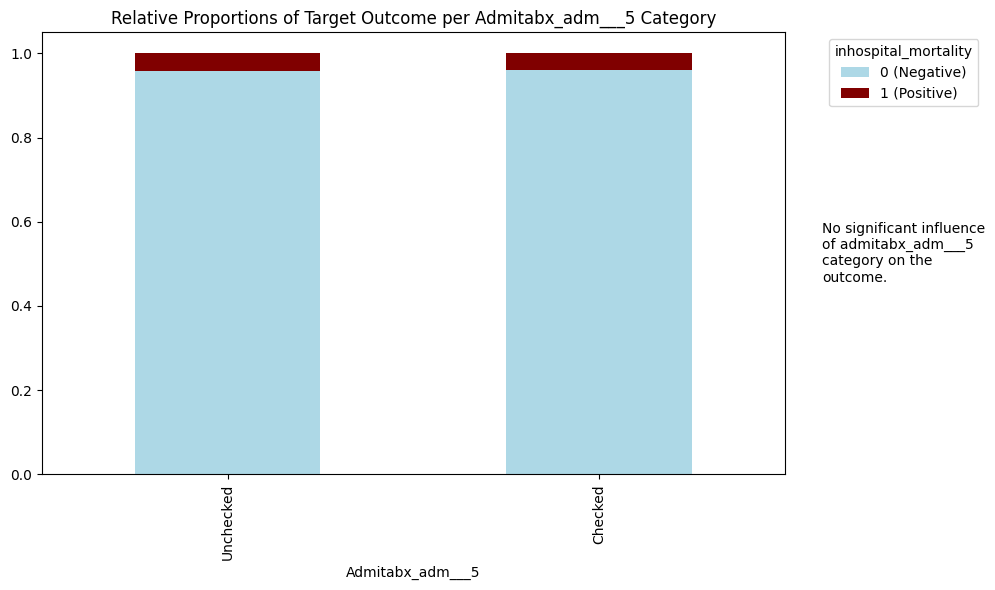

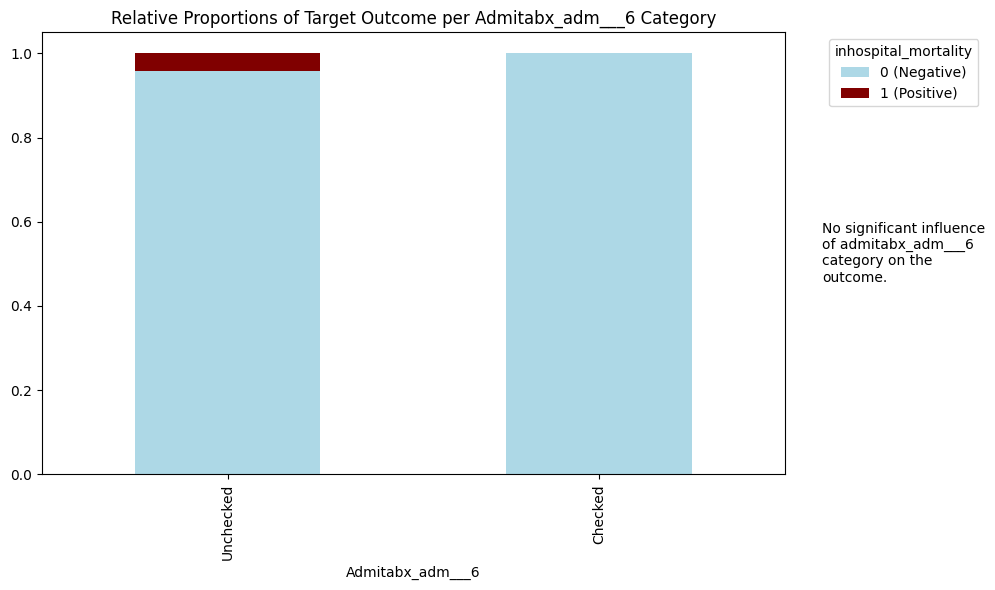

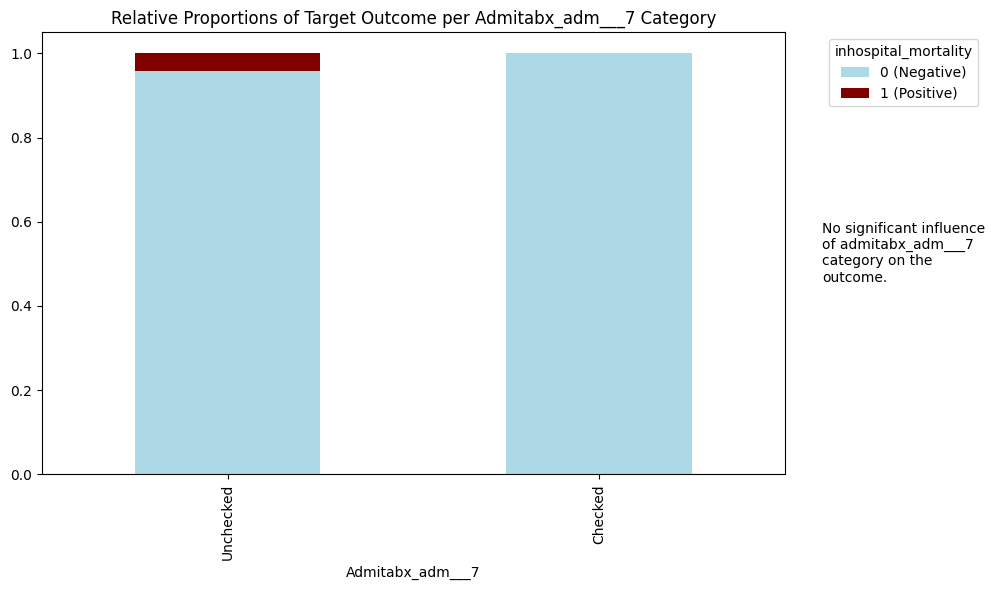

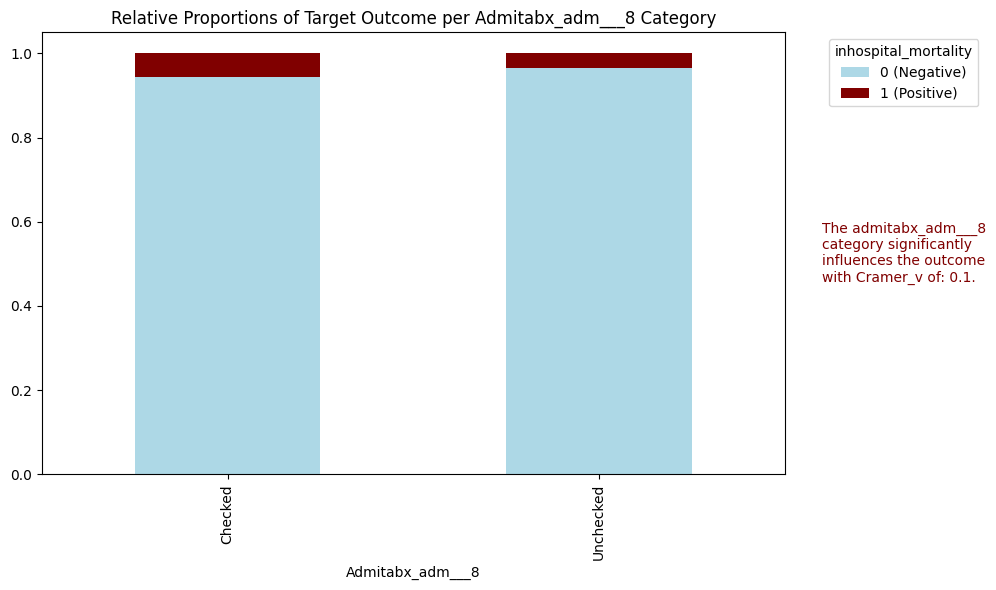

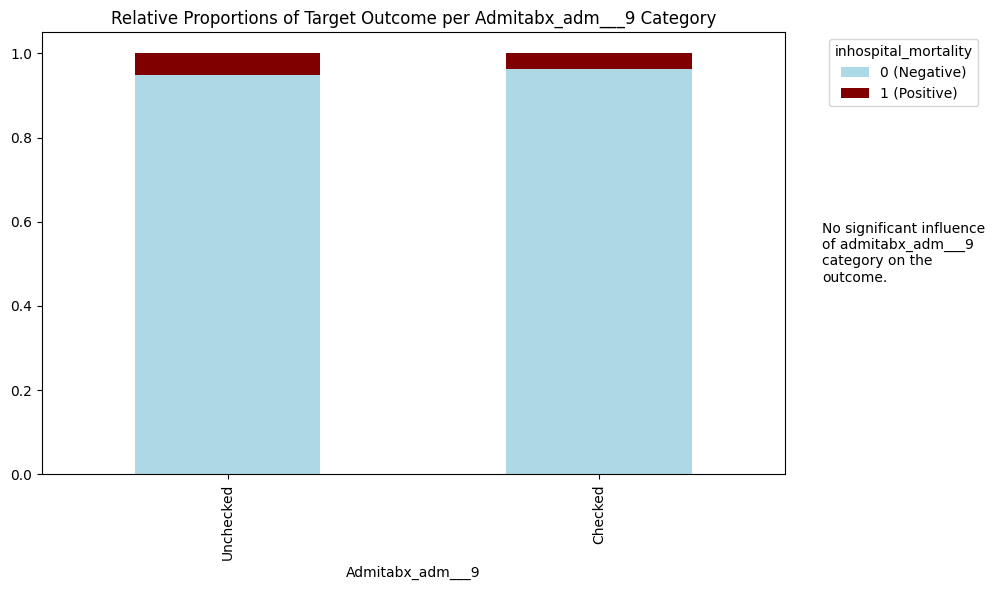

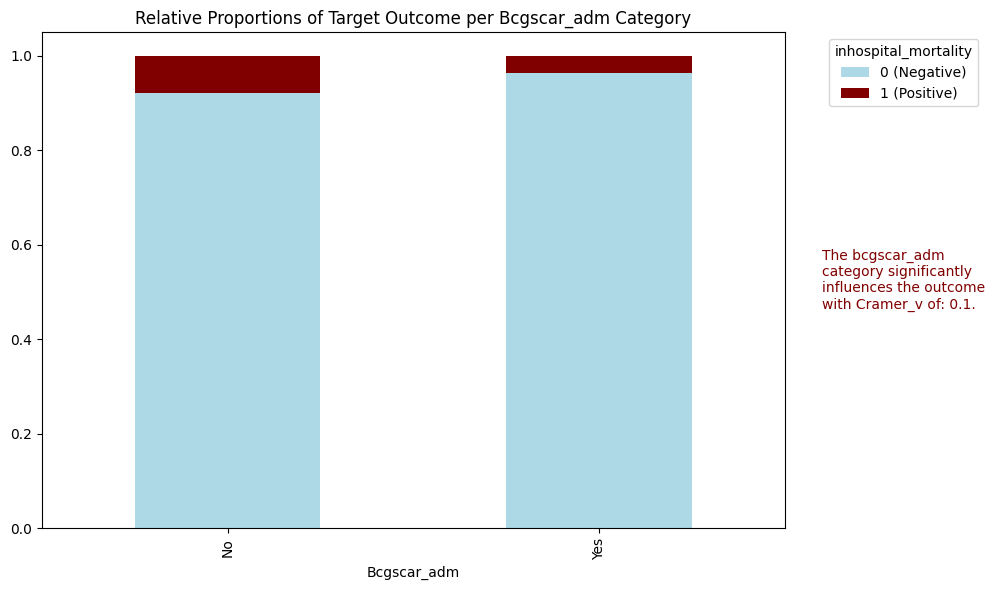

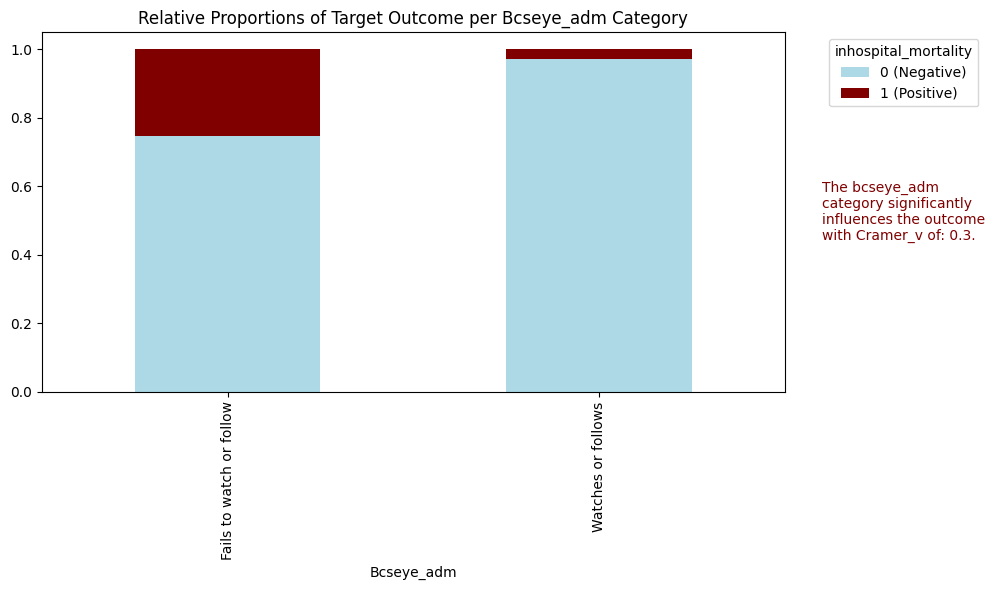

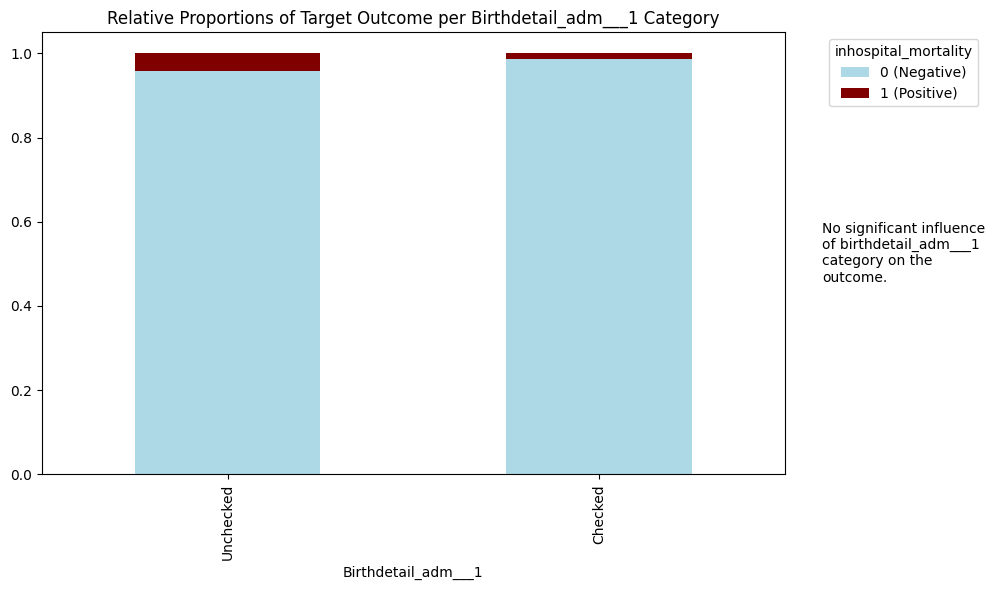

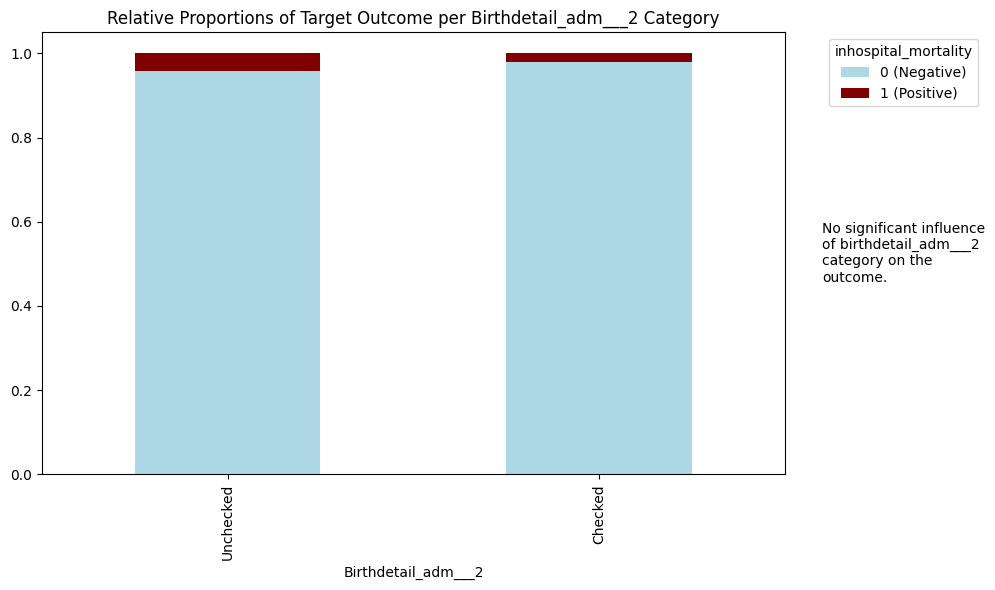

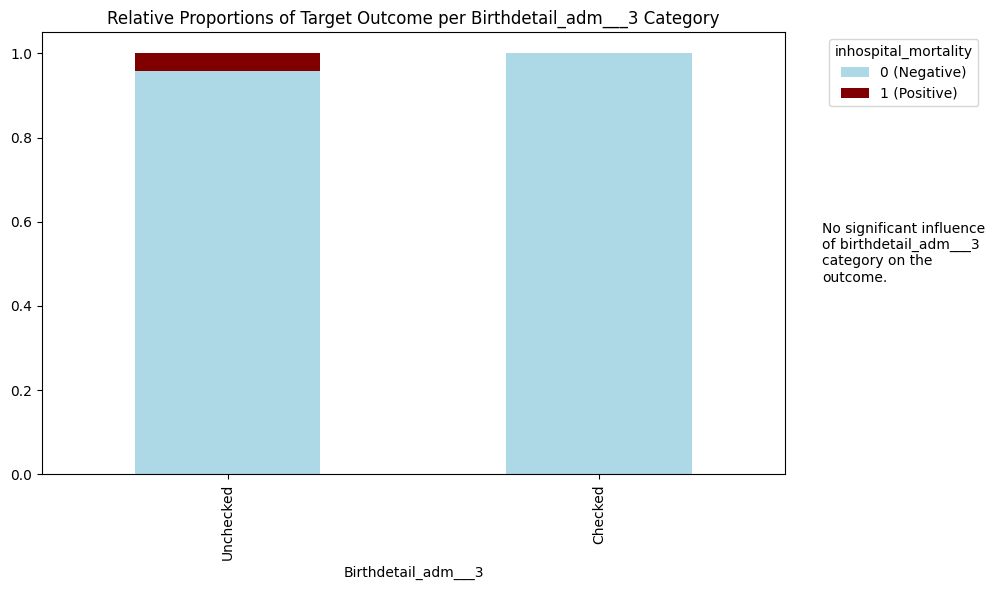

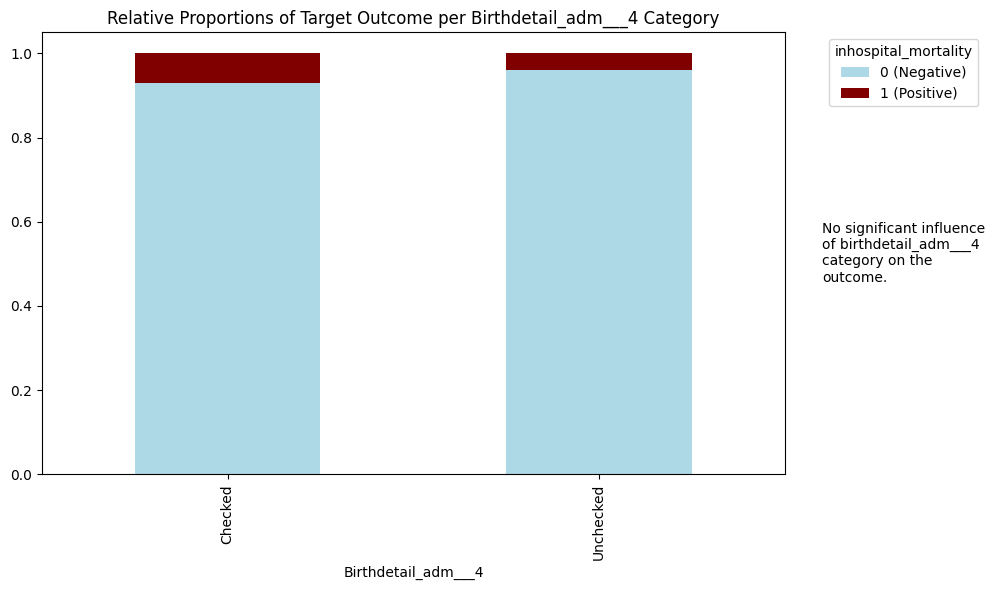

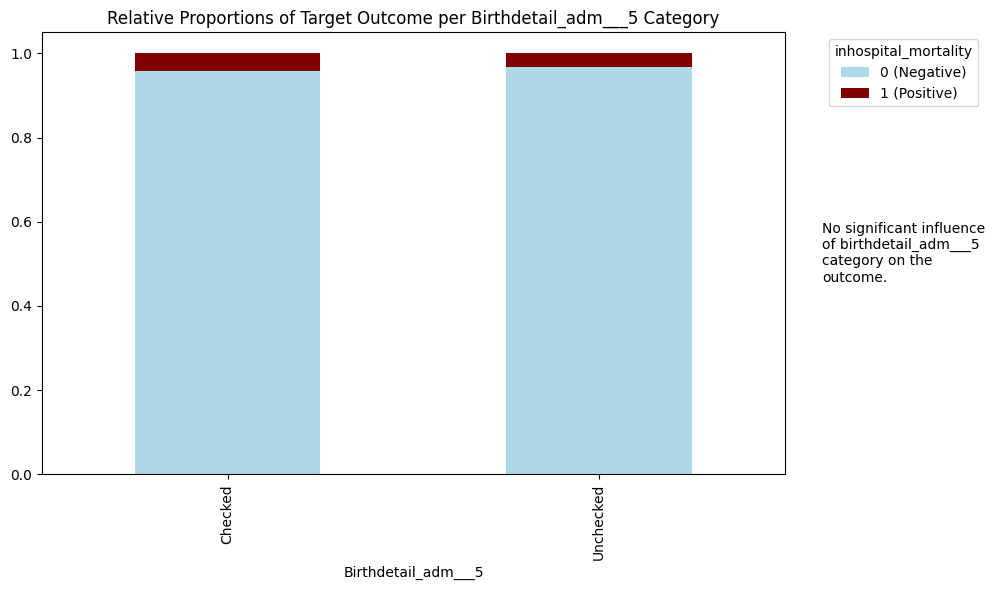

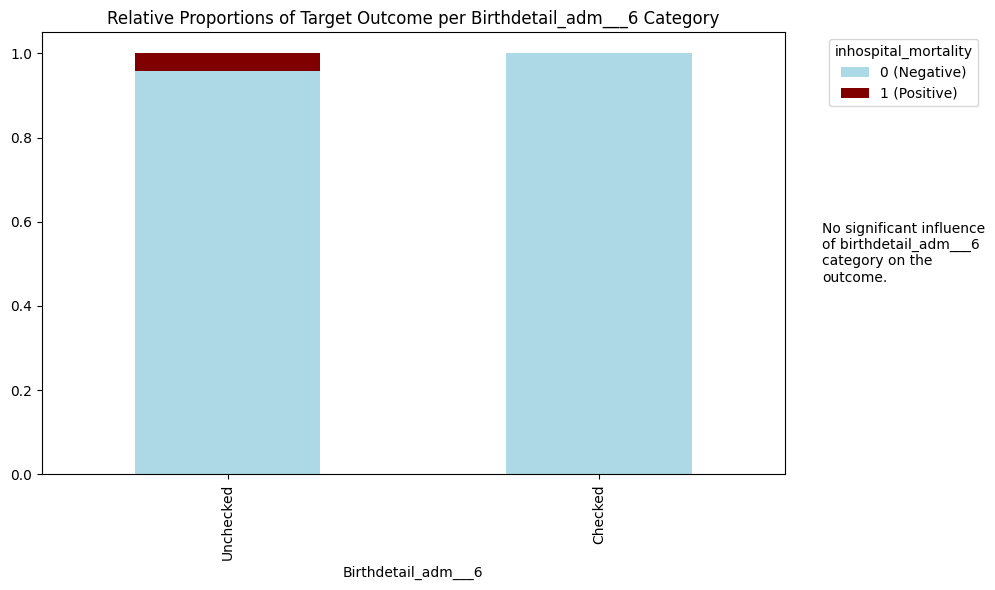

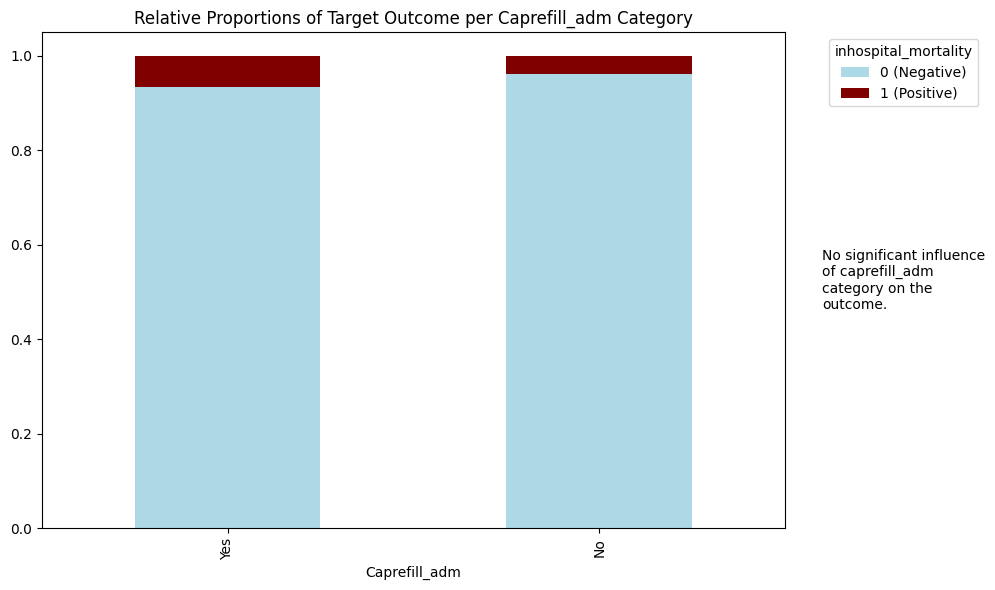

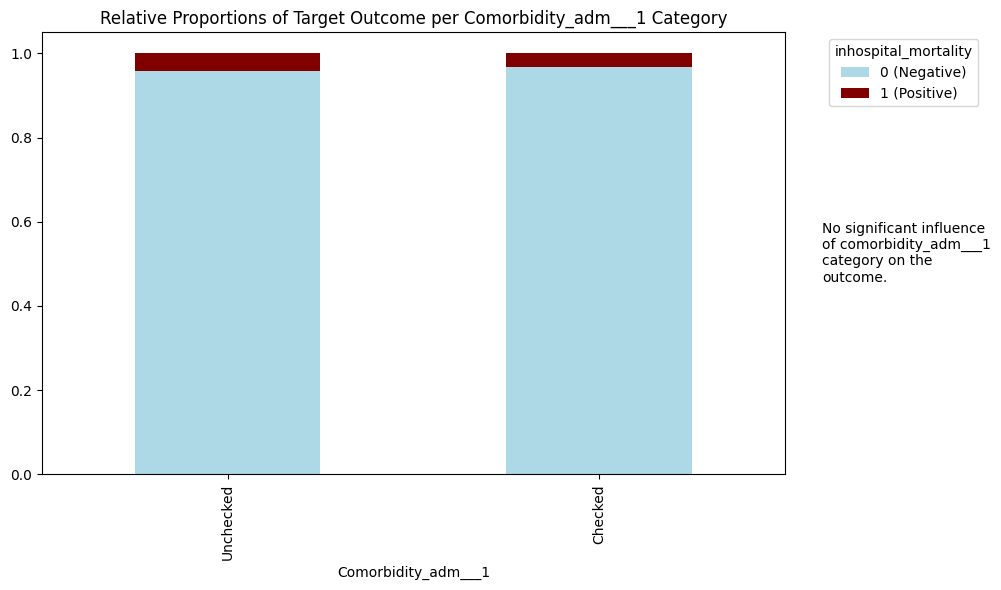

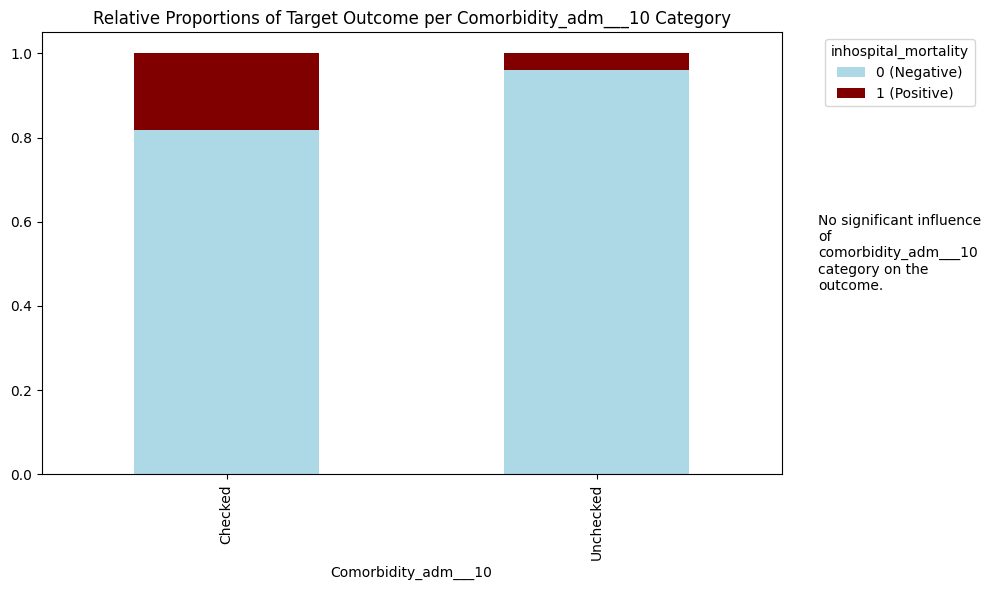

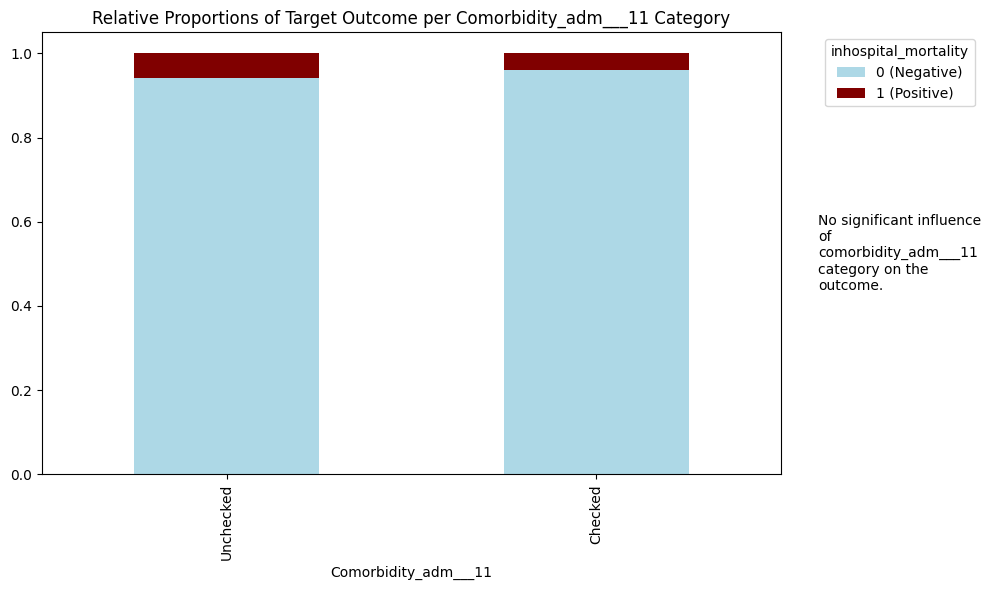

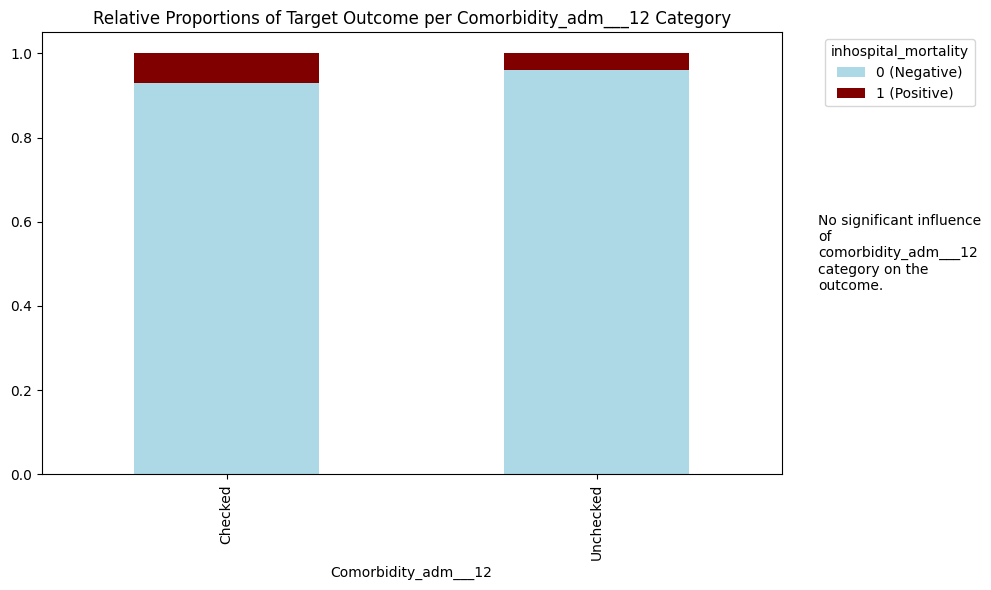

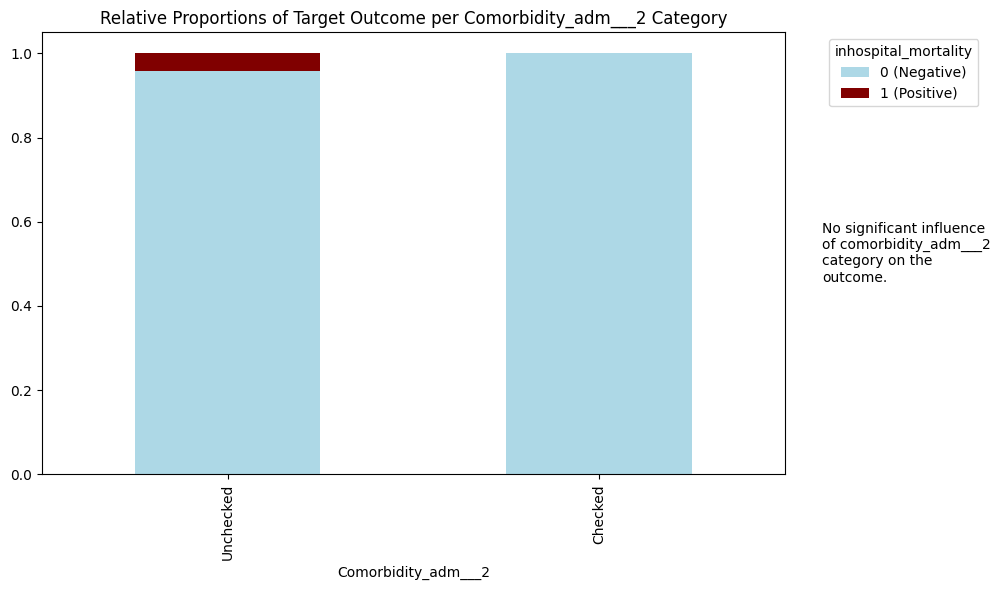

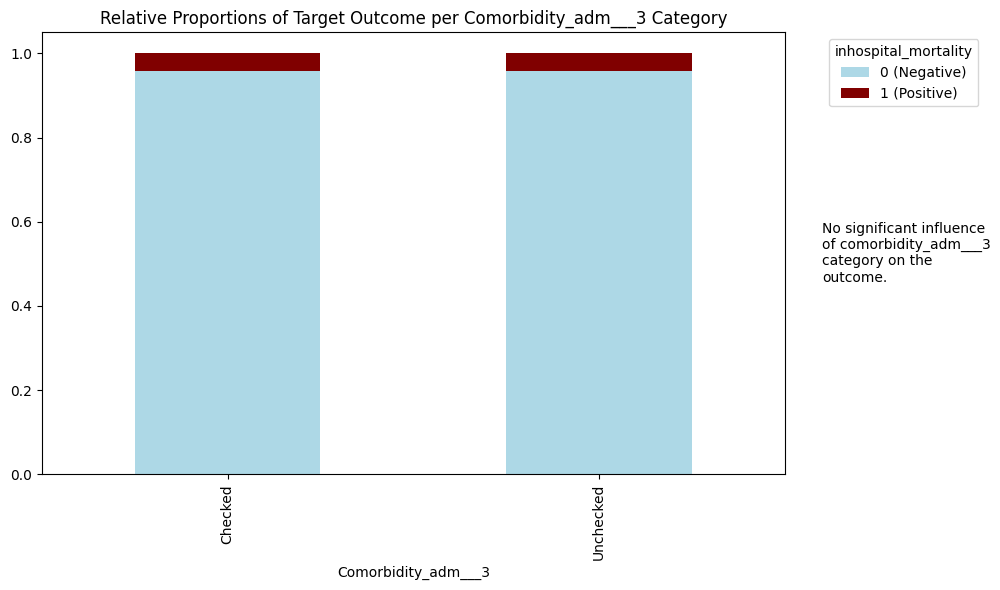

comorbidity_adm___4 raised an error.
float division by zero


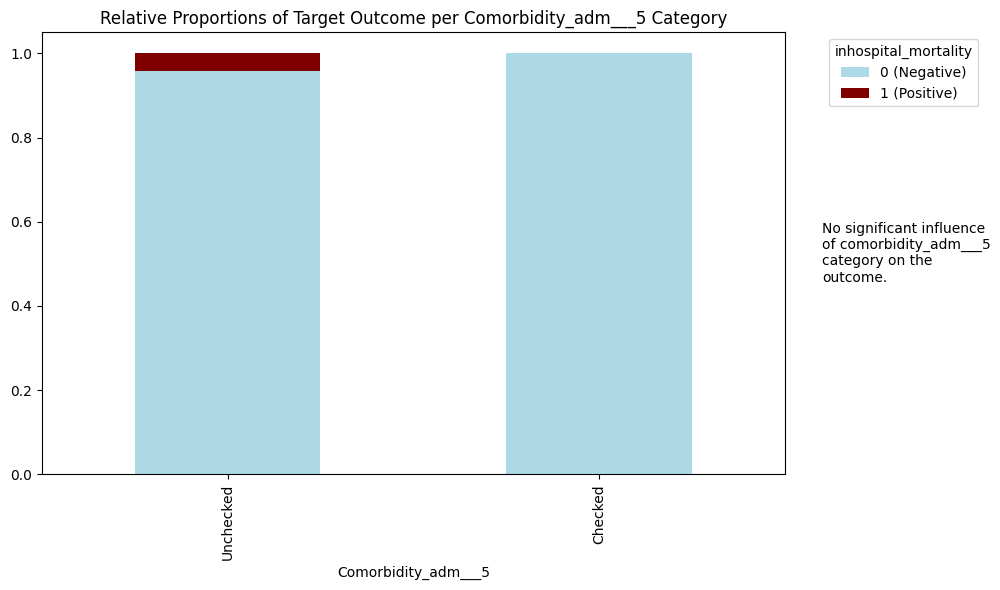

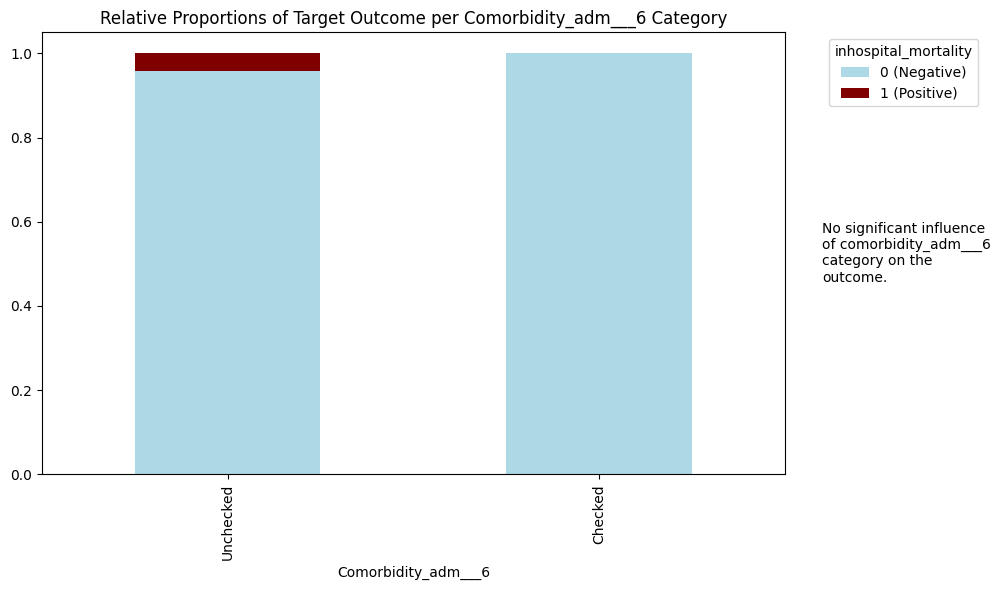

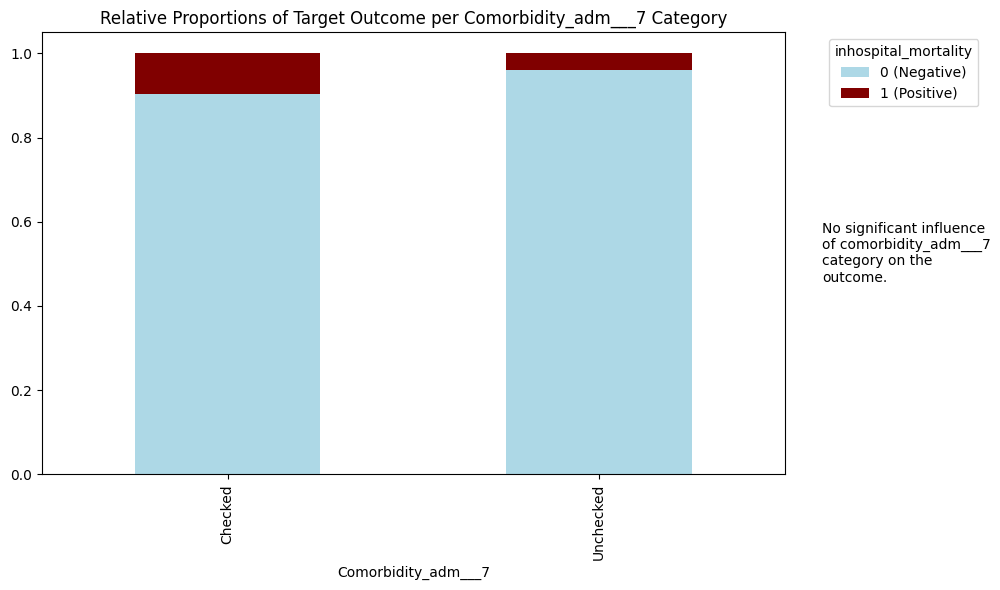

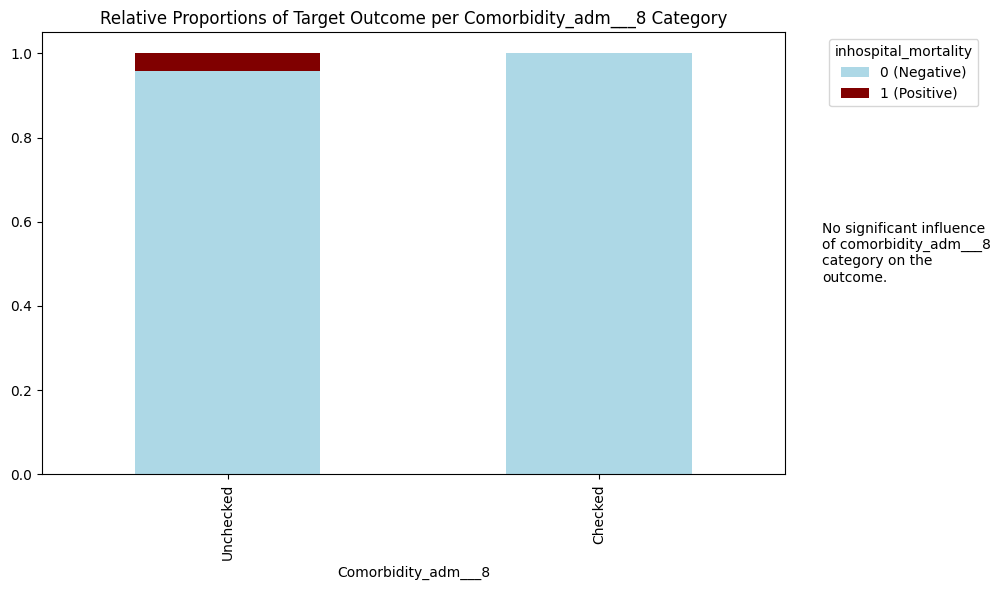

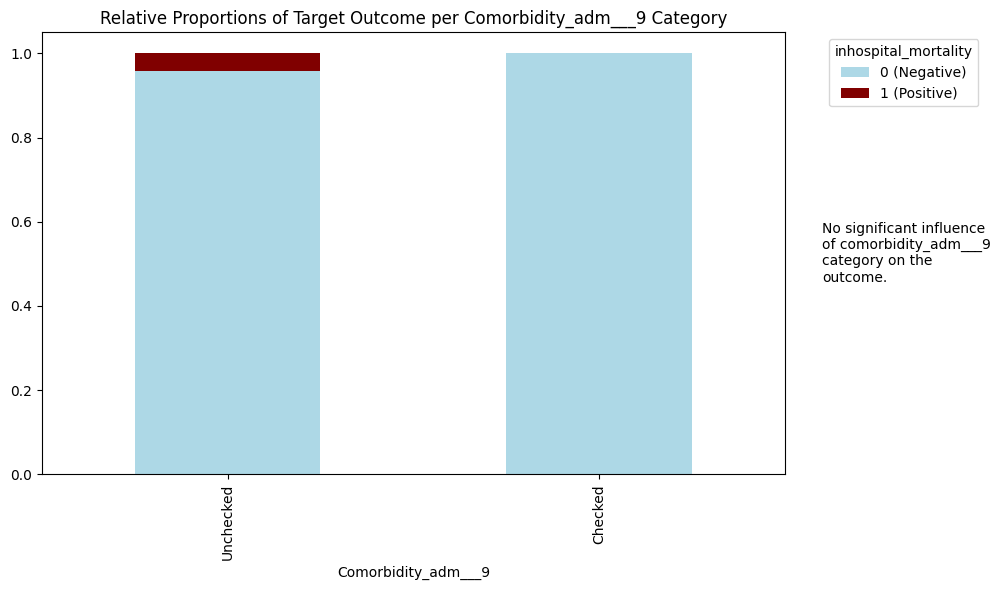

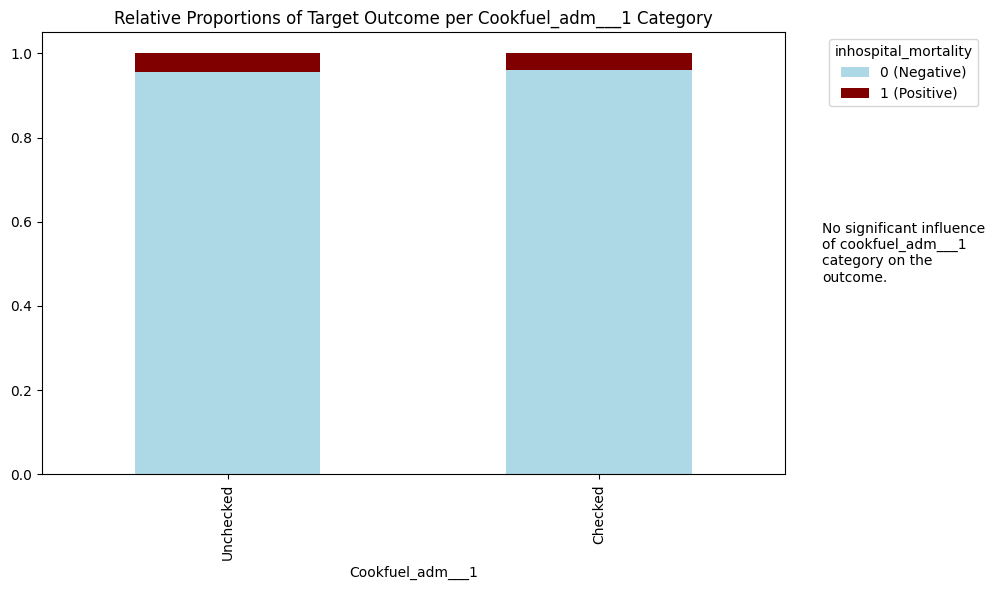

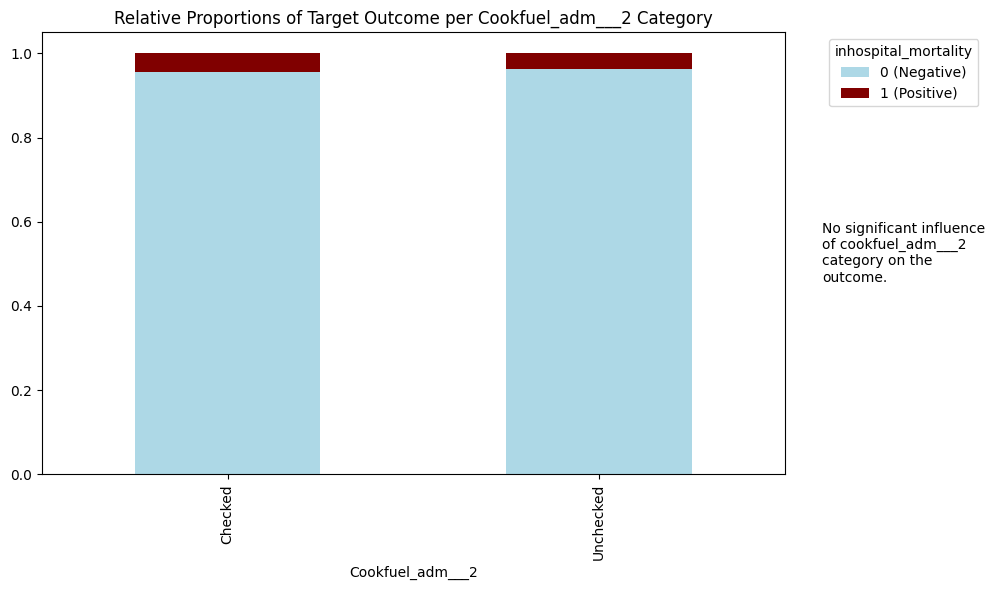

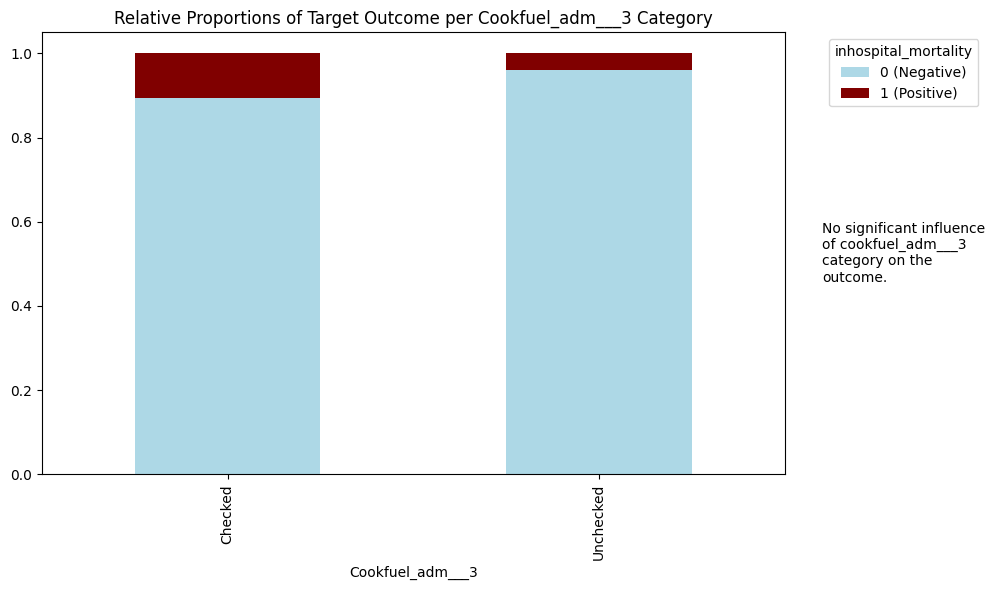

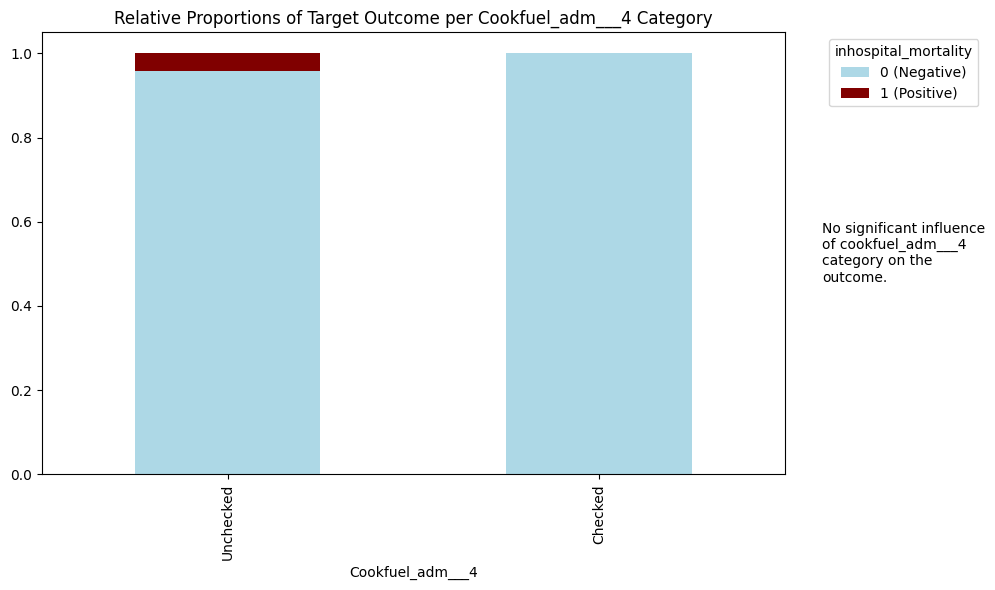

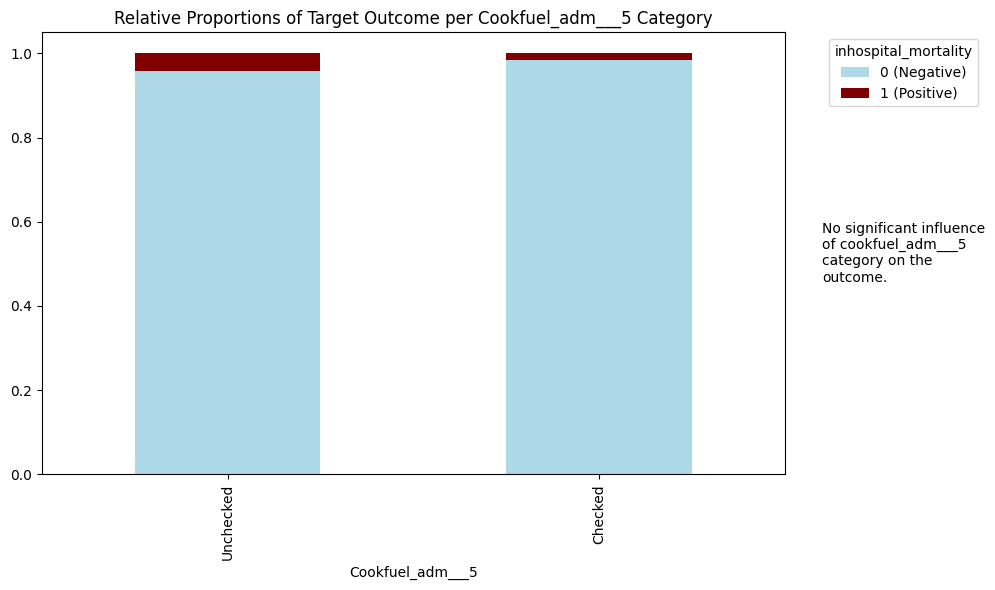

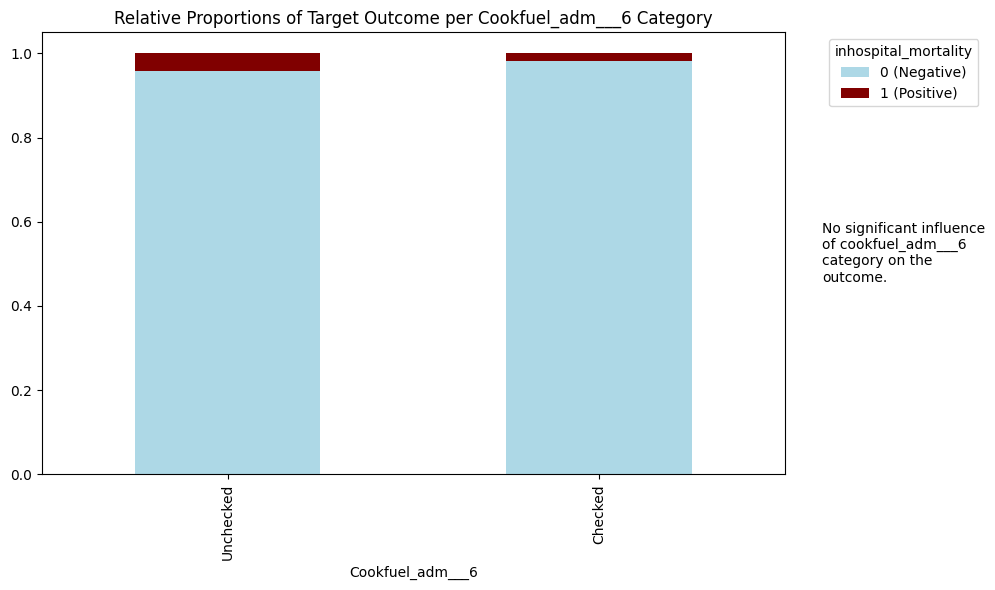

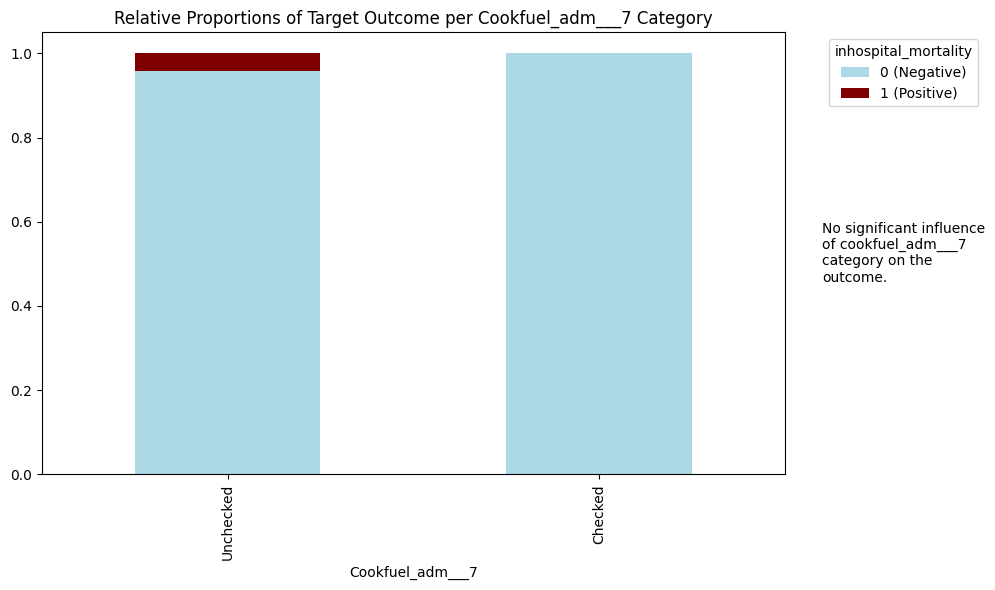

cookfuel_adm___8 raised an error.
float division by zero


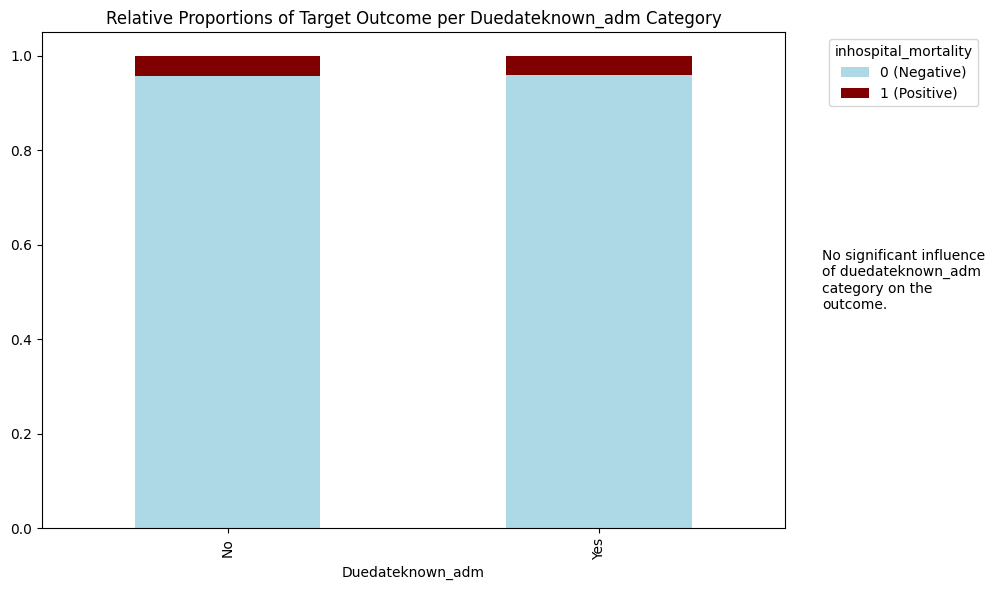

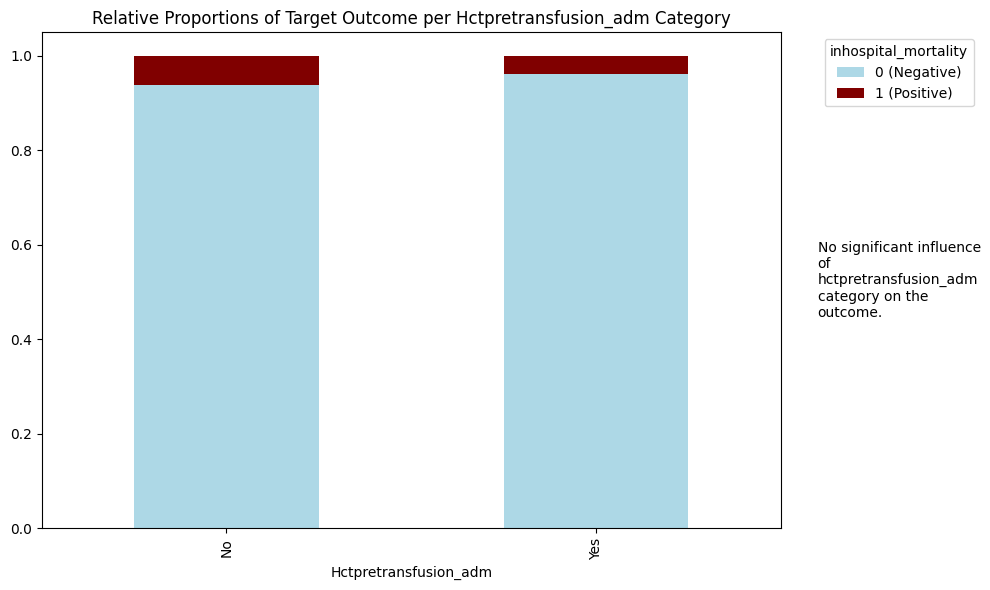

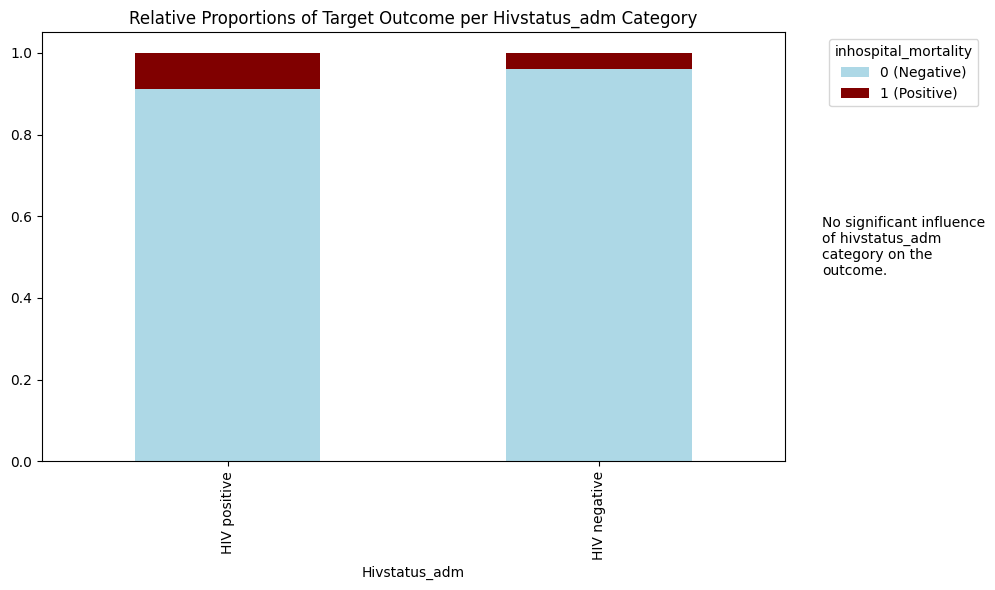

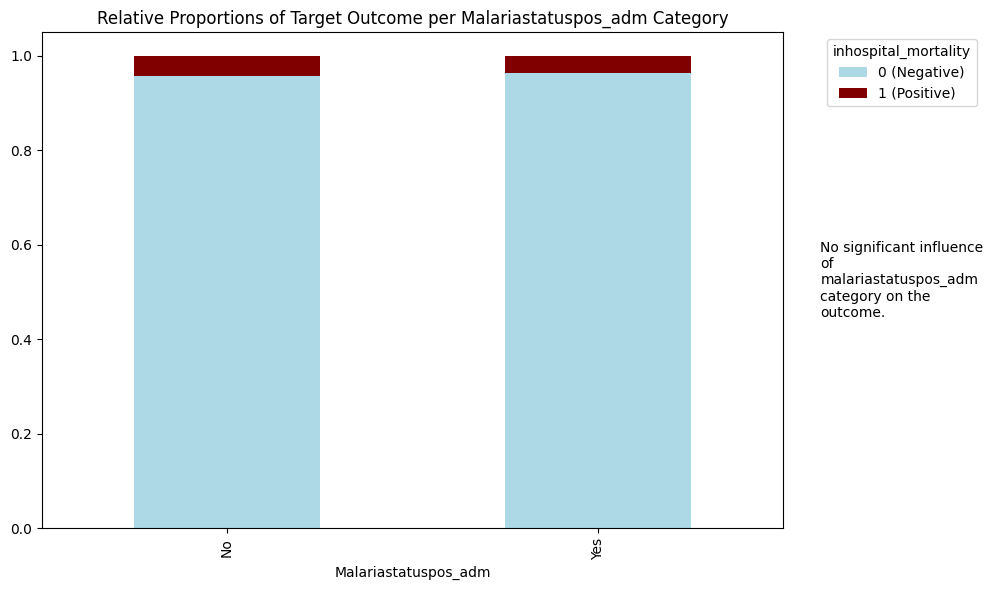

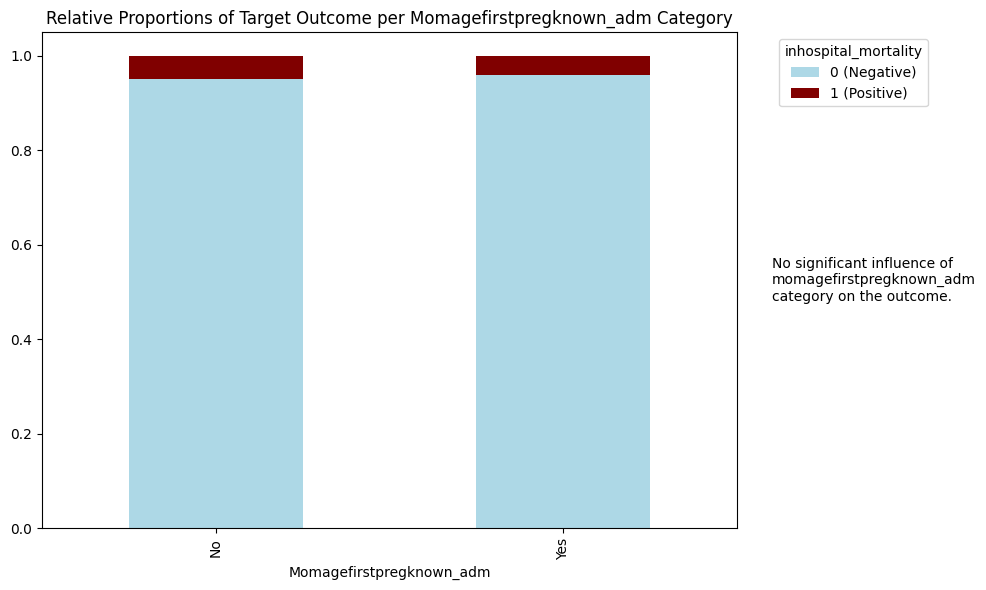

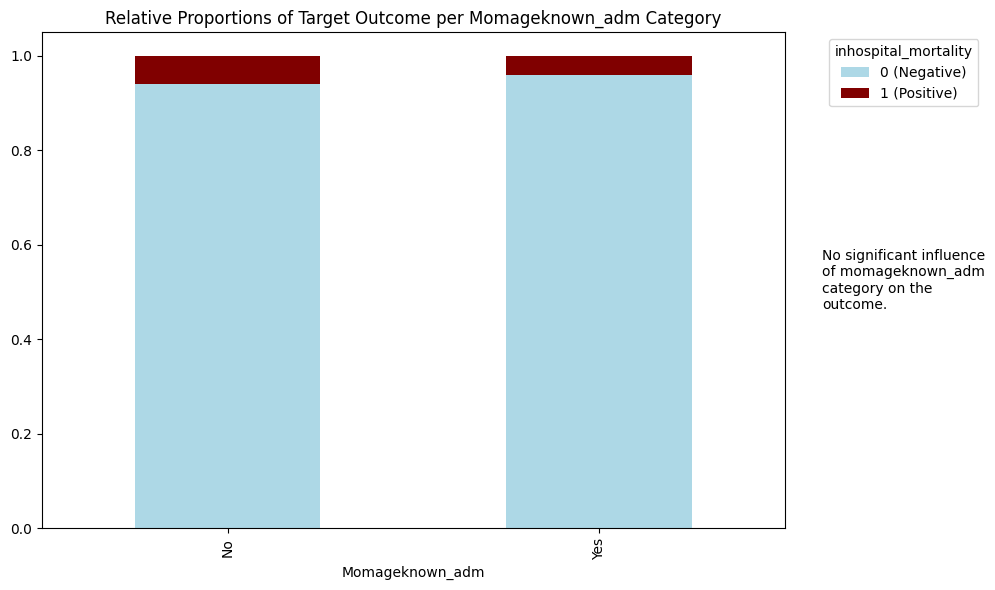

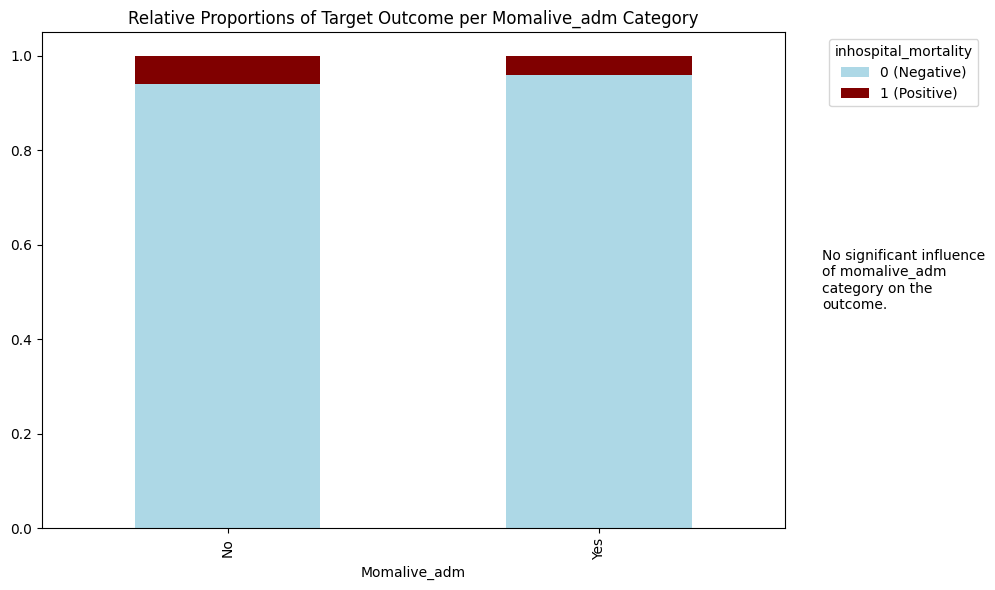

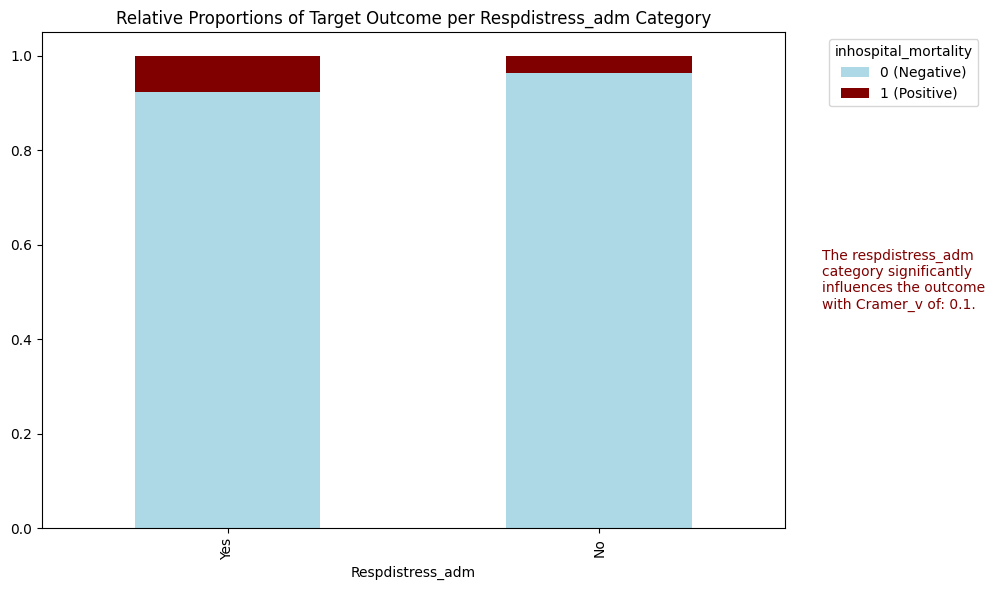

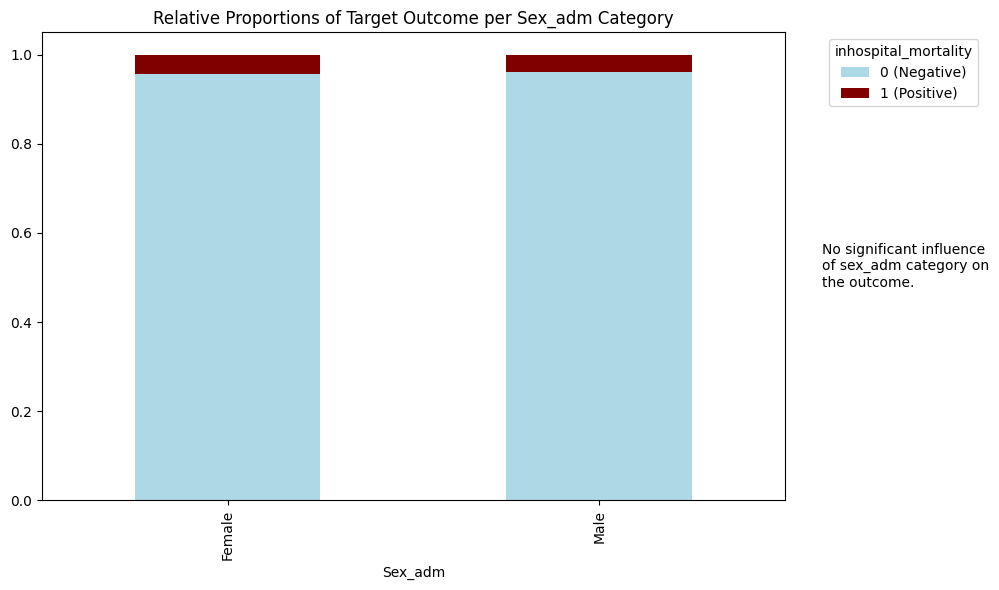

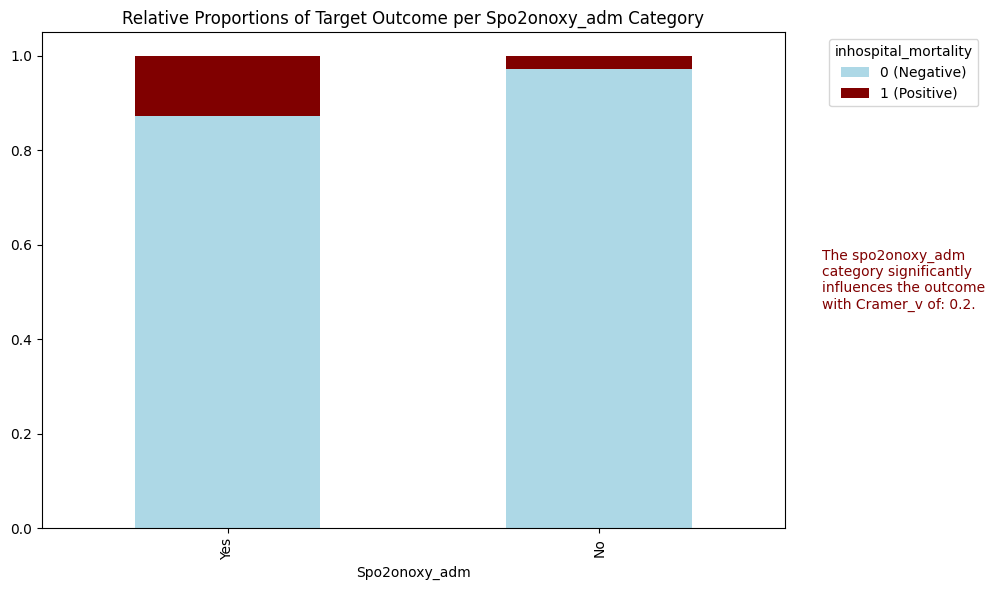

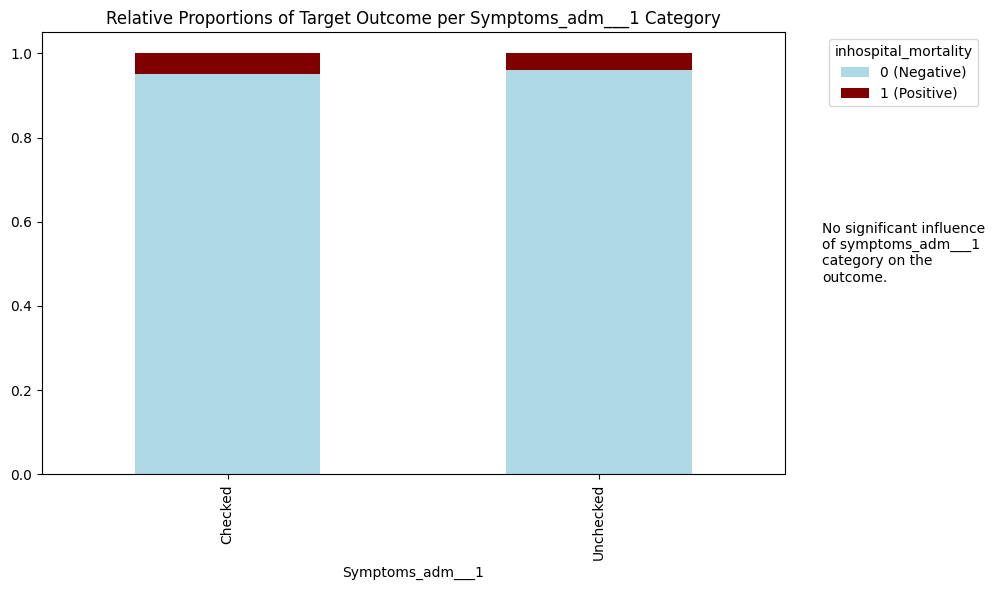

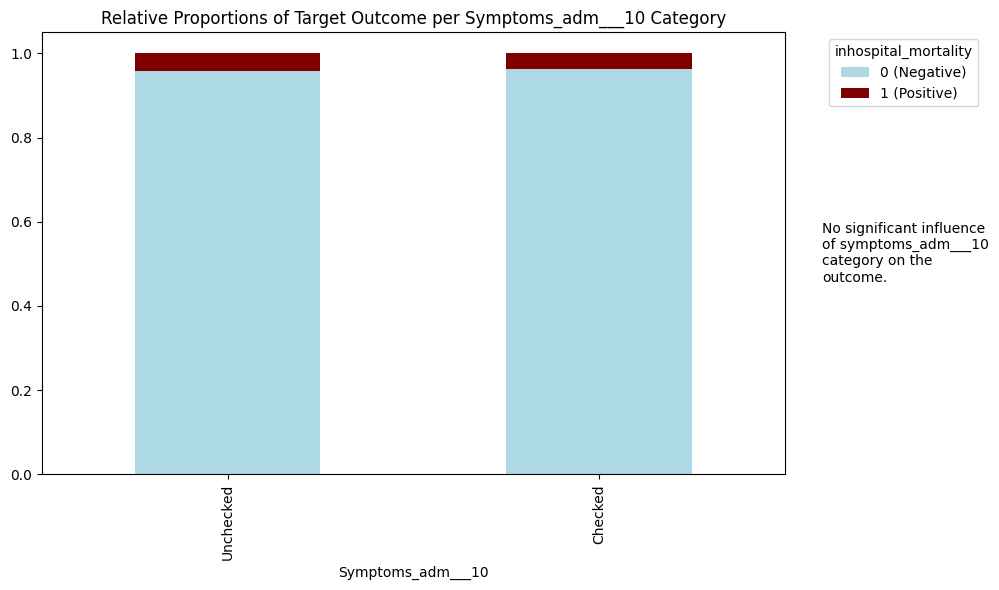

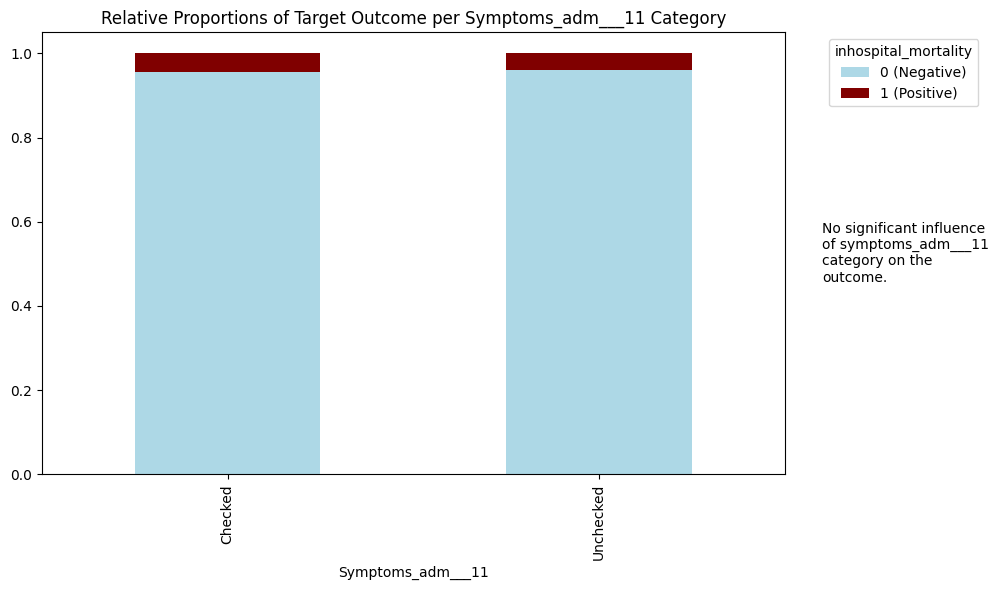

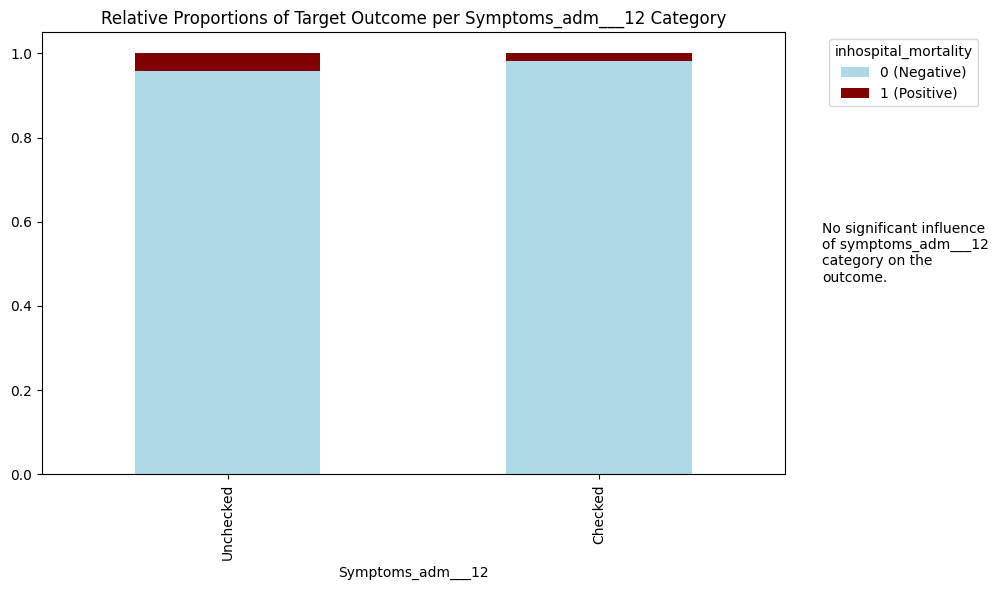

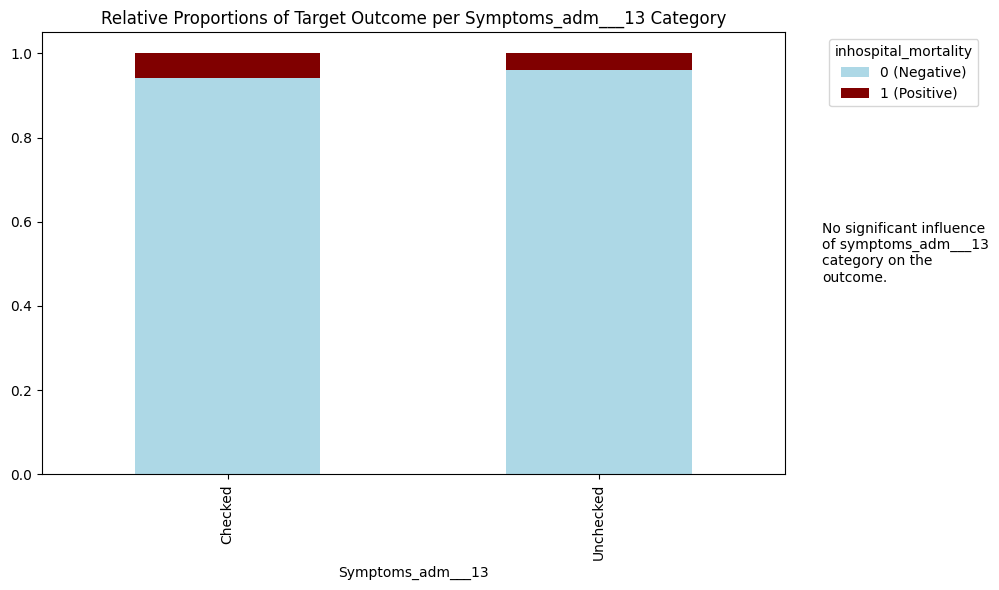

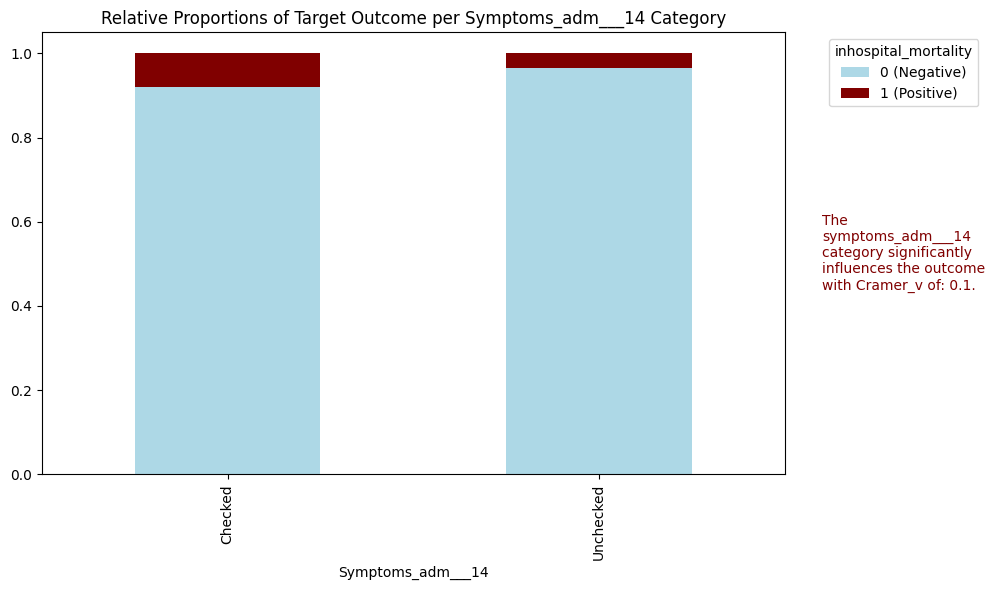

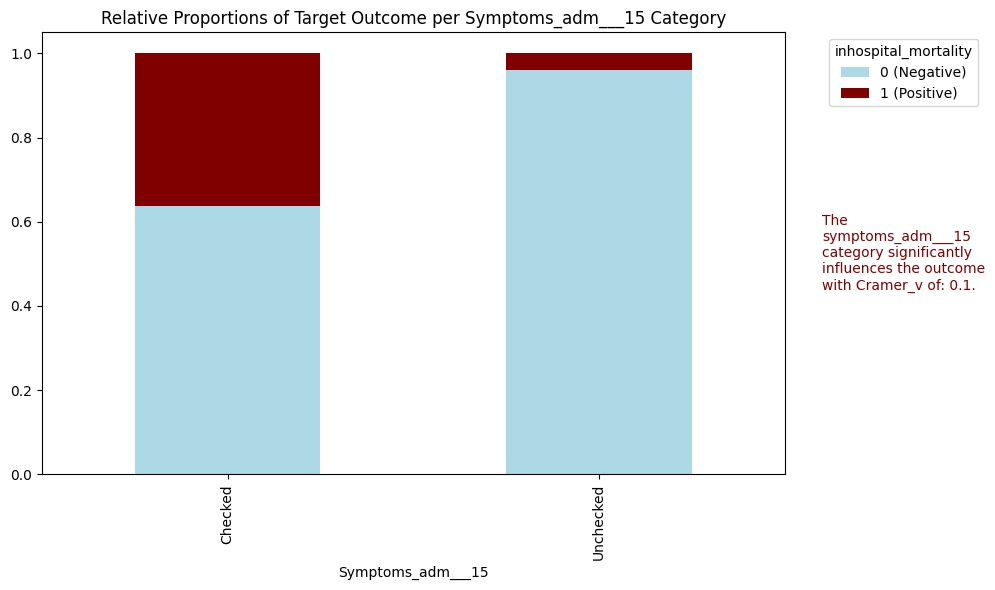

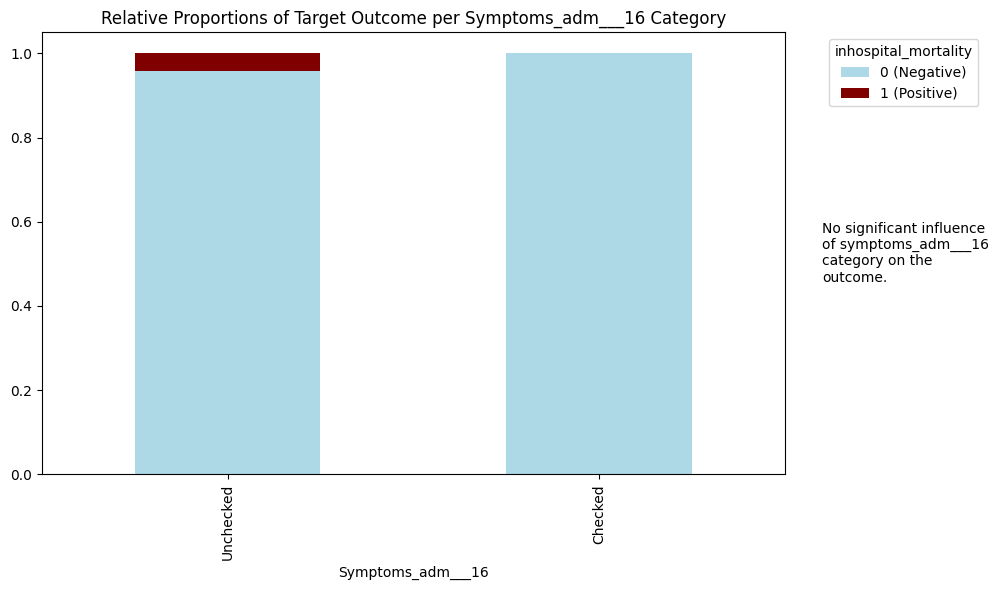

symptoms_adm___17 raised an error.
float division by zero
symptoms_adm___18 raised an error.
float division by zero


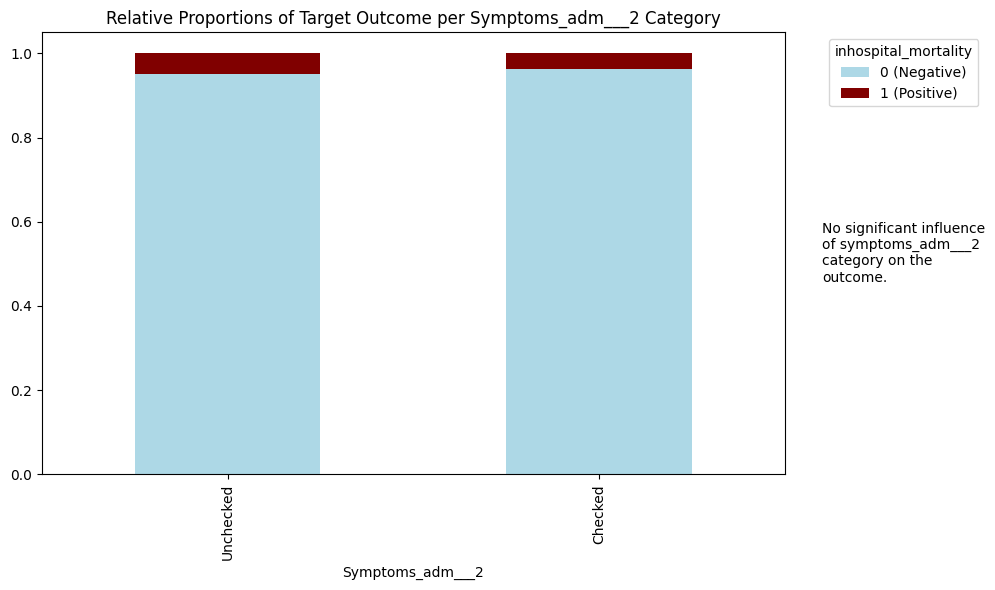

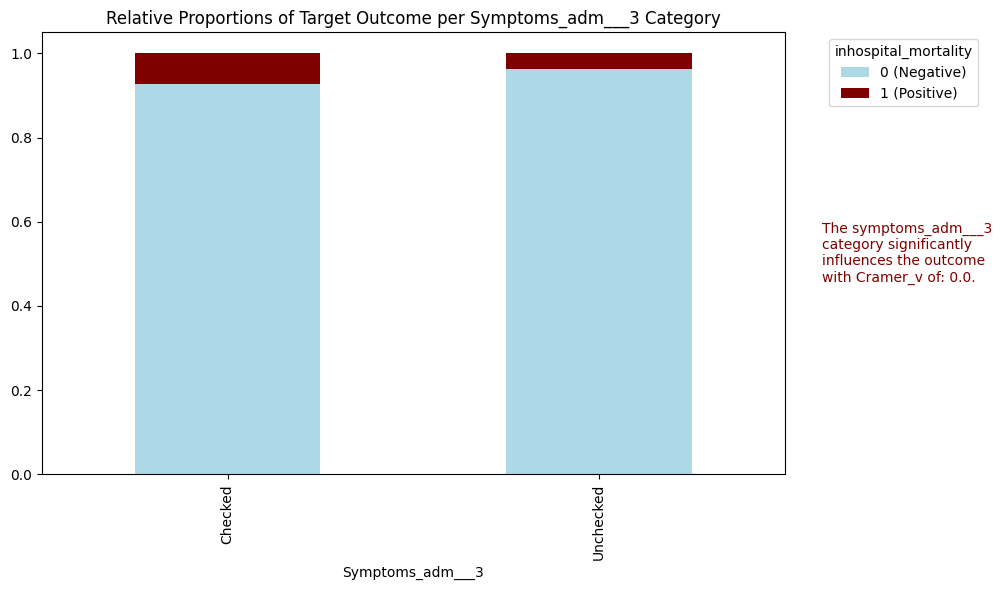

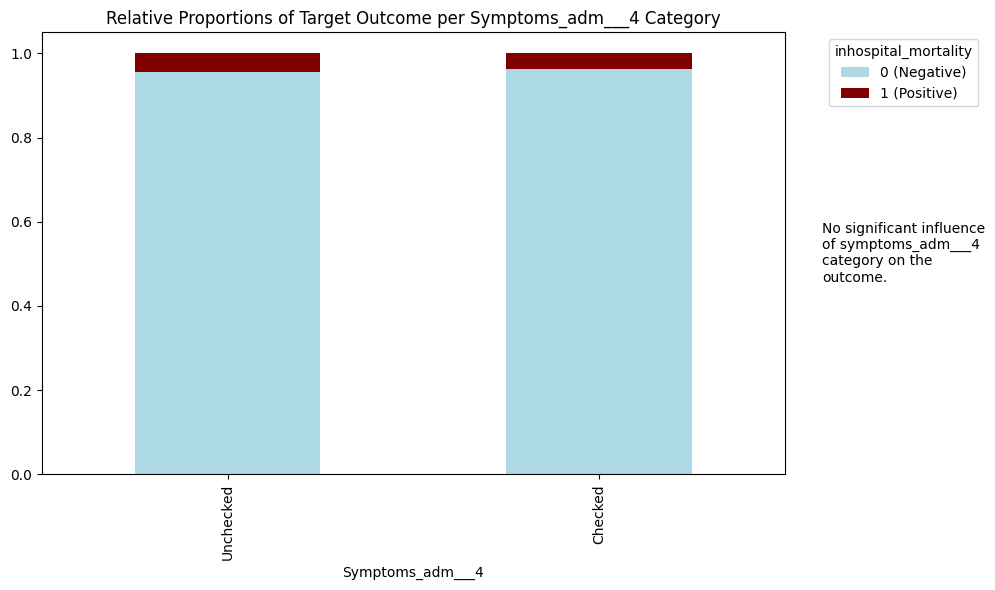

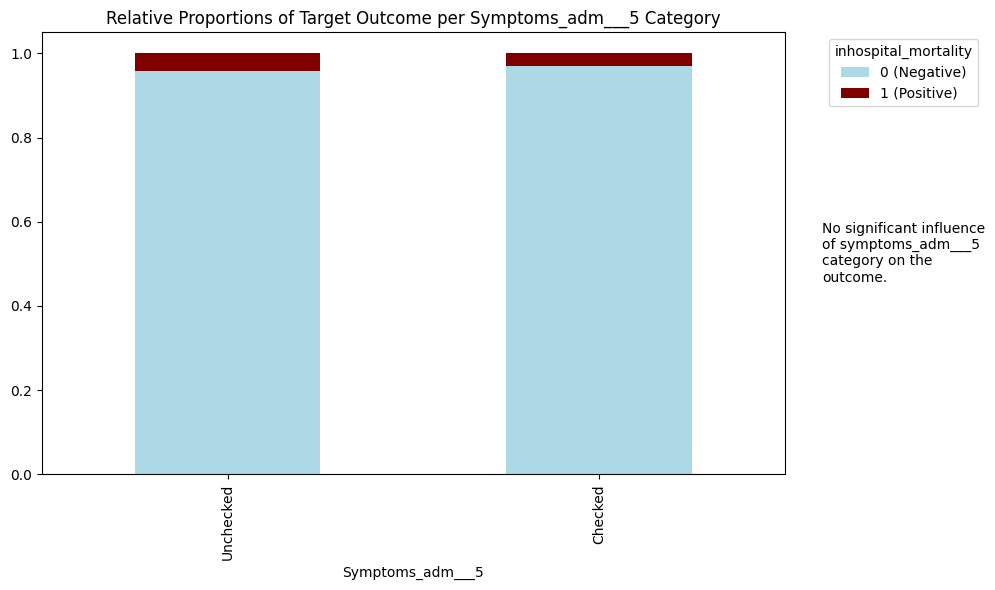

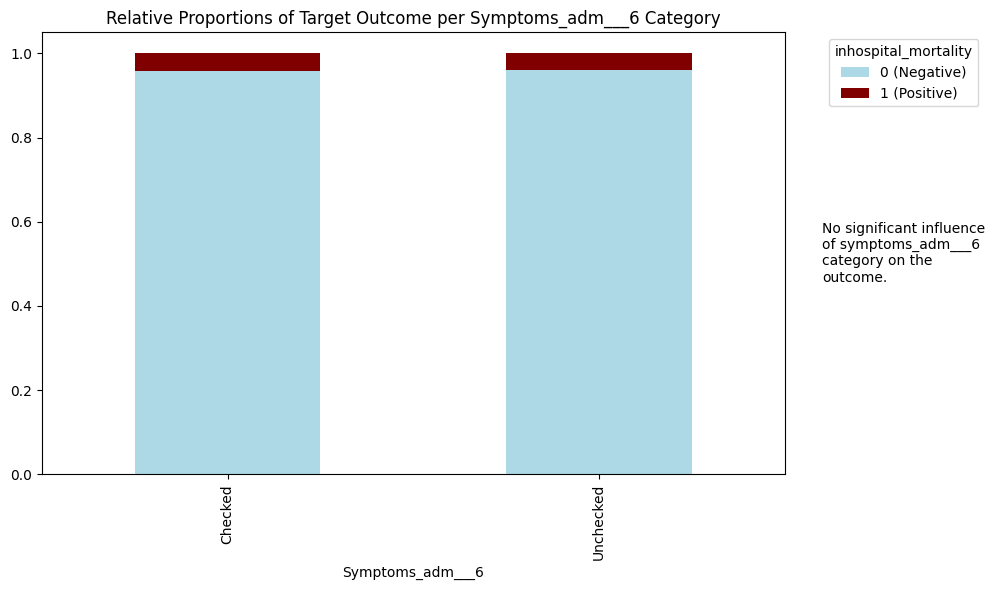

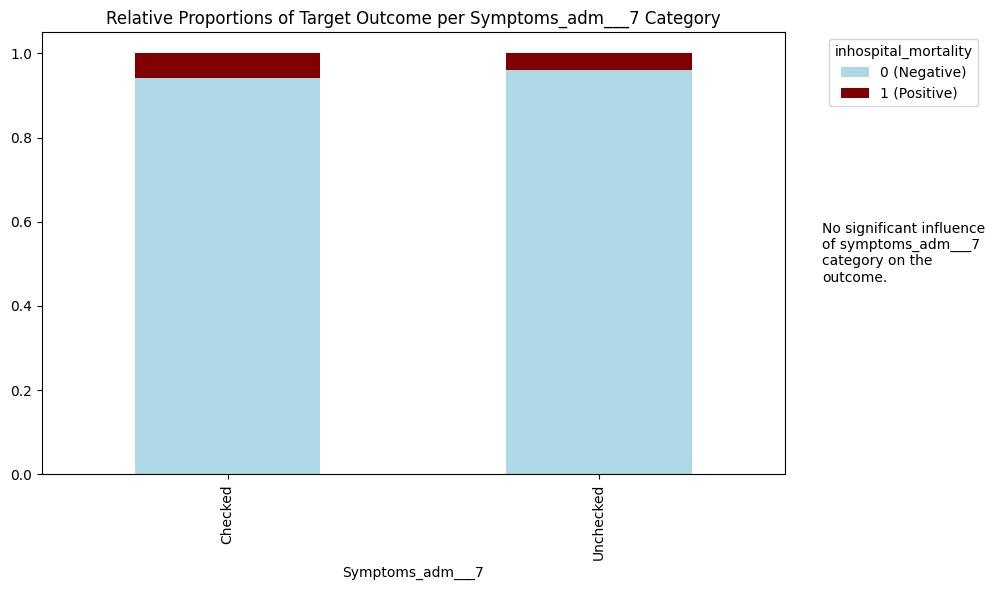

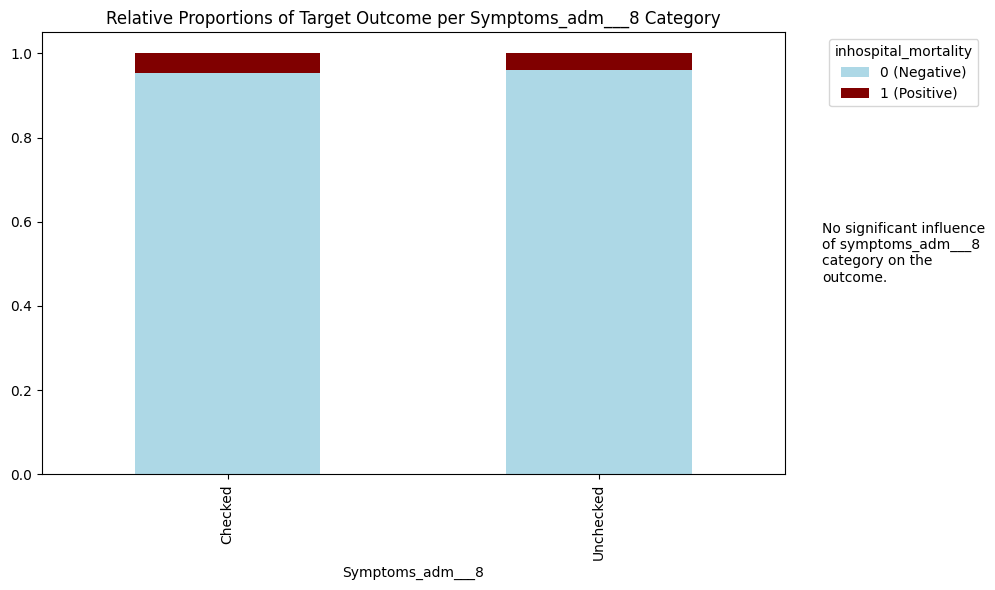

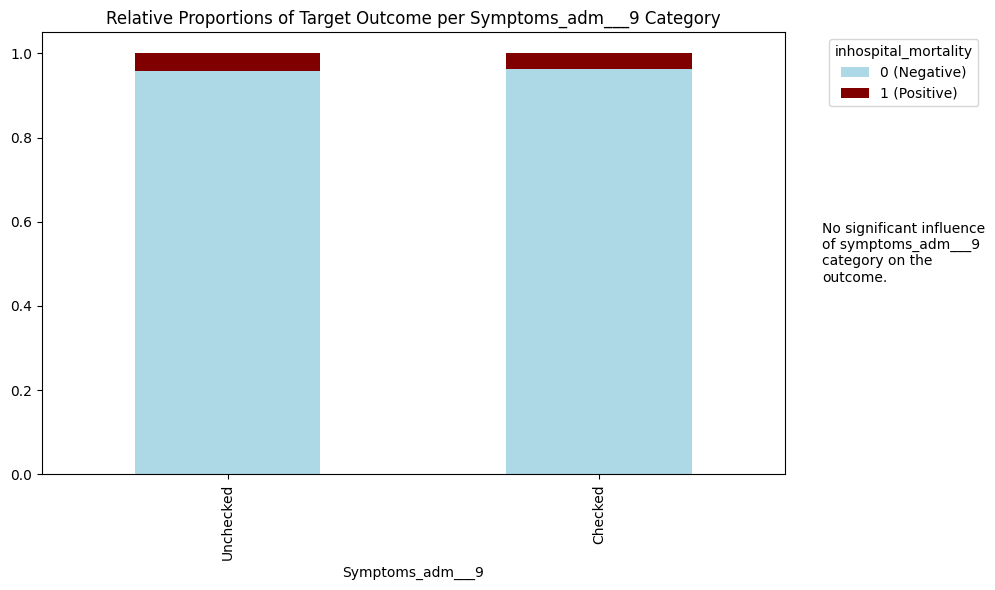

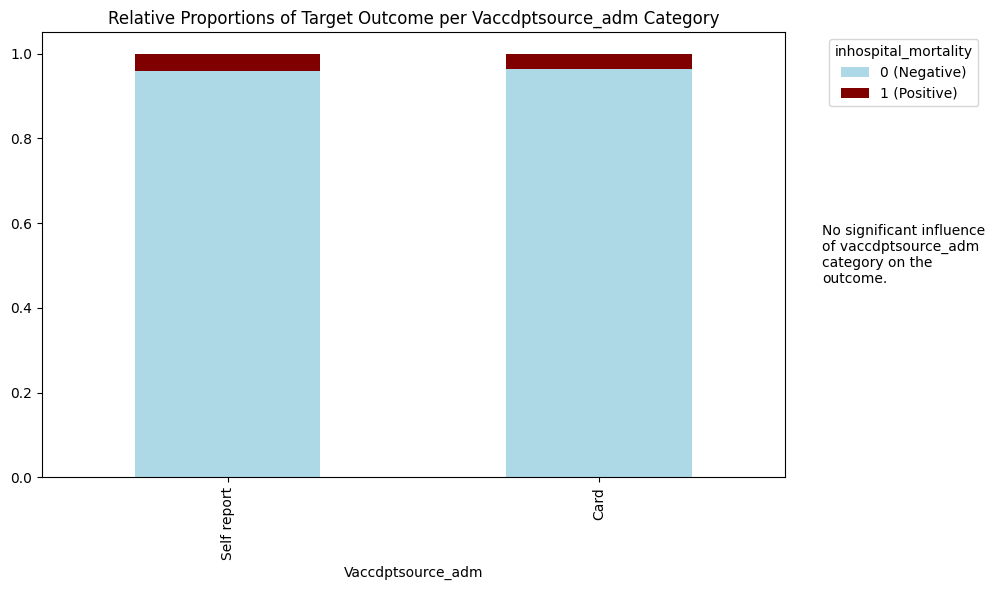

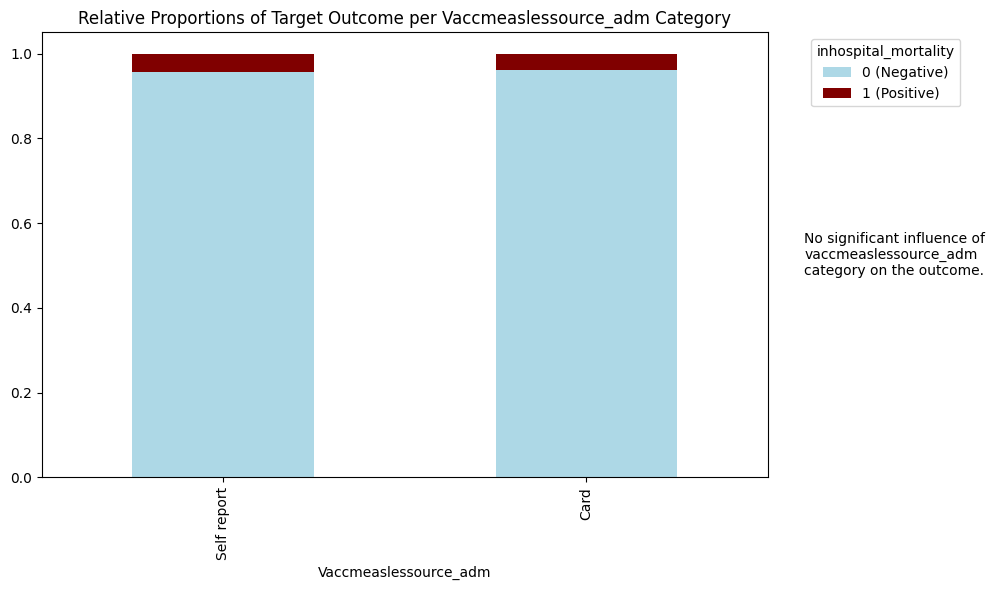

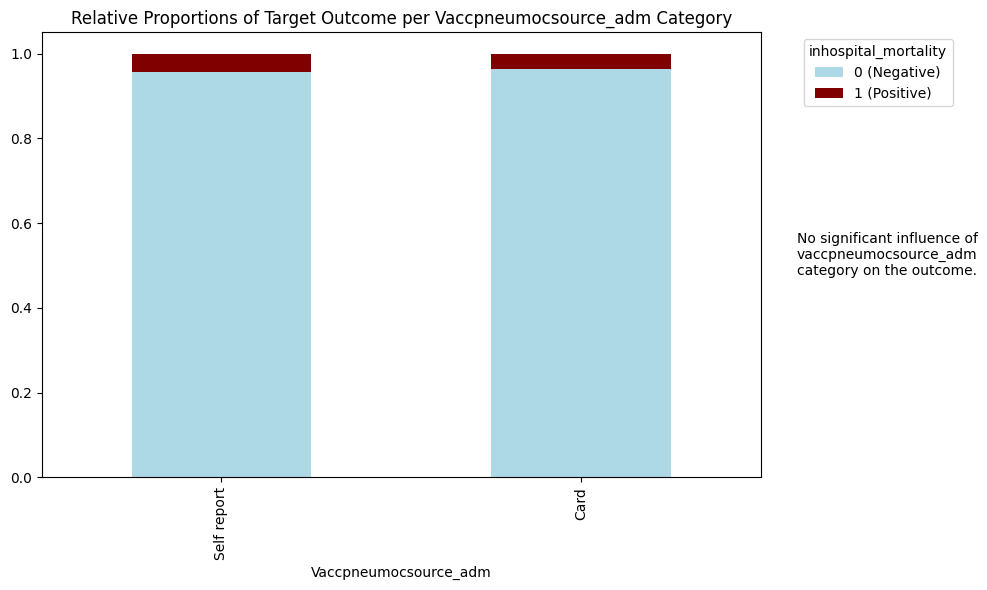

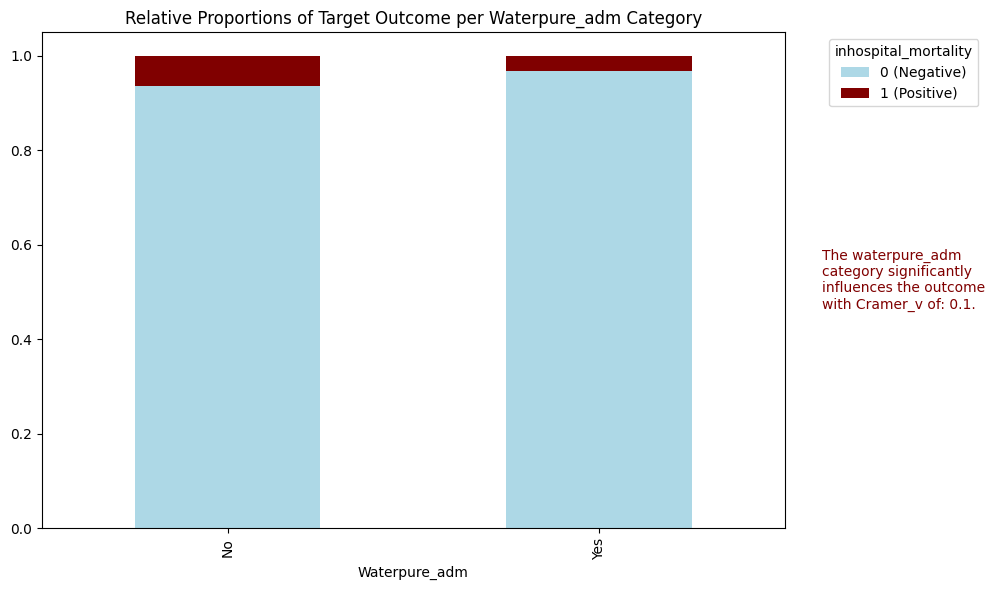

In [ ]:
for col in BINARY_FEATURES:
    try:
        categorical_analysis(col, color= ['#ADD8E6', '#800000'] )
    except Exception as e:
        print(f"{col} raised an error.\n{e}")

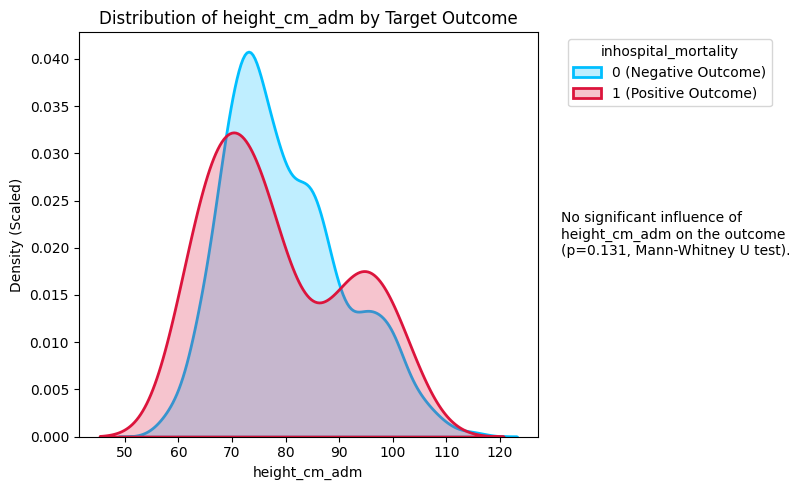

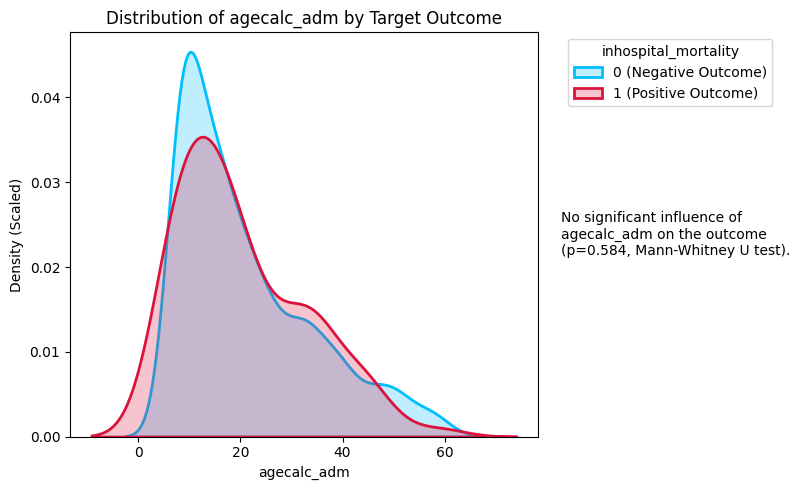

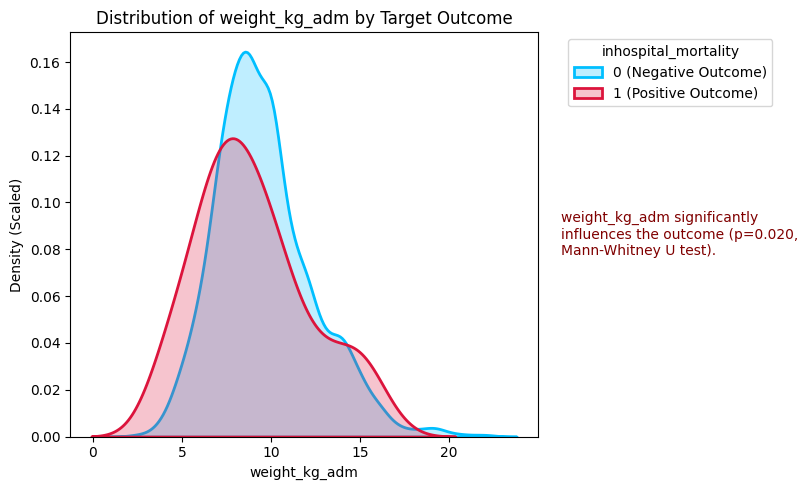

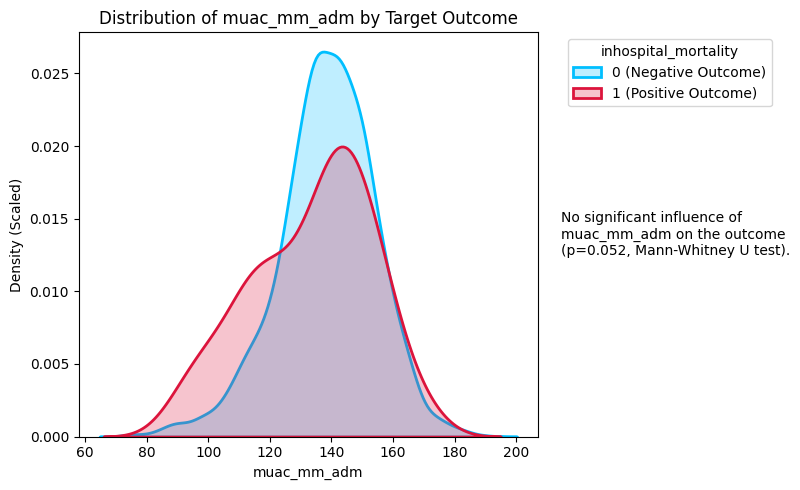

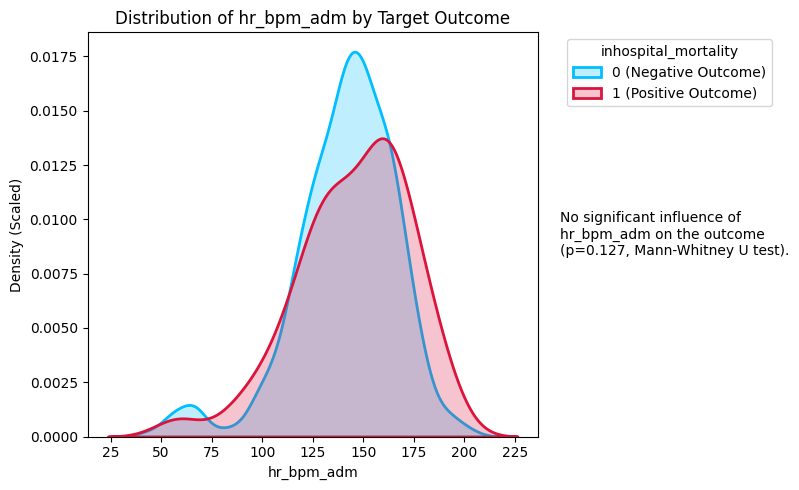

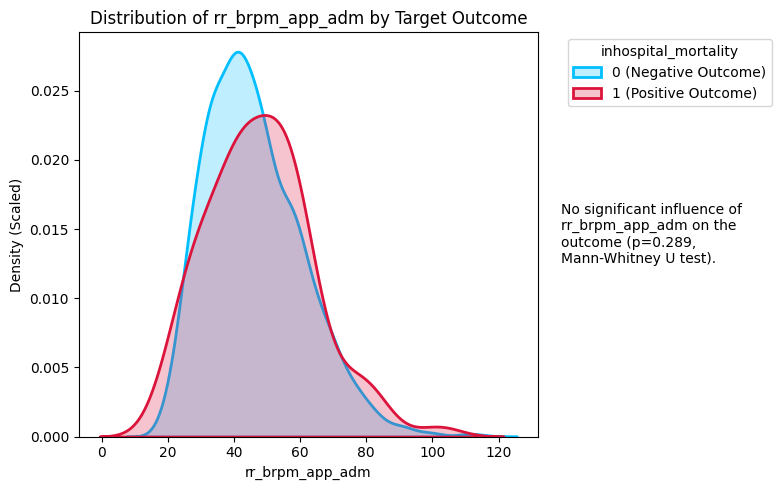

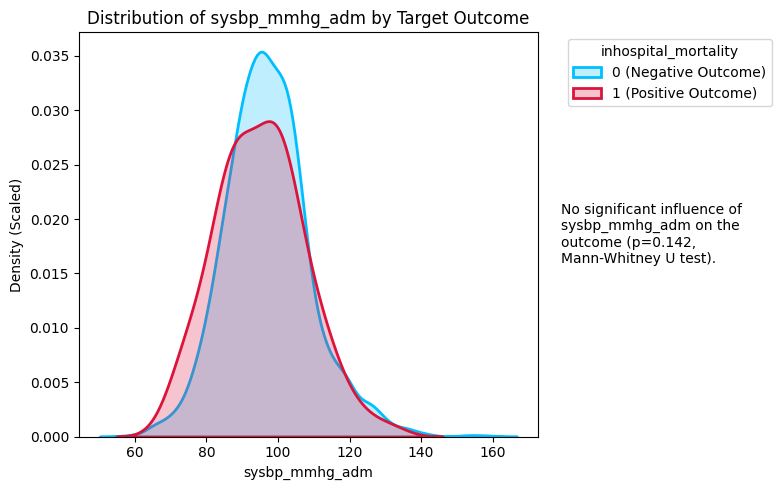

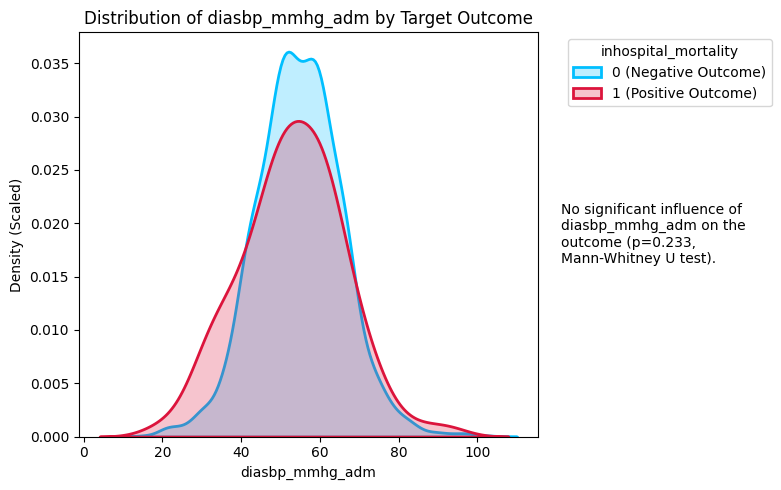

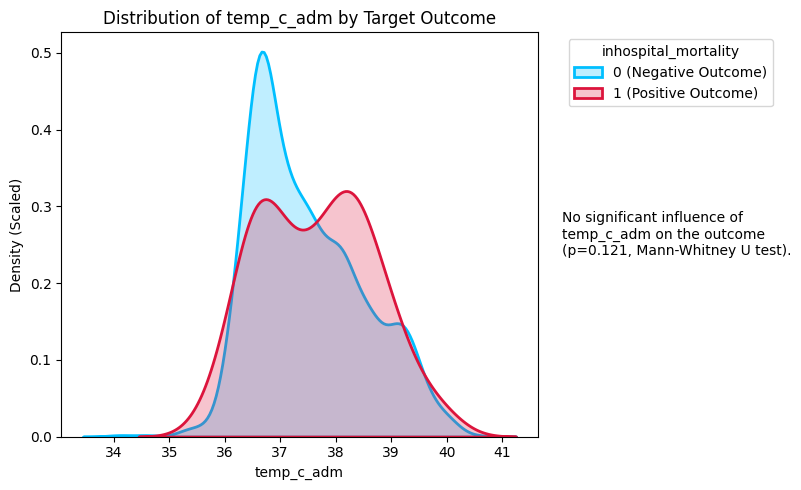

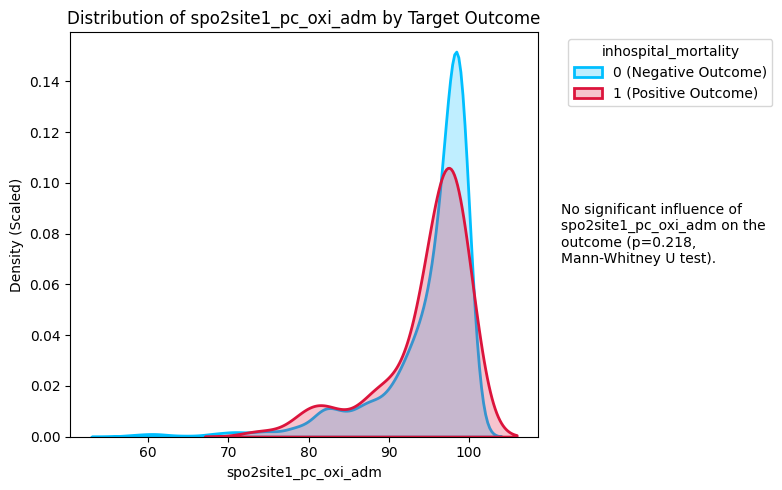

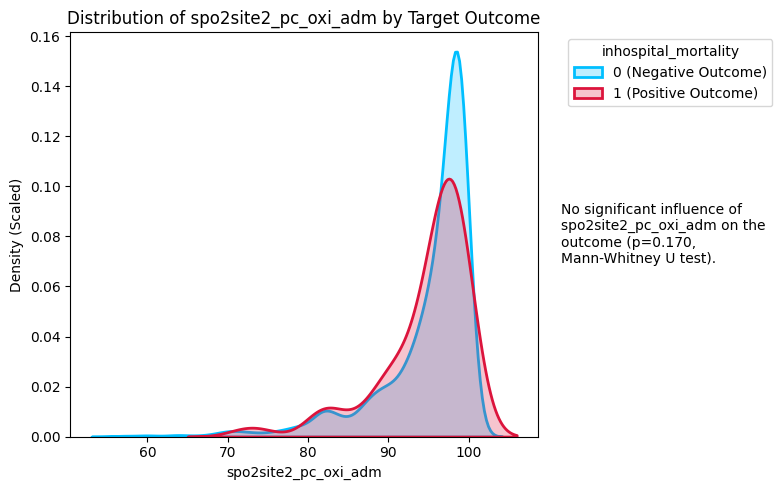

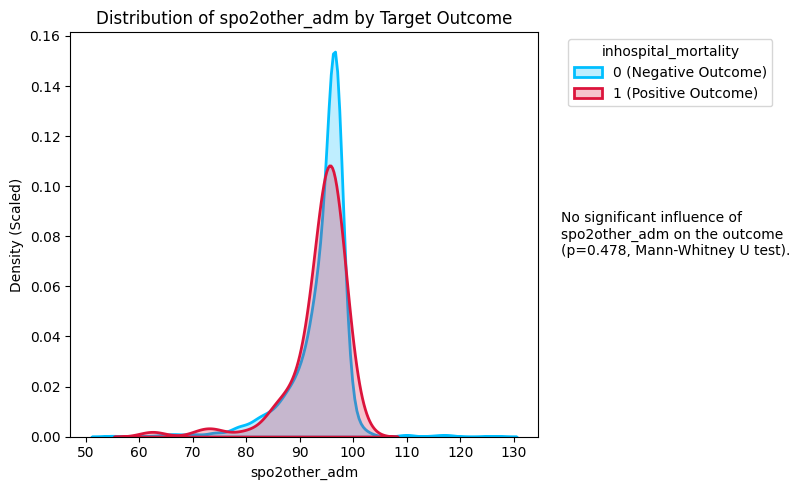

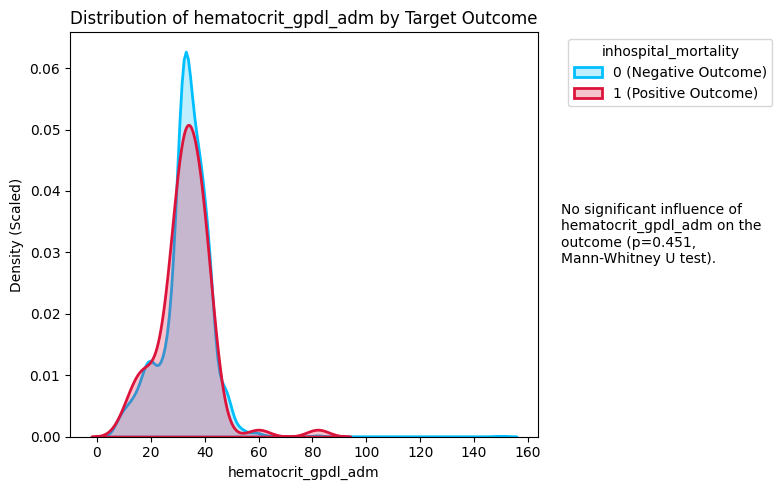

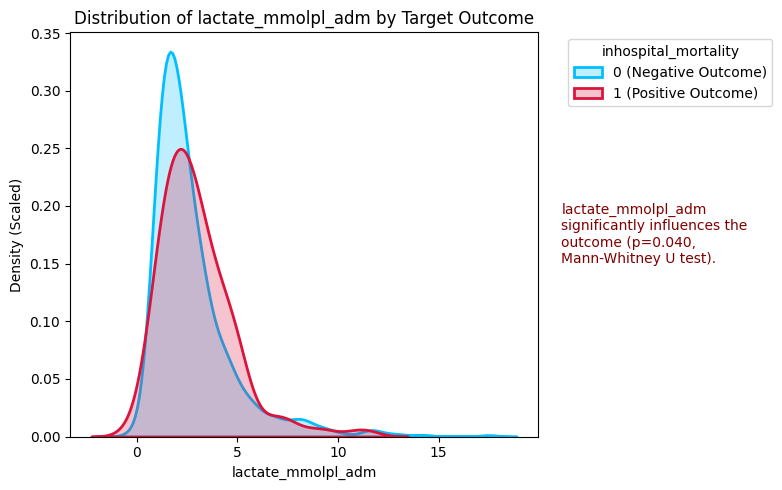

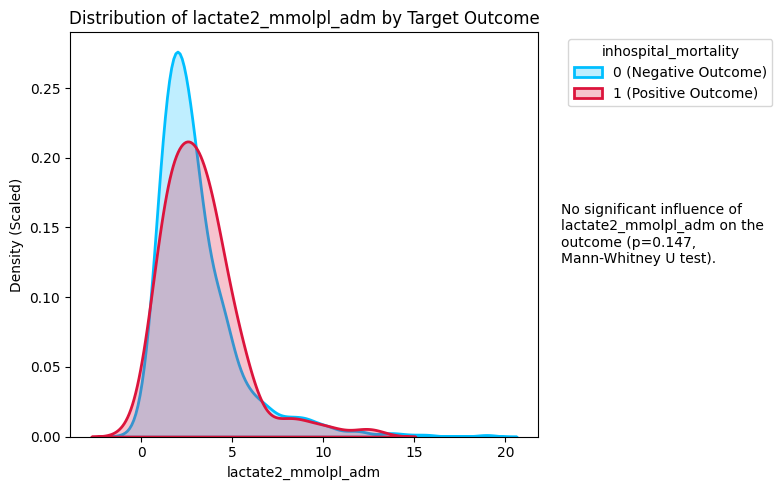

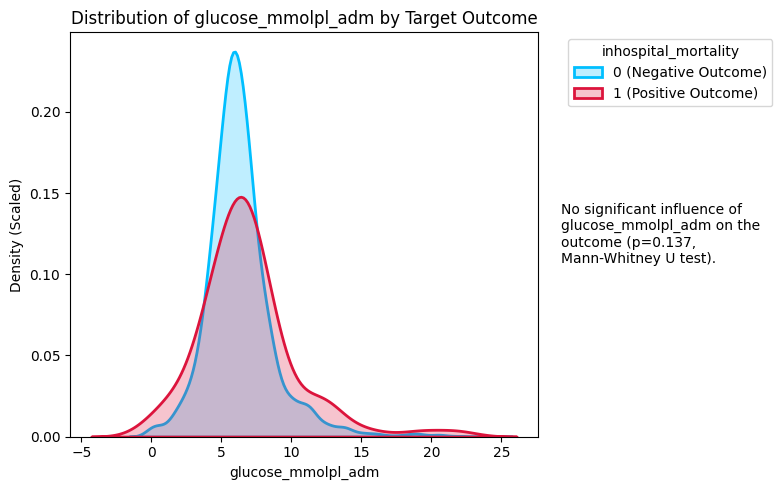

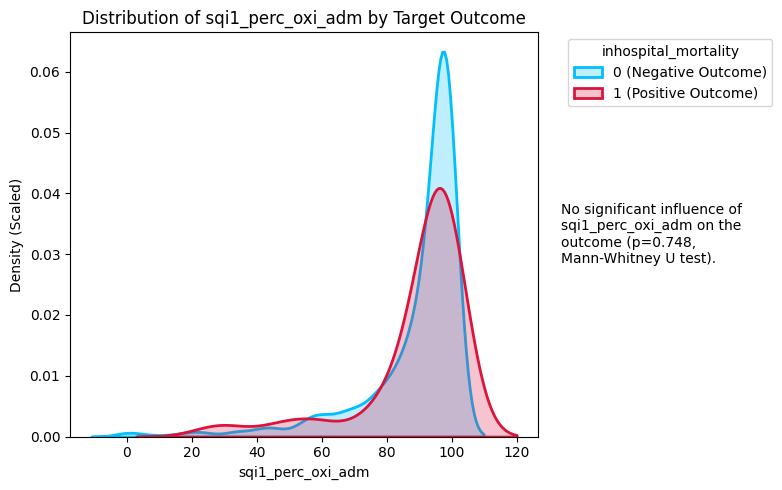

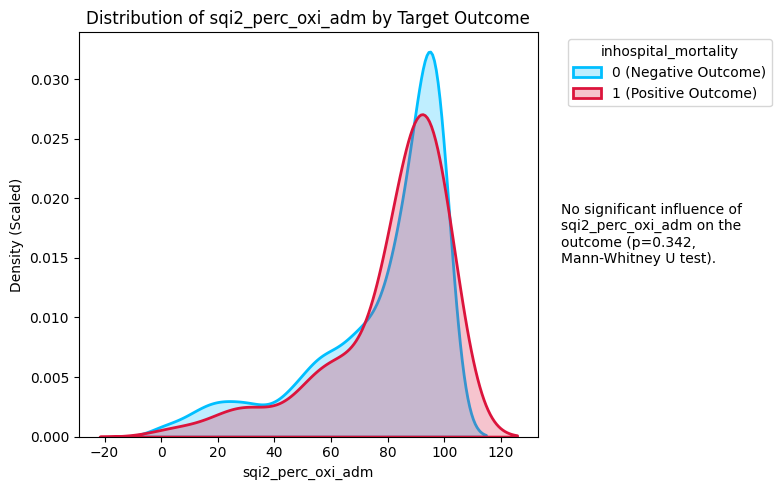

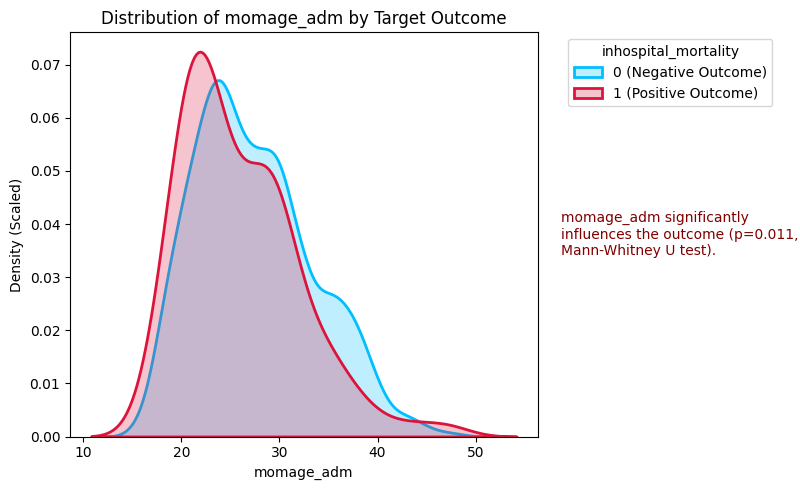

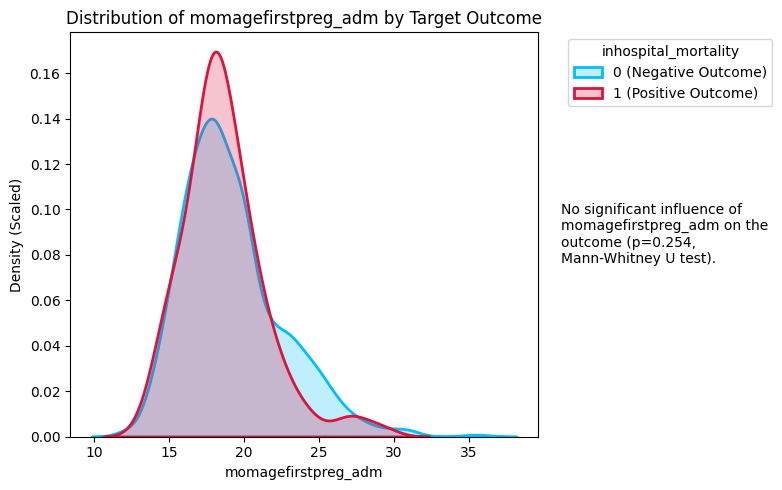

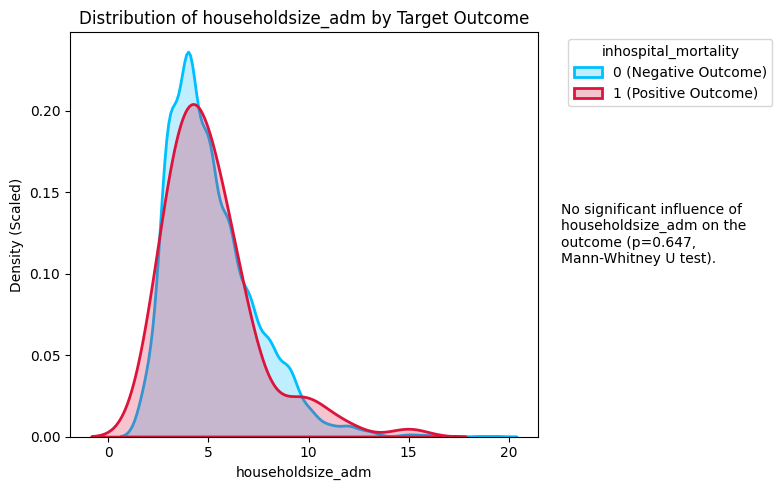

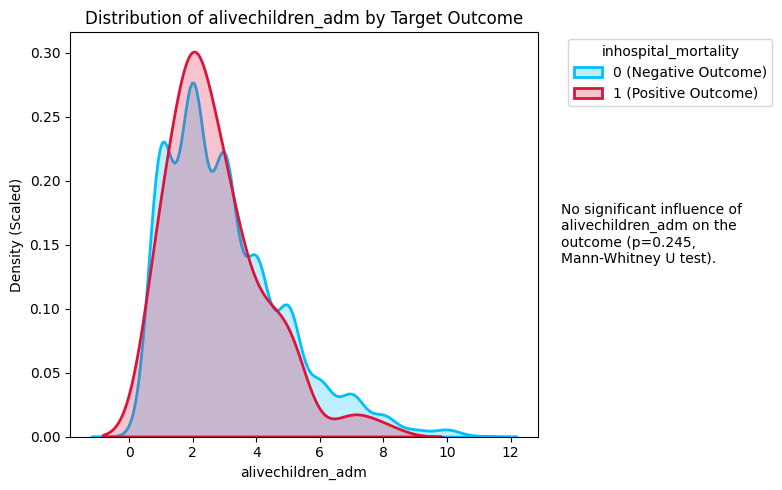

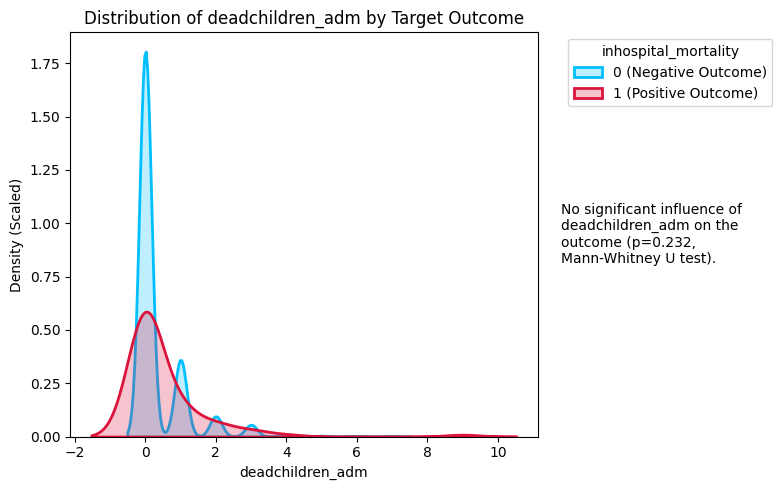

In [ ]:

for col in numeric_columns:  
    numerical_analysis(col, df, target)


## Observations of the most statistical significant features:
    * nonexclbreastfed_adm -> three-order ordinal -> Done. 
    * badhealthduration -> turn it to nominal data -> Done.


    * exclbreastfed - either turn it nominal or re-categorize
    * totalbreastfed - either turn it nominal or re-categorize
    * tobacco -> turn it into nominal data or turn it into 3 categories


    * oxygenavail
    * bcsmotor
    * bcsverbal
    * bednet_adm
    * feedingstatus
    * diarrhoea*
    * bcgscar
    * bcseye
    * respdistress
    * spo2onoxy
    * sympthons_adm_15
    * sympthons_adm_3
    * waterpure
    * weight
    * lactage_mmolpl

    * admitabx_adm_8 -> find other features that correlate with this one.